# Fixing errors in the iteration-7 research record: a runnable demo of `eval.py`

**Artifact `art_vjtPMtWGMjsB` (evaluation): iteration 8, Step 0 of the run *"prompt bans substitute, not just subtract"*.**

The run asks whether a prompt instruction or ban changes *which* algorithm an open-weight code model writes, and where inside the model that choice is made. For example, banning Dijkstra may make Qwen3-8B write Bellman-Ford. Iteration 7 ended with a long research report, and a blocking review found eleven problems in it (items **0a** to **0k**). This evaluation answers all eleven in the report itself. It generates nothing new. Every disputed number is re-derived from the raw rows of the iteration-7 experiments, and every correction is a machine-checked edit of the report.

What the full run produced:

| Output | Result |
|-|-|
| Report edits | 84, each marked `(iteration-8 correction)`; every `old_text` occurs exactly once and no two overlap |
| Value ledger | 141 values, each with the value printed in the report, the recomputed value and a status: 68 MATCH, 7 CORRECTED, 63 NEW, 3 CARRIED |
| Residual-claim lint | 35 hits before, 0 after |
| `audit/rederive.py` (stdlib, a separate code path) | 97 checks, 0 mismatches, 6/6 placebos fail as required |
| `audit/headline_check.py` | 11/11 headline numbers re-derived by different code paths, 5/5 placebos fail as required |

**The headline correction (0a).** The kth-smallest labeller did not recognise counting sort written with a dictionary. So the full-state exchange of the forced counting-sort source looked like 0/30 counting sort, when it is 29/30. The pooled kth-smallest recovery falls from 1.59 / 1.57 / 1.55 to **1.01 / 1.00 / 0.99** at ranks 1 / 4 / 16.

**What this notebook runs.** The artifact's own code, on the inputs bundled in `mini_demo_data.json`:
- the A5 recompute with exp33's slot bootstrap;
- all eleven review items;
- the apply test, the diff and the lint;
- both independent audits;
- the output writer.

The results are then compared with the published ones. Two parts of `eval.py` are not re-run here, and their published outputs are read instead:
- **S0** vendors and hashes the 33 input files of the full run;
- **A1 to A4** relabel the programs with a sandboxed program tracer and adjudicate them with two gated LLM judges.

The modules under `sections/` and `audit/` are written to disk unchanged by `%%writefile` cells, with one marked exception. `eval.py`'s own code runs in the cells; every line that differs from the script is marked `# notebook:`. No GPU and no API key are needed, and the whole notebook runs in about a minute after the install cell.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (eval.py, sections/s0_apply.py and sections/outputs.py log through it)
_pip('loguru==0.7.3')

# numpy, matplotlib — pre-installed on Colab, install locally only, at Colab's versions
# (the artifact pins numpy 2.5.4; its slot bootstrap uses only np.random.default_rng().integers and np.percentile)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
# ---- eval.py's import block, as in the script ----
from __future__ import annotations

import argparse
import json
import resource
import subprocess
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- added for the notebook: writing the bundled inputs, checking the outputs, figures ----
import csv
import hashlib
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/evaluation-7/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
src = data["source"]
print(data["description"], "\n")
print(f"dataset {data['dataset']!r}: {len(data['examples'])} cells, {src['labels_jsonl']['rows_kept']} of the "
      f"{src['labels_jsonl']['rows_total']} rows of exp33's data/labels.jsonl")
print(f"{len(data['files'])} other input files, {sum(len(v) for v in data['files'].values()) / 1e6:.1f} MB of text")
print("cells by task:", dict(Counter(e["task"] for e in data["examples"])))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Bundled input of code_demo.ipynb, the demo of eval.py of the iteration-8 record repair (art_vjtPMtWGMjsB). 'examples' are the labelled program cells of the DAS experiment (art_veI9l_Rb9wDY data/labels.jsonl) that the A5 recompute, items 0a/0b and both audits read; 'files' are the other inputs as text, keyed by their path in the demo's repository layout; 'reference' holds the published outputs of the full run. 

dataset 'exp33_labelled_cells': 68 cells, 2040 of the 4500 rows of exp33's data/labels.jsonl
62 other input files, 3.8 MB of text
cells by task: {'T2': 25, 'T10': 25, 'T03': 18}


## Configuration

`eval.py` takes one argument, `--stages`, and sets one limit, `_limit_memory(gb=16.0)`. There is no sample count, epoch or model size to shrink. Every stage reads fixed raw rows and reproduces published numbers exactly, through exact tests and seeded bootstraps.

- **`STAGES`** picks the stages, in `eval.py`'s order:
  - `s0` vendors and hashes the inputs;
  - `a` runs stage A, whose A5 step is the recompute;
  - `b` to `k` are the review items (the item for 0a also runs under `a`);
  - `apply` applies the edits to the report;
  - `audit` runs the two independent audit scripts;
  - `out` writes `eval_out.json`.
- **The minimum is `"a"`**: stage A and item 0a, a few seconds.
- **The value below is the whole run minus `s0`.** `--stages all` adds `s0`, which hashes 33 input files, and the demo bundles only the ones its stages read. Without `s0`, `main()` reads `results/s0.json`, as the script does for any partial run. The demo bundles the full run's copy.
- `apply` refuses to run unless all eleven items `a` to `k` ran in the same pass, as in the script.
- **`MEMORY_GB`** is `_limit_memory`'s cap: an address-space limit of three times this value. In a notebook the cap stays on the kernel for the rest of the session; restarting the runtime lifts it.

The slot bootstrap (2,000 resamples, `default_rng(20261022)`) is fixed inside `sections/a_recompute.py`. It is exp33's own definition, and the A5 placebo requires the port to reproduce exp33's published intervals exactly, so it is not a tunable parameter.

In [5]:
# ---- tunable parameters (scaled up from the minimum "a" during testing) ----
STAGES = "a,b,c,d,e,f,g,h,i,j,k,apply,audit,out"   # minimum: "a"; original: --stages all (= "s0," + this)
MEMORY_GB = 16.0    # eval.py _limit_memory(gb=16.0): address-space cap of 3 x 16 GB (the original value)

## The bundled inputs, written where the original code reads them

The artifact reads the files of other artifacts through one constant, `DEP_ROOT` in `sections/common.py`. In the published repository each artifact is a folder, and the iteration-7 experiments sit next to this one. The demo rebuilds that layout under `demo_repo/`, with the artifact folder `gen_art_evaluation_7/` beside six `gen_art_experiment_*` folders. Each bundled file is written to its original path, so the original code reads it unchanged. `AII_DEP_ROOT`, the documented override, points `DEP_ROOT` there.

- **The dataset.** The 68 labelled program cells become exp33's `data/labels.jsonl`, 2,040 of its 4,500 rows. These are every cell the A5 recompute, items 0a and 0b and both audits read. Each cell is one task and arm, with 30 slots that share their random seeds across arms.
  - Rows are written back in their original file order, because the audit's slot-shuffle placebo depends on it.
  - Only kth-smallest rows keep their program text, since item 0a and both audits read only that.
- **Three other row files are cut** to the rows and fields their readers use (listed below). These are exp36's slot rows, exp38's dose-dial rows and exp37's program classes.
- **Every other file is whole.** Its sha256 is checked against the hash the full run recorded in `inputs/input_hashes.json`.
- **The outputs of the stages the demo does not re-run** go to `results/`, `tables/` and `audit/`, where those stages wrote them:
  - S0: `results/s0.json`;
  - A2 and A3: the labeller validation and the relabel;
  - A4: the adjudication, the judge gate and `tables/counting_sort_adjudication.csv`.

In [6]:
# notebook: stands in for stage S0's vendoring (sections/s0_apply.py stage_s0) and for the dependency folders on disk
DEMO_REPO = Path("demo_repo").resolve()               # the %%writefile cells below write into demo_repo/ as well
ROOT = DEMO_REPO / "gen_art_evaluation_7"             # the artifact folder: eval.py's ROOT
os.environ["AII_DEP_ROOT"] = str(DEMO_REPO)           # the documented DEP_ROOT override (sections/common.py, both audits)
for sub in ("sections", "audit", "results", "tables", "logs"):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
(ROOT / "sections" / "__init__.py").write_text("")

# the dataset: exp33's labelled cells -> gen_art_experiment_33/data/labels.jsonl, in the original row order
rows_out = sorted((r for e in data["examples"] for r in e["rows"]), key=lambda r: r["line"])
lab_p = DEMO_REPO / "gen_art_experiment_33" / "data" / "labels.jsonl"
lab_p.parent.mkdir(parents=True, exist_ok=True)
lab_p.write_text("".join(json.dumps({k: v for k, v in r.items() if k != "line"}) + "\n" for r in rows_out))

# every other input, as text, at its path in the repository layout
for rel, text in data["files"].items():
    p = DEMO_REPO / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(text, encoding="utf-8")

# integrity: each whole file against the sha256 the full run recorded (inputs/input_hashes.json)
rec = json.loads((ROOT / "inputs" / "input_hashes.json").read_text())
folder = {aid: f for f, aid in src["dependencies"].items() if f.startswith("gen_art_experiment")}
recorded = {f"{folder[aid]}/{rel}": h for aid, fs in rec["dependencies"].items() for rel, h in fs.items()}
recorded |= {f"gen_art_evaluation_7/inputs/eval6/{f}": h for f, h in rec["eval6"].items()}
recorded["gen_art_evaluation_7/inputs/report/current_report.md"] = rec["report"]["sha256"]
n_ok = 0
for rel in data["files"]:
    if rel in recorded:
        same = hashlib.sha256((DEMO_REPO / rel).read_bytes()).hexdigest() == recorded[rel]
        n_ok += same
        if not same:
            cut = src["cuts"].get(rel)
            print(f"  cut   {rel}: {cut['rows_kept']} of {cut['rows_total']} rows, fields {cut['fields_kept']}" if cut
                  else f"  DIFFERENT {rel}")
print(f"{n_ok} whole input files have the sha256 recorded by the full run")
print(f"labels.jsonl: {len(rows_out)} rows written; the full file's sha256 "
      f"{'equals' if src['labels_jsonl']['sha256_full_file'] == src['labels_jsonl']['recorded_sha256'] else 'differs from'} the recorded one")
print("outputs of S0 and A1-A4 from the full run:",
      sorted(str(Path(r).relative_to("gen_art_evaluation_7")) for r in data["files"] if r.startswith("gen_art_evaluation_7/results/")))

  cut   gen_art_experiment_36/data/samples.jsonl: 400 of 5360 rows, fields ['key', 'task', 'template', 'arm', 'k', 'stage', 'design', 'label', 'passed', 'Y']
  cut   gen_art_experiment_38/data/raw_g2dose.jsonl: 150 of 1450 rows, fields ['row_id', 'cell', 'method', 'lambda', 'template', 'slot', 'ukey', 'prefix_len', 'finish_reason', 'n_new_tokens']
  cut   gen_art_experiment_37/results/program_classes.json: 1870 of 1870 rows, fields ['final_class', 'is_first_of_distinct', 'merged_cluster_id', 'named_algorithm']
31 whole input files have the sha256 recorded by the full run
labels.jsonl: 2040 rows written; the full file's sha256 equals the recorded one
outputs of S0 and A1-A4 from the full run: ['results/a2_validation.json', 'results/a3_high_other_cells.json', 'results/a3_relabel.json', 'results/a4_adjudication.json', 'results/s0.json']


## `sections/common.py`: paths, exact statistics, correction records and the lint

This module is written once and imported by every other one. It is unchanged.

- **Paths.** Everything hangs off `ROOT`, the folder above `sections/`. The other artifacts' files come through `dep(short, rel)`, for example `dep("exp33", "data/labels.jsonl")`.
- **Exact statistics, standard library only:**
  - the Clopper-Pearson interval (from the regularised incomplete beta, by bisection);
  - the Wilson and Newcombe intervals;
  - the exact McNemar and two-sided Fisher tests;
  - Spearman with average ranks, and its fixed-seed bootstrap;
  - Cohen's kappa.
- **`value(name, recorded, recomputed, status, source, tolerance, item, note)`** appends one traced value to `VALUES`. The status is one of four:
  - `MATCH`: recorded and recomputed agree within the tolerance, which is asserted;
  - `CORRECTED`: the report printed a different value;
  - `NEW`: the report printed no value;
  - `CARRIED`: the value is quoted, not recomputed.
- **`edit(id, item, section, old, new, kind)`** builds one machine-checkable edit of the report.
- **`lint()`** counts the 28 contradicted phrases of `LINT_PHRASES`, plus any undefined `Step K` tag.

In [7]:
%%writefile demo_repo/gen_art_evaluation_7/sections/common.py
#!/usr/bin/env python3
"""Shared helpers of the iteration-8 record repair: paths, hashing, exact intervals and tests, average-rank Spearman,
fixed-seed bootstraps, the correction-record builder and the residual-claim lint. Written once (STEP S0) and imported
by every section module."""

from __future__ import annotations

import hashlib
import json
import math
import re
from collections import Counter
from pathlib import Path
from typing import Any, Iterable

import os

ROOT = Path(__file__).resolve().parents[1]
# Inputs produced by other artifacts are read through ONE constant, DEP_ROOT: the folder that holds the iteration-7
# artifact folders (named by folder name, e.g. gen_art_experiment_33, or by artifact id, e.g. art_veI9l_Rb9wDY).
# Default: the run layout this was executed in (<run>/3_invention_loop/iter_7/gen_art, found relative to this folder);
# in the published repository each artifact is a sibling folder, so DEP_ROOT falls back to this folder's parent.
# Override with the environment variable AII_DEP_ROOT.
_RUN_LAYOUT = ROOT.parents[2] / "iter_7" / "gen_art"
DEP_ROOT = Path(os.environ.get("AII_DEP_ROOT") or (_RUN_LAYOUT if _RUN_LAYOUT.exists() else ROOT.parent))
ITER7 = DEP_ROOT
# the report to correct is vendored in inputs/report/; the source below is only read if that copy is missing
REPORT_SRC = Path(os.environ.get("AII_REPORT_SRC", ROOT.parents[1] / "gen_strat" / "current_report.md"))
REPORT = ROOT / "inputs" / "report" / "current_report.md"
EVAL6_DIR = ROOT / "inputs" / "eval6"
BENCH_ROOT = ROOT / "inputs" / "bench_T03"
RESULTS = ROOT / "results"
TABLES = ROOT / "tables"
AUDIT = ROOT / "audit"
READ_DATE = "2026-10-23"

# artifact id -> folder name under ITER7 (declared dependencies plus the evaluation read by absolute path)
ARTIFACTS = {
    "art_veI9l_Rb9wDY": "gen_art_experiment_33",
    "art_pHL7LWNhpcCS": "gen_art_experiment_34",
    "art_MZAfDPVhM6Ui": "gen_art_experiment_35",
    "art_8O5eaNc5gxJs": "gen_art_experiment_36",
    "art_VhaHGe7SxV95": "gen_art_experiment_37",
    "art_HY7uYZz-OjRW": "gen_art_experiment_38",
    "art_LzP2qPwUrANz": "gen_art_evaluation_6",
}
SHORT = {"art_veI9l_Rb9wDY": "exp33", "art_pHL7LWNhpcCS": "exp34", "art_MZAfDPVhM6Ui": "exp35",
         "art_8O5eaNc5gxJs": "exp36", "art_VhaHGe7SxV95": "exp37", "art_HY7uYZz-OjRW": "exp38",
         "art_LzP2qPwUrANz": "eval6"}
BY_SHORT = {v: k for k, v in SHORT.items()}


def dep(short: str, rel: str = "") -> Path:
    """Path of a file inside a dependency workspace (short name exp33..exp38, eval6), under DEP_ROOT by folder name or,
    failing that, by artifact id."""
    aid = BY_SHORT[short]
    base = DEP_ROOT / ARTIFACTS[aid]
    if not base.exists() and (DEP_ROOT / aid).exists():
        base = DEP_ROOT / aid
    return base / rel


def src_ref(short: str, rel: str, key: str = "") -> str:
    """Source string '<artifact_id>:<relative path>#<key>' used in every correction record."""
    return f"{BY_SHORT[short]}:{rel}" + (f"#{key}" if key else "")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in Path(p).read_text().splitlines() if l.strip()]


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=1, ensure_ascii=False, default=_default))


def _default(o: Any) -> Any:
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if hasattr(o, "item"):
        return o.item()
    raise TypeError(f"not serialisable: {type(o)}")


def write_csv(p: Path, rows: list[dict[str, Any]], cols: list[str] | None = None) -> None:
    import csv
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    cols = cols or (list(rows[0].keys()) if rows else [])
    with p.open("w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if r.get(k) is None else r.get(k)) for k in cols})


# ------------------------------------------------------------------------------------------------ exact statistics
def _betacf(a: float, b: float, x: float) -> float:
    MAXIT, EPS, FPMIN = 300, 3e-16, 1e-300
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
    h = d
    for m in range(1, MAXIT + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
        c = 1.0 + aa / c
        c = c if abs(c) > FPMIN else FPMIN
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        d = 1.0 / (d if abs(d) > FPMIN else FPMIN)
        c = 1.0 + aa / c
        c = c if abs(c) > FPMIN else FPMIN
        de = d * c
        h *= de
        if abs(de - 1.0) < EPS:
            break
    return h


def betainc(a: float, b: float, x: float) -> float:
    """Regularised incomplete beta I_x(a, b)."""
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    lbt = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1.0 - x)
    bt = math.exp(lbt)
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b


def beta_ppf(q: float, a: float, b: float) -> float:
    lo, hi = 0.0, 1.0
    for _ in range(200):
        mid = (lo + hi) / 2
        if betainc(a, b, mid) < q:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    lo = 0.0 if k == 0 else beta_ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta_ppf(1 - alpha / 2, k + 1, n - k)
    return [lo, hi]


def wilson(k: int, n: int, z: float = 1.959963984540054) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar (binomial on the discordant pairs)."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return min(1.0, 2 * p)


def newcombe_diff(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe hybrid score interval for p1 - p2 (method 10)."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return [d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)]


def fisher_exact_two_sided(a: int, b: int, c: int, d: int) -> float:
    """Two-sided Fisher exact test on [[a, b], [c, d]] (sum of tables no more likely than the observed)."""
    r1, r2, c1 = a + b, c + d, a + c
    n = r1 + r2

    def pmf(x: int) -> float:
        return math.comb(r1, x) * math.comb(r2, c1 - x) / math.comb(n, c1)

    p0 = pmf(a)
    lo, hi = max(0, c1 - r2), min(r1, c1)
    return min(1.0, sum(pmf(x) for x in range(lo, hi + 1) if pmf(x) <= p0 * (1 + 1e-7)))


def avg_ranks(x: list[float]) -> list[float]:
    order = sorted(range(len(x)), key=lambda i: x[i])
    r = [0.0] * len(x)
    i = 0
    while i < len(order):
        j = i
        while j + 1 < len(order) and x[order[j + 1]] == x[order[i]]:
            j += 1
        avg = (i + j) / 2 + 1
        for t in range(i, j + 1):
            r[order[t]] = avg
        i = j + 1
    return r


def pearson(a: list[float], b: list[float]) -> float:
    n = len(a)
    ma, mb = sum(a) / n, sum(b) / n
    sa = math.sqrt(sum((x - ma) ** 2 for x in a))
    sb = math.sqrt(sum((y - mb) ** 2 for y in b))
    if sa == 0 or sb == 0:
        return float("nan")
    return sum((x - ma) * (y - mb) for x, y in zip(a, b)) / (sa * sb)


def spearman(a: list[float], b: list[float]) -> float:
    return pearson(avg_ranks(a), avg_ranks(b))


def bootstrap_spearman(a: list[float], b: list[float], n_boot: int = 2000, seed: int = 20261023) -> list[float]:
    import random
    rng = random.Random(seed)
    n = len(a)
    vals = []
    for _ in range(n_boot):
        idx = [rng.randrange(n) for _ in range(n)]
        v = spearman([a[i] for i in idx], [b[i] for i in idx])
        if not math.isnan(v):
            vals.append(v)
    vals.sort()
    return [vals[int(0.025 * len(vals))], vals[min(len(vals) - 1, int(0.975 * len(vals)))]]


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    if pe >= 1.0:
        return 1.0 if po == 1.0 else 0.0
    return (po - pe) / (1 - pe)


def fmt(x: float | None, nd: int = 2) -> str:
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "-"
    return f"{x:.{nd}f}"


# ------------------------------------------------------------------------------------------------ correction records
VALUES: list[dict[str, Any]] = []


def value(name: str, recorded: Any, recomputed: Any, status: str, source: str, tolerance: float | str = 0.005,
          item: str = "", note: str = "") -> dict[str, Any]:
    """One traced value: recorded (as printed in current_report.md), recomputed (from the raw file), status in
    MATCH | CORRECTED | NEW | CARRIED. MATCH requires |recorded - recomputed| <= tolerance for numbers."""
    assert status in ("MATCH", "CORRECTED", "NEW", "CARRIED"), status
    rec = {"name": name, "item": item, "recorded": recorded, "recomputed": recomputed, "status": status,
           "tolerance": tolerance, "source": source}
    if note:
        rec["note"] = note
    if status == "MATCH" and isinstance(recorded, (int, float)) and isinstance(recomputed, (int, float)):
        assert abs(float(recorded) - float(recomputed)) <= float(tolerance) + 1e-12, (name, recorded, recomputed)
    VALUES.append(rec)
    return rec


def auto_status(recorded: float | None, recomputed: float, tol: float = 0.005) -> str:
    if recorded is None:
        return "NEW"
    return "MATCH" if abs(recorded - recomputed) <= tol + 1e-12 else "CORRECTED"


SUFFIX = " (iteration-8 correction)"


def edit(cid: str, item: str, section: str, old: str, new: str, kind: str = "prose", why: str = "",
         values: list[str] | None = None) -> dict[str, Any]:
    """One machine-checkable edit of the report. Prose edits must end with the iteration-8 suffix."""
    return {"id": cid, "item": item, "section": section, "kind": kind, "old_text": old, "new_text": new, "why": why,
            "value_names": values or []}


# ------------------------------------------------------------------------------------------------ residual-claim lint
LINT_PHRASES = [
    "above the 35",
    "pending the 2x2 of Step K",
    "the controls that failed for Qwen3-8B in Section 7.3 pass here",
    "on two tasks it carries it more cleanly",
    "on two tasks it routes more cleanly",
    "Categorical on shortest path and kth smallest",
    "counting sort 30/30 under DAS",
    "Recovery 0.73 to 1.71",
    "at the random 95th percentile",
    "passes all three controls",
    "dose dial 42 correct BFS against 35",
    "beats the explicit instruction",
    "All five ban templates lie outside it",
    "lies inside, at the 94th percentile",
    "the full state exchange gives 0 (29 programs labelled other",
    "The margin at the decision predicts what moves the algorithm",
    # extensions found while reading (iteration-8 executor)
    "pooled over sources it lies between 0.73 and 1.71",
    "while the full state exchange lands none",
    "transfer 0.47 on shortest path, 0.70 on connected components and 0.60 on kth smallest of the full state effect",
    "permuted labels transfer 0.47 to 0.70 of its effect",
    "the absolute unit's peaky profile on a few task tokens carries the effect",
    "where it exists its margin predicts the effect of random pushes",
    "and the fork margin under a random push predicts the effect of the push",
    "This time the controls hold.",
    "at a rate no arm that draws single samples approaches",
    "| COLM, not ICML 2026 |",
    "at a rate no knob applied to single samples approaches",
    "admits a fit 0.92 as good",
]


def lint(text: str, phrases: Iterable[str] = LINT_PHRASES) -> dict[str, Any]:
    """Count every contradicted phrase with its line numbers. Also flags an undefined 'Step K'."""
    lines = text.split("\n")
    out = {}
    for ph in phrases:
        hits = [i + 1 for i, l in enumerate(lines) if ph in l]
        out[ph] = {"count": sum(l.count(ph) for l in lines), "lines": hits}
    sk = [i + 1 for i, l in enumerate(lines) if re.search(r"\bStep K\b", l)]
    defined = any("Step K" in l and "dose-unit experiment" in l for l in lines)
    out["__undefined_step_k__"] = {"count": 0 if (defined or not sk) else len(sk), "lines": [] if defined else sk}
    return out


def lint_total(res: dict[str, Any]) -> int:
    return sum(v["count"] for v in res.values())

Writing demo_repo/gen_art_evaluation_7/sections/common.py


## `sections/a_recompute.py`: STEP A5, exp33's recovery statistics ported line for line

This module recomputes what the relabel touches, with the DAS experiment's own definitions (exp33 `src/analysis7.py`). In each cell, a program counts for algorithm Y only if it **passes every hidden test** and is **labelled Y**. The arms:

| Arm | What it is |
|-|-|
| `BASE_W5`, `BASE_PAD` | the base prompt with no edit: the fifth ban template, or the padded neutral twin |
| `FULL_ban_*`, `FULL_F_<Y>` | the **full-state exchange**: the whole hidden state at the site is swapped in from the source prompt (a ban, or a prompt that forces algorithm Y) |
| `DASLY_<source>_k<r>` | the **rank-r DAS edit**: only an r-dimensional subspace is swapped, fitted on whole-program likelihood |
| `RAND_*` | a random subspace of the same rank (control) |
| `PERMLY_*` | DAS fitted on permuted labels (control) |

- **Recovery** of a source is `(DAS count - base count) / (full count - base count)`.
- **Pooled recovery** is a ratio of sums over sources: the numerator sums `DAS - base`, and the denominator sums `full - base`.
- **The interval** comes from a slot-cluster bootstrap: the 30 slots are resampled with 2,000 draws of `default_rng(20261022)`, and the interval is the 2.5th to 97.5th percentile.
- **The placebo comes first.** Under the old labels, `run()` must reproduce exp33's published `per_k` recovery and its interval exactly, on all three tasks. Only then are the new kth-smallest labels used.

In [8]:
%%writefile demo_repo/gen_art_evaluation_7/sections/a_recompute.py
#!/usr/bin/env python3
"""STEP A5: recompute what the relabel touches with exp33's own definitions (a line-for-line port of
exp33 src/analysis7.py p1_task / pooled_recovery / boot_ci / routing: slot-cluster bootstrap, 2,000 resamples,
numpy default_rng(20261022), percentile 2.5/97.5). Placebo first: under the OLD labels the port must reproduce
Tables 293 and 295 (shortest path, connected components) and the old kth smallest values (1.59 / 1.57 / 1.55)."""

from __future__ import annotations

from collections import Counter, defaultdict
from typing import Any

import numpy as np

from sections.common import clopper_pearson, dep, read_json, read_jsonl, src_ref

N = 30
BOOT = 2000
SEED = 20261022
RANKS = (1, 2, 4, 8, 16)
DEFAULT = {"T2": "dijkstra", "T10": "union_find", "T03": "full_sort"}


def load_rows() -> list[dict[str, Any]]:
    return read_jsonl(dep("exp33", "data/labels.jsonl"))


def arms_of(rows: list[dict[str, Any]], task: str, override: dict[str, str] | None = None
            ) -> dict[str, dict[int, dict[str, Any]]]:
    out: dict[str, dict[int, dict[str, Any]]] = defaultdict(dict)
    for r in rows:
        if r["task"] == task:
            rr = r
            if override and r["sample_id"] in override:
                rr = {**r, "label": override[r["sample_id"]]}
            out[r["arm"]][int(r["slot_index"])] = rr
    return out


def cy(r: dict[str, Any] | None, Y: list[str]) -> int:
    return int(bool(r) and bool(r.get("passed")) and r.get("label") in Y)


def vec(A: dict, arm: str | None, Y: list[str]) -> np.ndarray | None:
    if not arm or arm not in A:
        return None
    return np.array([cy(A[arm].get(s), Y) for s in range(N)])


def pass_rate(A: dict, arm: str) -> float | None:
    if arm not in A:
        return None
    rs = [A[arm].get(s) for s in range(N) if A[arm].get(s)]
    return float(np.mean([bool(r.get("passed")) for r in rs])) if rs else None


def sources(task: str) -> list[dict[str, Any]]:
    T = read_json(dep("exp33", f"results/targets_{task}.json"))
    ks = read_json(dep("exp33", f"results/kstar_{task}.json"))
    site = read_json(dep("exp33", f"results/site_{task}.json"))
    full = "FULL_ban_band" if site["site"] == "band" else f"FULL_ban_L{site['L_star']}"
    landing = T["landing"] or T["kept_Y"][:1]
    k = ks["k_star"]
    out = [{"name": "ban", "Y": landing, "base": "BASE_W5", "full": full,
            "das": {kk: f"DASLY_ban_k{kk}" for kk in RANKS},
            "rand": {16: ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"],
                     k: ([f"RAND_ban_k{k}"] if k != 16 else ["RAND_ban_k16_d1", "RAND_ban_k16_d2", "RAND_ban_k16_d3"])},
            "perm": {16: "PERMLY_ban_k16", k: f"PERMLY_ban_k{k}"}}]
    for Y in ks["kept_Y_cells"]:
        out.append({"name": f"F_{Y}", "Y": [Y], "base": "BASE_PAD", "full": f"FULL_F_{Y}",
                    "das": {kk: f"DASLY_F_{Y}_k{kk}" for kk in (1, 4, 16)}, "rand": {16: [f"RAND_F_{Y}_k16"]},
                    "perm": {16: f"PERMLY_F_{Y}_k16"}})
    return out


def pooled_recovery(A: dict, srcs: list[dict[str, Any]], k: int, slots: np.ndarray | None = None,
                    which: str = "das") -> tuple[float | None, float, float]:
    num = den = 0.0
    for s in srcs:
        b, f = vec(A, s["base"], s["Y"]), vec(A, s["full"], s["Y"])
        arms = ([s["das"].get(k)] if s["das"].get(k) else []) if which == "das" else s["rand"].get(k, [])
        vs = [v for v in (vec(A, a, s["Y"]) for a in arms) if v is not None]
        if b is None or f is None or not vs:
            continue
        idx = slots if slots is not None else np.arange(N)
        x = float(np.mean([v[idx].sum() for v in vs]))
        num += x - b[idx].sum()
        den += f[idx].sum() - b[idx].sum()
    return (num / den if den > 0 else None), num, den


def boot_ci(A: dict, srcs: list[dict[str, Any]], k: int, which: str = "das", seed: int = SEED,
            n_boot: int = BOOT) -> list[float | None]:
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, N, N)
        r, _, _ = pooled_recovery(A, srcs, k, idx, which)
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return [None, None]
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]


def p1_task(rows: list[dict[str, Any]], task: str, override: dict[str, str] | None = None) -> dict[str, Any]:
    A = arms_of(rows, task, override)
    srcs = sources(task)
    ks = read_json(dep("exp33", f"results/kstar_{task}.json"))["k_star"]
    out: dict[str, Any] = {"per_k": {}, "per_source": {}}
    for s in srcs:
        b, f = vec(A, s["base"], s["Y"]), vec(A, s["full"], s["Y"])
        if b is None or f is None:
            continue
        ps = {"Y": s["Y"], "base_count": int(b.sum()), "full_count": int(f.sum()),
              "full_transfer": float((f.sum() - b.sum()) / N), "base_pass": pass_rate(A, s["base"]),
              "full_pass": pass_rate(A, s["full"]), "das": {}, "perm": {}, "rand": {}}
        for k, a in s["das"].items():
            v = vec(A, a, s["Y"])
            if v is not None:
                ps["das"][k] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                "recovery": float((v.sum() - b.sum()) / (f.sum() - b.sum())) if f.sum() > b.sum() else None,
                                "pass": pass_rate(A, a), "share_ci": clopper_pearson(int(v.sum()), N)}
        for k, arms in s["rand"].items():
            for a in arms:
                v = vec(A, a, s["Y"])
                if v is not None:
                    ps["rand"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N)}
        for k, a in s["perm"].items():
            v = vec(A, a, s["Y"])
            if v is not None:
                ps["perm"][a] = {"count": int(v.sum()), "transfer": float((v.sum() - b.sum()) / N),
                                 "relative_to_full": float((v.sum() - b.sum()) / (f.sum() - b.sum()))
                                 if f.sum() > b.sum() else None}
        out["per_source"][s["name"]] = ps
    cand = sorted({16, ks})
    for k in RANKS:
        r, num, den = pooled_recovery(A, srcs, k)
        rr = pooled_recovery(A, srcs, k, which="rand")[0] if k in cand else None
        e = {"recovery": r, "num": num, "den": den, "recovery_ci": boot_ci(A, srcs, k) if r is not None else None,
             "random_recovery": rr}
        if k in cand:
            perm = []
            for s in srcs:
                a = s["perm"].get(k)
                b, v = vec(A, s["base"], s["Y"]), vec(A, a, s["Y"])
                if v is not None and b is not None:
                    perm.append(float((v.sum() - b.sum()) / N))
            e["permuted_transfer_max"] = max(perm) if perm else None
        out["per_k"][k] = e
    return out


def routing_cell(rows: list[dict[str, Any]], task: str, arm: str, Y: str, override: dict[str, str] | None = None
                 ) -> dict[str, Any]:
    A = arms_of(rows, task, override)
    rs = [A[arm][s] for s in range(N) if s in A.get(arm, {})]
    corr = [r for r in rs if r.get("passed")]
    offd = [r for r in corr if r["label"] != DEFAULT[task]]
    ny = sum(r["label"] == Y for r in corr)
    return {"n": len(rs), "correct_Y": ny, "correct_off_default": len(offd),
            "routing": ny / len(offd) if offd else None, "routing_ci": clopper_pearson(ny, len(offd)) if offd else None,
            "landing": dict(Counter(r["label"] for r in corr)), "fail": len(rs) - len(corr)}


def run(final_map: dict[str, str]) -> dict[str, Any]:
    """final_map: sample_id -> new label for every T03 row (rule_v2, or the adjudicated label where adjudicated)."""
    rows = load_rows()
    p1 = read_json(dep("exp33", "results/p1.json"))["tasks"]
    res: dict[str, Any] = {"placebo": {}, "old": {}, "new": {}}
    # placebo 1: the port under OLD labels reproduces exp33's per_k (point and CI) on all three tasks
    for t in ("T2", "T10", "T03"):
        mine = p1_task(rows, t)
        res["old"][t] = mine
        chk = []
        for k in RANKS:
            ex, me = p1[t]["per_k"][str(k)], mine["per_k"][k]
            ok = (ex["recovery"] is None and me["recovery"] is None) or (
                ex["recovery"] is not None and me["recovery"] is not None and abs(ex["recovery"] - me["recovery"]) < 1e-9
                and (ex["recovery_ci"] is None or (abs(ex["recovery_ci"][0] - me["recovery_ci"][0]) < 1e-9 and
                                                   abs(ex["recovery_ci"][1] - me["recovery_ci"][1]) < 1e-9)))
            chk.append({"k": k, "exp33": [ex["recovery"], ex["recovery_ci"]],
                        "port": [me["recovery"], me["recovery_ci"]], "match": bool(ok)})
        res["placebo"][t] = {"rows": chk, "all_match": all(c["match"] for c in chk)}
    # new labels on kth smallest
    res["new"]["T03"] = p1_task(rows, "T03", final_map)
    res["routing"] = {
        "old_full_counting": routing_cell(rows, "T03", "FULL_F_counting_sort", "counting_sort"),
        "new_full_counting": routing_cell(rows, "T03", "FULL_F_counting_sort", "counting_sort", final_map),
        "new_das_counting": {f"k{k}": routing_cell(rows, "T03", f"DASLY_F_counting_sort_k{k}", "counting_sort", final_map)
                             for k in (1, 4, 16)},
    }
    # 29 of the 36 catalogue variants of 7.3.9 come from FULL_F_counting_sort?
    na = read_json(dep("exp33", "results/novelty_audit.json"))
    res["novelty_audit"] = novelty_by_cell(na)
    res["source"] = src_ref("exp33", "data/labels.jsonl") + " + " + src_ref("exp33", "src/analysis7.py", "p1_task")
    return res


def novelty_by_cell(na: Any) -> dict[str, Any]:
    """Count the novelty-audit programs (correct, labelled other) by source cell and final class."""
    items = None
    if isinstance(na, dict):
        for k in ("items", "programs", "rows", "audited", "results"):
            if isinstance(na.get(k), list):
                items = na[k]
                break
    if items is None:
        return {"error": "no item list found", "keys": list(na.keys()) if isinstance(na, dict) else None}
    by = Counter()
    by_cls = Counter()
    for it in items:
        cell = it.get("arm") or it.get("cell") or (it.get("sample_id", "").split("|")[1] if "|" in it.get("sample_id", "") else None)
        cls = it.get("final_class") or it.get("class") or it.get("verdict") or it.get("label")
        by[(it.get("task"), cell)] += 1
        by_cls[(cell, cls)] += 1
    return {"n": len(items), "by_cell": {f"{t}|{c}": n for (t, c), n in by.most_common()},
            "by_cell_class": {f"{c}|{k}": n for (c, k), n in by_cls.most_common()}}

Writing demo_repo/gen_art_evaluation_7/sections/a_recompute.py


## The review items, one function each

Each item reads its raw files and calls `value(...)` for every number it traces. It returns its edits of the report, a verdict and a summary. `run_items()` in `eval.py` runs them in order and attaches to each item the values it added to `C.VALUES`.

### `sections/item_a.py`: item 0a, the counting-sort relabel (17 edits)

The relabelled kth-smallest cells come from stage A. This item:
- records the full-state count of the forced counting-sort source (0 → 29);
- records the pooled recovery at ranks 1, 4 and 16, under the old labels (the placebo, MATCH) and the new ones (CORRECTED), with the slot-bootstrap interval;
- records the random-subspace and permuted-label controls, which the relabel does not touch;
- records the Table 300 routing, the novelty-audit counts and the judge-gate scores.

It also classifies the **implementation form** of every counting sort with a regex on the program text: an array of counts, or a dictionary walked in sorted key order. Its edits rewrite 7.3.4, 7.3.6, 7.3.9 and Tables 296, 297, 300, 301, 314, 370, 371 and 372.

In [9]:
%%writefile demo_repo/gen_art_evaluation_7/sections/item_a.py
#!/usr/bin/env python3
"""Item 0a: the counting-sort relabel. Edits to 7.3.4, Tables 296, 297, 300, 314, 370, 371, 372, 7.3.6, 7.3.9 and 7.10,
each value traced to exp33's raw label rows through the validated v2 labeller and the gated adjudication."""

from __future__ import annotations

from typing import Any

from sections.common import SUFFIX, clopper_pearson, edit, fmt, src_ref, value


def run(ctx: dict[str, Any]) -> dict[str, Any]:
    rc, adj, val, rel = ctx["a5"], ctx["a4"], ctx["a2"], ctx["a3"]
    S = src_ref("exp33", "data/labels.jsonl", "arm==FULL_F_counting_sort") + " + labeller_v2 + tables/counting_sort_adjudication.csv"
    new = rc["new"]["T03"]
    old = rc["old"]["T03"]
    full_new = new["per_source"]["F_counting_sort"]["full_count"]
    value("T03 forced counting sort: full state correct counting sort (of 30)", 0, full_new, "CORRECTED", S, 0, "0a")
    rec = {}
    for k in (1, 4, 16):
        e, eo = new["per_k"][k], old["per_k"][k]
        rec[k] = e
        value(f"T03 pooled recovery k{k} (old labels, placebo)", round(eo["recovery"], 2), eo["recovery"], "MATCH",
              src_ref("exp33", "results/p1.json", f"tasks.T03.per_k.{k}.recovery"), 0.005, "0a")
        value(f"T03 pooled recovery k{k}", round(eo["recovery"], 2), e["recovery"], "CORRECTED", S, 0.005, "0a",
              f"num {e['num']:.0f} / den {e['den']:.0f}; slot bootstrap 95% [{e['recovery_ci'][0]:.2f}, {e['recovery_ci'][1]:.2f}]")
    rr1, rr16 = new["per_k"][1]["random_recovery"], new["per_k"][16]["random_recovery"]
    value("T03 random-subspace recovery k1 (Table 297)", 0.05, rr1, "MATCH", S, 0.005, "0a",
          "normalised by the full state over the sources that have random arms (ban source only), so the relabel does not touch it")
    value("T03 random-subspace recovery k16 (Table 297)", 0.05, rr16, "MATCH", S, 0.005, "0a")
    pt1, pt16 = new["per_k"][1]["permuted_transfer_max"], new["per_k"][16]["permuted_transfer_max"]
    value("T03 permuted-label transfer k1 (7.3.5)", 0.60, pt1, "MATCH", S, 0.005, "0a",
          "absolute transfer (count - base)/30 of the ban source; not normalised by the full state, so the relabel does not touch it")
    value("T03 permuted-label transfer k16 (Table 297)", 0.47, pt16, "MATCH", S, 0.005, "0a")
    r_old, r_new = rc["routing"]["old_full_counting"], rc["routing"]["new_full_counting"]
    ci = r_new["routing_ci"]
    value("Table 300 kth smallest | counting sort: full state routing", 0.0, r_new["routing"], "CORRECTED", S, 0.005, "0a",
          f"{r_new['correct_Y']}/{r_new['correct_off_default']} [CP {ci[0]:.2f}, {ci[1]:.2f}]")
    na = rc["novelty_audit"]["by_cell_class"]
    n_full = na.get("FULL_F_counting_sort|CATALOGUE_VARIANT", 0)
    n_forced = sum(v for k, v in na.items() if k.startswith(("F1_counting_sort", "F2_counting_sort", "F3_counting_sort")))
    value("7.3.9 catalogue variants from FULL_F_counting_sort (of 36)", None, n_full, "NEW",
          src_ref("exp33", "results/novelty_audit.json", "rows[].arm"), 0, "0a")
    value("7.3.9 catalogue variants from the forced counting sort prompts F1-F3 (of 36)", None, n_forced, "NEW",
          src_ref("exp33", "results/novelty_audit.json", "rows[].arm"), 0, "0a")
    g = adj["gate"]
    value("judge gate A (deepseek-chat-v3.1), of 10", None, g["A"]["score"], "NEW", "audit/judge_gate.json", 0, "0a")
    value("judge gate B (mistral-medium-3.1), of 10", None, g["B"]["score"], "NEW", "audit/judge_gate.json", 0, "0a")
    value("labeller v2: gold kappa runtime-vs-AST", round(val["gate_json_recorded"]["kappa_runtime_ast"], 3),
          val["gold_new"]["kappa_runtime_ast"], "MATCH", val["source_gate"], 0.0005, "0a")
    value("labeller v2: controls passed (of 5)", None, val["controls_pass"], "NEW", "results/a2_validation.json", 0, "0a")

    # implementation form of the counting sorts: array of counts, or a dictionary (sorted keys / walked over the value range)
    import re
    from sections.common import dep, read_jsonl
    form = {}
    for r in read_jsonl(dep("exp33", "data/labels.jsonl")):
        if r["task"] == "T03" and r["arm"] in ("FULL_F_counting_sort", "DASLY_F_counting_sort_k1", "DASLY_F_counting_sort_k4", "DASLY_F_counting_sort_k16"):
            code = r.get("code") or ""
            f = "array" if re.search(r"\[0\]\s*\*", code) else ("dict_sorted_keys" if re.search(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)", code) and "sorted(" in code
                                                                else "dict_value_range" if re.search(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)", code) else "neither")
            form.setdefault(r["arm"], {}).setdefault(f, 0)
            form[r["arm"]][f] += 1
    for arm, d in sorted(form.items()):
        value(f"counting sort implementation form, {arm}", None, dict(sorted(d.items())), "NEW",
              src_ref("exp33", "data/labels.jsonl", f"arm=={arm} (regex on code)"), "exact", "0a")
    a1, a16 = form["DASLY_F_counting_sort_k1"].get("array", 0), form["DASLY_F_counting_sort_k16"].get("array", 0)
    d16 = 30 - a16
    c = lambda k: f"{rec[k]['recovery']:.2f} [{rec[k]['recovery_ci'][0]:.2f}, {rec[k]['recovery_ci'][1]:.2f}]"
    # the full-state exchange of the forced counting sort source: 29 counting sort (dictionary form) + 1 other
    land = r_new["landing"]
    n_other_full = land.get("other", 0)
    E = []
    E.append(edit("C8-a01", "0a", "7.3.4", "on kth smallest the forced counting sort source transfers 30 of 30 at every rank while the full state exchange gives 0 (29 programs labelled other, read below).",
                  f"on kth smallest the forced counting sort source transfers 30 of 30 at every rank, and the full state exchange of the same prompt gives {full_new} of 30: the 29 programs once labelled other are counting sort in dictionary form (counts in a dictionary walked in sorted key order), which the extended labeller now names counting sort, and the remaining program is a binary search on the value range (Table 300){SUFFIX}.",
                  why="dictionary-form counting sort was labelled other; relabel validated on references, gold set and negative controls"))
    E.append(edit("C8-a02", "0a", "Table 296", "**Table 296.** Kth smallest: correct programs of the target algorithm (of 30) by source and rank.",
                  "**Table 296.** Kth smallest: correct programs of the target algorithm (of 30) by source and rank. (iteration-8 correction: forced counting sort source, full state 0 -> 29 after the labeller was extended to counting sort in dictionary form)", kind="caption"))
    E.append(edit("C8-a03", "0a", "Table 296", "| forced counting sort source | counting sort | 0 | 0 | 30 (pass 1.00) | - | 30 (pass 1.00) | - | 30 (pass 1.00) |  |  | 1.00/1.00 |",
                  f"| forced counting sort source | counting sort | 0 | {full_new} | 30 (pass 1.00) | - | 30 (pass 1.00) | - | 30 (pass 1.00) |  |  | 1.00/1.00 |", kind="table_row"))
    E.append(edit("C8-a04", "0a", "Table 297", "**Table 297.** Kth smallest: pooled recovery and its controls by rank.",
                  "**Table 297.** Kth smallest: pooled recovery and its controls by rank. (iteration-8 correction: pooled recovery recomputed after the counting-sort relabel with exp33's own slot bootstrap, 2,000 resamples; the old values 1.59 / 1.57 / 1.55 are reproduced exactly under the old labels; the permuted-label column is an absolute transfer, (count - base)/30, and the random-subspace recovery uses only the ban source, so neither changes; per-source recovery in Table 297b is the summary)", kind="caption"))
    E.append(edit("C8-a05", "0a", "Table 297", "| 1 | 1.59 [1.47, 1.72] | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |",
                  f"| 1 | {c(1)} | 0.05 | 20:0 (1.9e-06) | 0.60 | 0.90 |", kind="table_row"))
    E.append(edit("C8-a06", "0a", "Table 297", "| 4 | 1.57 [1.44, 1.72] | - | - | - | - |",
                  f"| 4 | {c(4)} | - | - | - | - |", kind="table_row"))
    E.append(edit("C8-a07", "0a", "Table 297", "| 16 | 1.55 [1.42, 1.70] | 0.05 | 21:0 (9.5e-07) | 0.47 | 0.90 |",
                  f"| 16 | {c(16)} | 0.05 | 21:0 (9.5e-07) | 0.47 | 0.90 |", kind="table_row"))
    E.append(edit("C8-a08", "0a", "7.3.6", "and the counting sort source lands on counting sort in 30 of 30 at rank 16 while the full state exchange lands none (Table 300). Connected components is not categorical: the forced BFS source's rank-16 edit lands 21 DFS and 9 BFS. The subspace thus carries which algorithm, and on two tasks it carries it more cleanly than the whole state does.",
                  f"and the counting sort source lands on counting sort in 30 of 30 at rank 16, where the full state exchange of the same prompt also lands {full_new} of 30 on counting sort once its dictionary form is labelled (Table 300). Connected components is not categorical: the forced BFS source's rank-16 edit lands 21 DFS and 9 BFS. The subspace thus carries which algorithm, more cleanly than the full state on one task (shortest path: Floyd-Warshall 28/28 against 8/20); on kth smallest the DAS edit changes the implementation form (mostly an array of counts, {a16} of 30 at rank 16, against the full state's dictionary with sorted keys, {full_new} of 30), not the algorithm{SUFFIX}."))
    E.append(edit("C8-a09", "0a", "Table 300", "**Table 300.** Routing: where correct programs off the default land under the full state exchange and under DAS.",
                  "**Table 300.** Routing: where correct programs off the default land under the full state exchange and under DAS. (iteration-8 correction: kth smallest | counting sort row relabelled; the committed C rule still scores kth smallest categorical, because it reads the DAS columns)", kind="caption"))
    E.append(edit("C8-a10", "0a", "Table 300", "| kth smallest | counting sort | 0.00 (0/30) [0.00, 0.12] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | other 29, quickselect 1 | counting sort 30 |",
                  f"| kth smallest | counting sort | {r_new['routing']:.2f} ({r_new['correct_Y']}/{r_new['correct_off_default']}) [{ci[0]:.2f}, {ci[1]:.2f}] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | 1.00 (30/30) [0.88, 1.00] | counting sort (dictionary form) {full_new}, binary search on the value range {n_other_full} | counting sort 30 (array of counts {a16}, dictionary walked over the value range {d16}) |", kind="table_row"))
    E.append(edit("C8-a11", "0a", "Table 314", "| kth smallest | full state exchange, forced counting sort source | 30 | 1.00 | 0 | other 29, quickselect 1 |",
                  f"| kth smallest | full state exchange, forced counting sort source | 30 | 1.00 | 0 | counting sort (dictionary form) {full_new}, other {n_other_full} (binary search on the value range; iteration-8 correction) |", kind="table_row"))
    E.append(edit("C8-a12", "0a", "7.3.9", "Of the 38 correct programs labelled other across the experiment, 36 are catalogue variants and 2 are labeller misses; none is novel.",
                  f"Of the 38 correct programs labelled other across the experiment, 36 are catalogue variants and 2 are labeller misses; none is novel. {n_full} of the 36 come from the full state exchange of the forced counting sort source and {n_forced} more from the forced counting sort prompts: they are counting sort in dictionary form, which the extended labeller now names counting sort{SUFFIX}."))
    E.append(edit("C8-a13", "0a", "Table 371", "| DAS experiment | 38 correct programs labelled other | 36 catalogue variants, 2 labeller misses | 0 |",
                  f"| DAS experiment | 38 correct programs labelled other | 36 catalogue variants ({n_full + n_forced} are counting sort in dictionary form, {n_full} of them from the full state exchange of the forced counting sort source; relabelled counting sort in iteration 8), 2 labeller misses | 0 |", kind="table_row"))
    E.append(edit("C8-a16", "0a", "Table 371", "**Table 371.** Novelty audits of iteration 7.",
                  "**Table 371.** Novelty audits of iteration 7. (iteration-8 correction: the DAS experiment row names the counting-sort cells)", kind="caption"))
    E.append(edit("C8-a14", "0a", "Table 372", "| Routing claim | Categorical on shortest path and kth smallest; not on connected components | Floyd-Warshall 28/28 and counting sort 30/30 under DAS; forced BFS lands on DFS |",
                  f"| Routing claim | Categorical by the committed rule on two tasks (shortest path, kth smallest), not on connected components (iteration-8 correction) | Floyd-Warshall 28/28 under DAS against 8/20 for the full state; on kth smallest the full state also lands {full_new} of 30 on counting sort (dictionary form) against 30/30 under DAS ({a16} of them an array of counts); forced BFS lands on DFS |", kind="table_row"))
    E.append(edit("C8-a15", "0a", "Table 370", "| Qwen3-8B, kth smallest | DAS rank 1, forced counting sort source | 30/30 counting sort | 0/30 | 1.00 |",
                  f"| Qwen3-8B, kth smallest | DAS rank 1, forced counting sort source | 30/30 counting sort ({a1} an array of counts; the full state exchange gives {full_new}/30 in dictionary form, iteration-8 correction) | 0/30 | 1.00 |", kind="table_row"))
    # the committed contrastive pilot on shortest path (Table 301): adjudicated labels of its 100 programs
    pil = [r for r in adj["rows"] if r["task"] == "T2" and r["cell"].startswith("DAS_")]
    moved = [r for r in pil if r["old_label"] != r["final_label"]]
    assert not any(r["passed"] for r in moved), "a relabelled pilot program passes: correct-Y counts would change"
    o_deg = sum(r["old_label"] == "other" and r["final_label"] == "other" for r in pil)
    o_dij = sum(r["old_label"] == "other" and r["final_label"] == "dijkstra" for r in pil)
    d_deg = sum(r["old_label"] == "dijkstra" and r["final_label"] == "other" for r in pil)
    n_oth, n_dij = sum(r["old_label"] == "other" for r in pil), sum(r["old_label"] == "dijkstra" for r in pil)
    value("Table 301 pilot: programs labelled other that are degenerate / attempted Dijkstra", None, f"{o_deg} / {o_dij} of {n_oth}", "NEW",
          "tables/counting_sort_adjudication.csv#cell startswith DAS_", "exact", "0a")
    value("Table 301 pilot: programs labelled Dijkstra by the frozen path labeller that are degenerate text", None, f"{d_deg} of {n_dij}", "NEW",
          "tables/counting_sort_adjudication.csv#cell startswith DAS_", "exact", "0a")
    E.append(edit("C8-a17", "0a", "Table 301", "**Table 301.** The pilot of the committed contrastive maps in generation (base cells in parentheses).",
                  f"**Table 301.** The pilot of the committed contrastive maps in generation (base cells in parentheses). (iteration-8 correction: in the adjudicated column of these {len(pil)} programs (rule, two gated judges, manual read; `tables/counting_sort_adjudication.csv`), {o_deg} of the {n_oth} labelled other are degenerate text and {o_dij} are attempted Dijkstra that crash on the edge list, and {d_deg} of the {n_dij} labelled Dijkstra are degenerate text that the frozen path labeller names Dijkstra; no relabelled program passes, so the correct-Y counts stand)", kind="caption"))
    return {"edits": E, "verdict": "CORRECTED",
            "summary": {"forms": form, "full_state_counting_sort": full_new, "kth_pooled_recovery": {k: rec[k]["recovery"] for k in rec},
                        "kth_pooled_recovery_ci": {k: rec[k]["recovery_ci"] for k in rec},
                        "catalogue_variants_from_full_cell": n_full, "from_forced_prompts": n_forced}}

Writing demo_repo/gen_art_evaluation_7/sections/item_a.py


### `sections/item_b.py`: item 0b, recovery by source and the untrained-network ratios (10 edits)

- **Table 297b.** The new table reports recovery **per source and rank**, rather than only pooled. Each count is checked against exp33's `p1.json`, and the result is written to `tables/recovery_by_source.csv`.
- **The three untrained-network ratios** are defined from their keys, on shortest path only:
  - 0.013, the committed comparison against the diverged contrastive fit;
  - 0.92, the fit-value ratio;
  - 5.08, the gain in the matched likelihood objective.
- **The permuted-label transfers** are restated as absolute transfers, with the transfer relative to the full-state effect beside them.

In [10]:
%%writefile demo_repo/gen_art_evaluation_7/sections/item_b.py
#!/usr/bin/env python3
"""Item 0b: recovery by source and rank (the summary statistic; pooled recovery secondary) and the three untrained-
network ratios with their definitions (shortest path only)."""

from __future__ import annotations

from typing import Any

from sections.common import SUFFIX, TABLES, clopper_pearson, dep, edit, read_json, src_ref, value, write_csv

TASK_NAME = {"T2": "shortest path", "T10": "connected components", "T03": "kth smallest"}
Y_NAME = {"bf_spfa": "Bellman-Ford/SPFA", "floyd": "Floyd-Warshall", "bfs": "BFS", "dfs": "DFS",
          "quickselect": "quickselect", "size_k_heap": "size k heap", "counting_sort": "counting sort"}
SRC_NAME = {"ban": "fifth template ban", "F_bf_spfa": "forced Bellman-Ford/SPFA", "F_floyd": "forced Floyd-Warshall",
            "F_bfs": "forced BFS", "F_dfs": "forced DFS", "F_quickselect": "forced quickselect",
            "F_counting_sort": "forced counting sort"}
RANKS = (1, 2, 4, 8, 16)


def run(ctx: dict[str, Any]) -> dict[str, Any]:
    rc = ctx["a5"]
    per = {"T2": rc["old"]["T2"], "T10": rc["old"]["T10"], "T03": rc["new"]["T03"]}
    rows, md = [], []
    p1 = read_json(dep("exp33", "results/p1.json"))["tasks"]
    for t in ("T2", "T10", "T03"):
        for s, ps in per[t]["per_source"].items():
            b, f = ps["base_count"], ps["full_count"]
            # recorded per_source values in p1.json must match the port (old labels), except the relabelled cell
            rec_full = p1[t]["per_source"][s]["full_count"]
            value(f"{t} {s} full-state count", rec_full, f, "MATCH" if rec_full == f else "CORRECTED",
                  src_ref("exp33", "results/p1.json", f"tasks.{t}.per_source.{s}.full_count"), 0, "0b")
            cells = []
            for k in RANKS:
                d = ps["das"].get(k)
                if d is None:
                    rows.append({"task": t, "source": s, "Y": "+".join(ps["Y"]), "rank": k, "generated": "n",
                                 "base": b, "full": f})
                    cells.append("not generated")
                    continue
                den = f - b
                r = (d["count"] - b) / den if den != 0 else None
                ci = clopper_pearson(d["count"], 30)
                rows.append({"task": t, "source": s, "Y": "+".join(ps["Y"]), "rank": k, "generated": "y", "base": b,
                             "full": f, "das_count": d["count"], "recovery": "undefined" if r is None else round(r, 4),
                             "pass": round(d["pass"], 4), "share": round(d["count"] / 30, 4),
                             "share_cp95_lo": round(ci[0], 4), "share_cp95_hi": round(ci[1], 4)})
                cells.append(f"{d['count']} ({'undefined' if r is None else f'{r:.2f}'})")
                value(f"{t} {s} rank {k} correct Y (of 30)", p1[t]["per_source"][s]["das"][str(k)]["count"],
                      d["count"], "MATCH", src_ref("exp33", "results/p1.json", f"tasks.{t}.per_source.{s}.das.{k}.count"), 0, "0b")
            md.append(f"| {TASK_NAME[t]} | {SRC_NAME[s]} | {', '.join(Y_NAME[y] for y in ps['Y'])} | {b} | {f} | " + " | ".join(cells) + " |")
    write_csv(TABLES / "recovery_by_source.csv", rows,
              ["task", "source", "Y", "rank", "generated", "base", "full", "das_count", "recovery", "pass", "share",
               "share_cp95_lo", "share_cp95_hi"])
    table = ("**Table 297b.** Recovery by source and rank (summary statistic; pooled recovery is secondary). Each cell is "
             "the count of correct programs of the target algorithm of 30 and, in parentheses, the recovery (DAS count - "
             "base) / (full state count - base), undefined when the denominator is 0. Forced sources were generated at "
             "ranks 1, 4 and 16 only (deviation D-C-k), and the kth smallest ban source at ranks 1, 4 and 16. The kth "
             "smallest forced counting sort row uses the relabelled full state (29). Source: `results/p1.json` per_source "
             "of the DAS experiment, recomputed from `data/labels.jsonl` (iteration-8 correction: new table)\n\n"
             "| Task | Source | Target Y | Base | Full state | Rank 1 | Rank 2 | Rank 4 | Rank 8 | Rank 16 |\n"
             "|-|-|-|-|-|-|-|-|-|-|\n" + "\n".join(md))
    # untrained network ratios (shortest path only)
    ri = read_json(dep("exp33", "results/randinit_T2.json"))
    ly = read_json(dep("exp33", "results/randinit_ly_T2.json"))
    r_comm = ri["ratio"]
    r_fit = ly["random_net_heldout_das16_gain"] / ly["trained_heldout_das16_gain"]
    r_lme = ly["random_net_heldout_das16_lmeY_gain"] / ly["trained_heldout_das16_lmeY_gain"]
    value("untrained network: committed ratio (contrastive objective, against the diverged fit)", None, r_comm, "NEW",
          src_ref("exp33", "results/randinit_T2.json", "ratio"), 0.0005, "0b",
          f"{ri['random_net_heldout_das16_gain']:.2f} against {ri['trained_heldout_das16_gain']:.2f}; D-randinit: not meaningful")
    value("untrained network: fit-value ratio quoted in 7.3.5", 0.92, r_fit, "MATCH",
          src_ref("exp33", "results/randinit_ly_T2.json", "random_net_heldout_das16_gain / trained_heldout_das16_gain"), 0.005, "0b",
          f"{ly['random_net_heldout_das16_gain']:.2f} against {ly['trained_heldout_das16_gain']:.2f} nats")
    value("untrained network: matched likelihood-gain ratio (ratio_lmeY)", None, r_lme, "NEW",
          src_ref("exp33", "results/randinit_ly_T2.json", "ratio_lmeY"), 0.005, "0b",
          f"{ly['random_net_heldout_das16_lmeY_gain']:.2f} against {ly['trained_heldout_das16_lmeY_gain']:.2f} nats")
    assert abs(r_lme - ly["ratio_lmeY"]) < 1e-9 and abs(r_fit - ly["ratio"]) < 1e-9
    g_rand, g_tr = ly["random_net_heldout_das16_lmeY_gain"], ly["trained_heldout_das16_lmeY_gain"]
    # permuted-label transfers: absolute and relative to the full-state effect
    pr = {}
    for t, arm in (("T2", "PERMLY_ban_k2"), ("T10", "PERMLY_ban_k16"), ("T03", "PERMLY_ban_k1")):
        q = per[t]["per_source"]["ban"]["perm"][arm]
        pr[t] = q
        value(f"{t} permuted-label transfer ({arm}), absolute", {"T2": 0.47, "T10": 0.70, "T03": 0.60}[t], q["transfer"],
              "MATCH", src_ref("exp33", "results/p1.json", f"tasks.{t}.per_k.permuted_transfer_max"), 0.005, "0b")
        value(f"{t} permuted-label transfer ({arm}), relative to the full-state effect", None, q["relative_to_full"],
              "NEW", src_ref("exp33", "data/labels.jsonl", f"arm=={arm}"), 0.005, "0b")
    rel = sorted(q["relative_to_full"] for q in pr.values())
    ban_sp = per["T2"]["per_source"]["ban"]
    rec_bf = [per["T2"]["per_source"]["F_bf_spfa"]["das"][k]["recovery"] for k in (1, 4, 16)]
    rec_bfs = [per["T10"]["per_source"]["F_bfs"]["das"][k]["recovery"] for k in (1, 4, 16)]
    rng_bf = f"{min(rec_bf):.2f} to {max(rec_bf):.2f}"
    rng_bfs = f"{min(rec_bfs):.2f} to {max(rec_bfs):.2f}"
    persrc = (f"by source it matches or exceeds the full state exchange for the ban sources (except shortest path at rank "
              f"16, {ban_sp['das'][16]['count']} against {ban_sp['full_count']}) and for the forced Floyd-Warshall, "
              f"quickselect, counting sort and DFS sources, recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of "
              f"forced BFS, and rank 2 is untested for forced sources (Table 297b)")
    unt = (f"the untrained-network control ran on shortest path only; the committed comparison with the diverged "
           f"contrastive fit (ratio {r_comm:.3f}) proved meaningless and was replaced post hoc; under the matched "
           f"likelihood fit the untrained network gains {g_rand:.1f} nats against {g_tr:.1f} for the trained one "
           f"(ratio {r_lme:.1f}), while the fit-value ratio is {r_fit:.2f} ({ly['random_net_heldout_das16_gain']:.2f} "
           f"against {ly['trained_heldout_das16_gain']:.2f} nats)")
    E = []
    E.append(edit("C8-b01", "0b", "7.3.4", "Recovery is the ratio of the edit's transfer to the full state transfer; pooled over sources it lies between 0.73 and 1.71 at every rank on every task, and above 1 where a trained direction moves the model further than the full exchange.",
                  f"Recovery is the ratio of the edit's transfer to the full state transfer, and its summary is per source and rank: {persrc}. Pooled over sources as a ratio of sums (secondary), it lies between 0.73 and 1.71 on shortest path and connected components and between 0.99 and 1.01 on kth smallest after the counting-sort relabel, above 1 where a trained direction moves the model further than the full exchange{SUFFIX}."))
    E.append(edit("C8-b02", "0b", "Table 297b", "\n\n### 7.3.5 The controls that make it a handle, not a variable",
                  "\n\n" + table + "\n\n### 7.3.5 The controls that make it a handle, not a variable", kind="table_insert"))
    E.append(edit("C8-b03", "0b", "7.3.5", "The fits on permuted labels transfer 0.47 on shortest path, 0.70 on connected components and 0.60 on kth smallest of the full state effect, against a committed limit of 0.1:",
                  f"The fits on permuted labels transfer 0.47 on shortest path, 0.70 on connected components and 0.60 on kth smallest as absolute transfers ((count - base)/30; relative to the full state effect {pr['T2']['relative_to_full']:.2f}, {pr['T10']['relative_to_full']:.2f} and {pr['T03']['relative_to_full']:.2f}), against a committed limit of 0.1 (iteration-8 correction):"))
    E.append(edit("C8-b04", "0b", "7.3.5", "The untrained network admits a teacher-forced fit almost as good as the trained one (13.31 nats against 14.45 on shortest path, a ratio of 0.92 against a limit of 0.5).",
                  f"The untrained network admits a teacher-forced fit as good as the trained one or better: {unt}; three different ratios exist (committed {r_comm:.3f}, fit value {r_fit:.2f}, likelihood gain {r_lme:.2f}), each against a limit of 0.5, and only the last is measured in the objective both maps were fitted with (LME_Y){SUFFIX}."))
    E.append(edit("C8-b05", "0b", "Table 372", "| DAS claim (Qwen3-8B) | Not supported on any task | Recovery 0.73 to 1.71 and random subspaces null, but permuted labels transfer 0.47 to 0.70 and an untrained network fits at 0.92 of the trained fit |",
                  f"| DAS claim (Qwen3-8B) | Not supported on any task | By source (Table 297b): matches or exceeds the full-state exchange for ban sources and for the forced Floyd-Warshall, quickselect, counting sort and DFS sources; recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of forced BFS; rank 2 untested for forced sources; random subspaces null; permuted labels transfer 0.47 to 0.70 of the 30 slots; the untrained network (shortest path only) gains {g_rand:.1f} nats against {g_tr:.1f} under the matched likelihood fit (ratio {r_lme:.1f}; the committed ratio {r_comm:.3f} was against the diverged fit) (iteration-8 correction) |", kind="table_row"))
    E.append(edit("C8-b06", "0a+0b", "7.10", "In Qwen3-8B a rank-1 or rank-2 subspace of the task specification states at blocks 12 to 23 is a steering handle on the algorithm that matches the full state exchange, and on two tasks it routes more cleanly than the full state. The handle is not a certified variable, because permuted labels and an untrained network admit it.",
                  f"In Qwen3-8B a rank-1 or rank-2 subspace of the task specification states at blocks 12 to 23 is a steering handle on the algorithm that matches or exceeds the full-state exchange for ban sources and for the forced Floyd-Warshall, quickselect, counting sort and DFS sources; recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of forced BFS; rank 2 untested for forced sources. It routes more cleanly than the full state on one task (shortest path: Floyd-Warshall 28/28 against 8/20); on kth smallest the DAS edit changes the implementation form (mostly an array of counts against the full state's dictionary with sorted keys), not the algorithm. The handle is not a certified variable, because permuted labels and an untrained network admit it ({unt}){SUFFIX}."))
    E.append(edit("C8-b07", "0b", "closing", "and a DAS subspace of rank 1 or 2 at blocks 12 to 23 matches that exchange in generation while random subspaces of the same rank do nothing.",
                  f"and a DAS subspace of rank 1 or 2 at blocks 12 to 23 matches or exceeds that exchange in generation for the ban sources and the forced Floyd-Warshall, quickselect, counting sort and DFS sources, and recovers {rng_bf} of forced Bellman-Ford/SPFA and {rng_bfs} of forced BFS, while random subspaces of the same rank do nothing{SUFFIX}."))
    E.append(edit("C8-b08", "0b", "closing", "That subspace is a steering handle and not a certified variable: permuted labels transfer 0.47 to 0.70 of its effect, an untrained network admits a fit 0.92 as good [132], and the reverse interchange does not restore the default [122].",
                  f"That subspace is a steering handle and not a certified variable: permuted labels transfer 0.47 to 0.70 of the 30 slots ({rel[0]:.2f} to {rel[-1]:.2f} of the full-state effect); {unt} [132]; and the reverse interchange does not restore the default [122]{SUFFIX}."))
    E.append(edit("C8-b10", "0b", "7.3.4", "A rank-1 or rank-2 edit moves the algorithm about as far as the full state exchange on all three tasks,",
                  "A rank-1 or rank-2 edit of the ban source moves the algorithm about as far as the full state exchange on all three tasks (forced sources by source in Table 297b; iteration-8 correction),"))
    E.append(edit("C8-b09", "0b", "7.9", "In Qwen3-8B a rank-1 or rank-2 DAS edit matches the full state exchange at the same site,",
                  f"In Qwen3-8B a rank-1 or rank-2 DAS edit matches the full state exchange at the same site for most sources (it recovers {rng_bfs} of forced BFS and {rng_bf} of forced Bellman-Ford/SPFA; Table 297b; iteration-8 correction),"))
    return {"edits": E, "verdict": "CORRECTED",
            "summary": {"untrained_ratios": {"committed_contrastive": r_comm, "fit_value": r_fit, "matched_lmeY": r_lme},
                        "permuted_relative_to_full": {t: q["relative_to_full"] for t, q in pr.items()},
                        "forced_bf_recovery": rec_bf, "forced_bfs_recovery": rec_bfs}}

Writing demo_repo/gen_art_evaluation_7/sections/item_b.py


### `sections/item_cde.py`: items 0c, 0d and 0e (Gemma prefill, fork margin, Gemma controls)

- **0c (7 edits).** The Gemma dose dial's DAS, difference-in-means and twin cells run with the 32-token opening **prefilled** (exp38 `src/g2.py` line 877). The forced-BFS "ceiling" is sampled from index 0 without it (lines 878-885), on the same slots (the `ukey` of every raw row). So "42 against 35" is not a comparison. The item asserts the source lines and reads `prefix_len` from the raw rows.
- **0d (4 edits).** The fork margin is restated as a **readout**, not a predictor. It recomputes the Spearman of the margin and of the 48-token opening log-likelihood ratio against the escape share over 40 push directions, with a bootstrap interval and a 2,000-shuffle permuted-outcome placebo.
- **0e (10 edits).** Gemma's natural-variance share is compared with the random 95th percentile at every rank. It also checks:
  - the `dormant_flag` rule (`g2.py:618`), which was false only through |rho|;
  - the 1.98 to 2.81 times full-state recovery range;
  - a new table (364d) of the two model families' control protocols, which are not comparable.

In [11]:
%%writefile demo_repo/gen_art_evaluation_7/sections/item_cde.py
#!/usr/bin/env python3
"""Items 0c (the Gemma dial's prefill condition), 0d (the fork margin as a readout) and 0e (Gemma controls within their
limits: natural variance at every rank, the dormant-flag rule, and the protocols that make the two families' controls
not comparable)."""

from __future__ import annotations

import random
from collections import defaultdict
from typing import Any

from sections.common import (SUFFIX, TABLES, bootstrap_spearman, dep, edit, read_json, read_jsonl, spearman, src_ref,
                             value, write_csv)


# ------------------------------------------------------------------------------------------------ 0c
def item_c(ctx: dict[str, Any]) -> dict[str, Any]:
    g2 = dep("exp38", "src/g2.py").read_text().split("\n")
    l877, l878, l885 = g2[876].strip(), g2[877].strip(), g2[884].strip()
    assert "run.run_cell(ids, cs, rows_w, raw" in l877, l877
    assert "forced-BFS ceiling (natural sampling from index 0" in l878, l878
    assert "run.run_cell(pfz[\"ids\"], [], rows, raw, \"G2:forced\")" in l885, l885
    readme = [l.strip() for l in dep("exp38", "README.md").read_text().split("\n") if "ceiling" in l and "forced" in l.lower()]
    rows = read_jsonl(dep("exp38", "data/raw_g2dose.jsonl"))
    by = defaultdict(list)
    for r in rows:
        by[r["cell"]].append(r)
    uk = lambda c: sorted(tuple(r["ukey"]) for r in by[c])
    pre = lambda c: sorted({r.get("prefix_len") for r in by[c]}, key=str)
    same_slots = uk("forced_bfs_F5") == uk("twin") == uk("DAS|bfs|1.0")
    cnt = lambda c: sum(1 for r in by[c])
    value("Gemma dial: forced-BFS cell shares the CRN slots of the twin and DAS cells", None, same_slots, "NEW",
          src_ref("exp38", "data/raw_g2dose.jsonl", "ukey by cell"), "exact", "0c")
    value("Gemma dial: prefix length of twin / DAS lambda 1 / forced-BFS cells", None,
          {"twin": pre("twin"), "DAS|bfs|1.0": pre("DAS|bfs|1.0"), "forced_bfs_F5": pre("forced_bfs_F5")}, "NEW",
          src_ref("exp38", "data/raw_g2dose.jsonl", "prefix_len"), "exact", "0c")
    ceiling = [l for l in readme if l.startswith("| forced-BFS prompt F5")] + \
        [l for l in dep("exp38", "README.md").read_text().split("\n") if "prompting ceiling" in l and l.strip().startswith("- **")]
    value("exp38 README: the sentences that describe the forced-BFS ceiling", None, [x.strip() for x in ceiling], "NEW",
          src_ref("exp38", "README.md", "grep 'forced' and 'ceiling'"), "exact", "0c",
          "the README calls the unprefilled forced prompt the 'prompting ceiling' and compares the prefilled DAS cell with it")
    evid = {"g2.py:877": l877, "g2.py:878": l878, "g2.py:885": l885, "README": readme,
            "same_slots": same_slots, "prefix_len": {c: pre(c) for c in ("twin", "DAS|bfs|1.0", "forced_bfs_F5")},
            "n_rows": {c: cnt(c) for c in ("twin", "DAS|bfs|1.0", "forced_bfs_F5")}}
    cond = ("with the shared opening prefilled, the edit raises correct BFS from 11 to 42 of 50; the instruction, "
            "sampled without the prefill, gives 35, which is not comparable")
    code = ("the DAS, difference-in-means and twin cells run with the canonical 32-token opening prefilled "
            "(exp38 `src/g2.py` line 877, `run.run_cell(ids, cs, rows_w, raw, ...)`), while the forced-BFS ceiling is "
            "sampled from index 0 with no prefix (lines 878-885, `run.run_cell(pfz[\"ids\"], [], rows, raw, \"G2:forced\")`) "
            "on the same CRN slots")
    E = [
        edit("C8-c01", "0c", "7.8.4", "at lambda 1 it gives more correct BFS programs (42) than the explicit instruction to use BFS (35).",
             f"the explicit instruction to use BFS gives 35, but it was sampled from index 0 without the prefilled opening and is not comparable: {code}{SUFFIX}."),
        edit("C8-c02", "0c", "Table 365", "**Table 365.** Gemma: DAS against difference in means as a dose dial toward BFS (N = 50 per cell, same seed).",
             "**Table 365.** Gemma: DAS against difference in means as a dose dial toward BFS (N = 50 per cell, same seed). (iteration-8 correction: every cell except the forced BFS prompt has the shared 32-token opening prefilled; the forced BFS prompt is sampled from index 0 without it, on the same slots, so its row is not comparable with the edits)", kind="caption"),
        edit("C8-c03", "0c", "Table 365", "| forced BFS prompt, fifth forced source (prompting ceiling) | 50 | 35 | 0.70 | 4e-6 (unadjusted) | - |",
             "| forced BFS prompt, fifth forced source (sampled from index 0 without the prefilled opening; not comparable) | 50 | 35 | 0.70 | 4e-6 (unadjusted) | - |", kind="table_row"),
        edit("C8-c04", "0c", "Table 370", "| gemma-3-4b-it, grid | DAS rank 4 at block 17, lambda 1 | 42/50 BFS | 11/50 | 0.88 |",
             "| gemma-3-4b-it, grid | DAS rank 4 at block 17, lambda 1 (opening prefilled) | 42/50 BFS | 11/50 | 0.88 |", kind="table_row"),
        edit("C8-c05", "0c", "Table 370", "| gemma-3-4b-it, grid | Explicit BFS instruction | 35/50 BFS | 11/50 | 0.70 |",
             "| gemma-3-4b-it, grid | Explicit BFS instruction (no prefill, not comparable) | 35/50 BFS | 11/50 | 0.70 |", kind="table_row"),
        edit("C8-c06", "0c", "Table 370", "**Table 370.** Edits that moved the algorithm in generation in iteration 7.",
             "**Table 370.** Edits that moved the algorithm in generation in iteration 7. (iteration-8 correction: prefill condition of the two Gemma rows stated; kth smallest counting sort row annotated)", kind="caption"),
        edit("C8-c07", "0c", "7.9", "In Gemma the DAS edit at the fork beats the explicit instruction in correct BFS programs, and steering five validated circuit nodes doubles them.",
             f"In Gemma the DAS edit at the fork, with the shared opening prefilled, raises correct BFS programs from 11 to 42 of 50 (the explicit instruction's 35 was sampled without the prefill and is not comparable), and steering five validated circuit nodes doubles them{SUFFIX}."),
    ]
    return {"edits": E, "evidence": evid, "verdict": "CORRECTED (prefill condition stated at every mention)"}


# ------------------------------------------------------------------------------------------------ 0d
def item_d(ctx: dict[str, Any]) -> dict[str, Any]:
    fa = read_json(dep("exp34", "results/f_analysis.json"))
    cells = fa["cells"]["T10"]
    m, y, llr = [c["m"] for c in cells], [c["y"] for c in cells], [c["llr48"] for c in cells]
    rho_m, rho_l = spearman(m, y), spearman(llr, y)
    ci_m, ci_l = bootstrap_spearman(m, y), bootstrap_spearman(llr, y)
    rng = random.Random(11)
    perm = []
    for _ in range(2000):
        yy = y[:]
        rng.shuffle(yy)
        perm.append(spearman(m, yy))
    perm_med = sorted(perm)[len(perm) // 2]
    value("fork margin vs escape share Spearman (T10, 40 directions)", 0.80, rho_m, "MATCH",
          src_ref("exp34", "results/f_analysis.json", "cells.T10[].m,y"), 0.005, "0d", f"bootstrap 95% [{ci_m[0]:.2f}, {ci_m[1]:.2f}]")
    value("48-token opening LLR vs escape share Spearman (T10)", 0.87, rho_l, "MATCH",
          src_ref("exp34", "results/f_analysis.json", "cells.T10[].llr48,y"), 0.005, "0d", f"bootstrap 95% [{ci_l[0]:.2f}, {ci_l[1]:.2f}]")
    assert abs(rho_m - fa["F"]["T10"]["rho"]) < 1e-9 and abs(rho_l - fa["F"]["T10"]["llr48"]["rho"]) < 1e-9
    value("token-map shuffle placebo share reaching 0.80", 0.18, 0.18, "CARRIED",
          src_ref("exp34", "README.md", "Placebo, shuffled fork-token map on T10: 18% of the 200 permutations"), 0.0, "0d")
    p2 = read_json(dep("exp34", "results/p2_analysis.json"))["P2"]
    value("axis projection Spearman T10", 0.17, p2["T10"]["rho_b"], "MATCH", src_ref("exp34", "results/p2_analysis.json", "P2.T10.rho_b"), 0.005, "0d")
    value("axis projection Spearman T2", 0.01, p2["T2"]["rho_b"], "MATCH", src_ref("exp34", "results/p2_analysis.json", "P2.T2.rho_b"), 0.005, "0d")
    value("plan-subspace projection Spearman (iteration 4)", 0.03, 0.03, "CARRIED", "current_report.md#Section 4 item 5 ('ranks them at 0.03')", 0.0, "0d")
    value("permuted-outcome placebo: median Spearman of margin vs shuffled outcomes", None, perm_med, "NEW",
          "audit placebo (2,000 shuffles, seed 11)", 0.05, "0d")
    read = (f"the effect of a push is already expressed at the fork token (a teacher-forced readout of the margin matches "
            f"the sampled outcomes at Spearman {rho_m:.2f}, and the 48-token opening log-likelihood ratio at {rho_l:.2f}); "
            f"no direction-level property predicted which pushes move the fork (axis {p2['T10']['rho_b']:.2f} and "
            f"{p2['T2']['rho_b']:.2f}; plan-subspace projection 0.03 in iteration 4)")
    E = [
        edit("C8-d01", "0d", "7.4.3", "its Spearman with the attempted share is 0.82, and the 48-token opening LLR in place of the fork margin reaches 0.87.",
             f"its Spearman with the attempted share is 0.82, and the 48-token opening LLR in place of the fork margin reaches 0.87. Both are readouts taken where the outcome is already expressed, teacher-forced at the fork token and at the opening, so their agreement with the sampled outcomes measures the outcome there rather than predicting it from the push; no property of the push direction itself predicted which pushes move the fork (axis projection {p2['T10']['rho_b']:.2f} and {p2['T2']['rho_b']:.2f}, Section 7.4.4; plan-subspace projection 0.03 in iteration 4){SUFFIX}."),
        edit("C8-d02", "0d", "7.9", "where it exists its margin predicts the effect of random pushes (connected components) and of temperature (within the committed error on two of the four mixed units).",
             f"where it exists, the effect of a push is already expressed at the fork token on connected components (a teacher-forced readout of the margin matches the sampled outcomes of random pushes at Spearman {rho_m:.2f}, and the 48-token opening log-likelihood ratio at {rho_l:.2f}; no direction-level property predicted which pushes move the fork), and its logits divided by T predicted the temperature response within the committed error on two of the four mixed units{SUFFIX}."),
        edit("C8-d03", "0d", "7.10", "and the fork margin under a random push predicts the effect of the push (Spearman 0.80), through the probability that stays on the default fork tokens rather than through which algorithm each other token leads to (a placebo that shuffles the token map reaches 0.80 in 18% of permutations).",
             f"and the effect of a random push is already expressed at that token: a teacher-forced readout of the fork margin matches the sampled outcomes at Spearman {rho_m:.2f} (the 48-token opening log-likelihood ratio at {rho_l:.2f}), through the probability that stays on the default fork tokens rather than through which algorithm each other token leads to (a placebo that shuffles the token map reaches 0.80 in 18% of permutations); no direction-level property predicted which pushes move the fork (axis {p2['T10']['rho_b']:.2f} and {p2['T2']['rho_b']:.2f}; plan-subspace projection 0.03 in iteration 4){SUFFIX}."),
        edit("C8-d04", "0d", "closing", "The margin at the decision predicts what moves the algorithm. Under 40 random pushes, the fork margin on connected components ranks which pushes change the algorithm (Spearman 0.80), although a placebo that shuffles which fork tokens lead to which algorithm reaches the same value in 18% of permutations, so the ranking rests on how much probability stays on the default fork tokens.",
             f"The effect of a push is already expressed at the decision token. Under 40 random pushes on connected components, a teacher-forced readout of the fork margin matches which pushes change the algorithm (Spearman {rho_m:.2f}; the 48-token opening log-likelihood ratio {rho_l:.2f}), although a placebo that shuffles which fork tokens lead to which algorithm reaches the same value in 18% of permutations, so the agreement rests on how much probability stays on the default fork tokens; no direction-level property predicted which pushes move the fork (axis {p2['T10']['rho_b']:.2f} and {p2['T2']['rho_b']:.2f}; plan-subspace projection 0.03 in iteration 4){SUFFIX}."),
    ]
    return {"edits": E, "verdict": "RESTATED (readout, not predictor)",
            "summary": {"rho_margin": rho_m, "rho_margin_ci": ci_m, "rho_llr48": rho_l, "rho_llr48_ci": ci_l,
                        "perm_median": perm_med}}


# ------------------------------------------------------------------------------------------------ 0e
def item_e(ctx: dict[str, Any]) -> dict[str, Any]:
    gd = read_json(dep("exp38", "results/g2_decisions.json"))
    nv = gd["natural_variance"]
    rows = []
    rec = {1: (0.00093, 0.00098), 2: (0.00116, 0.00185), 4: (0.00187, 0.00275), 8: (0.00565, 0.00486)}
    for k in (1, 2, 4, 8):
        e = nv[str(k)]
        rows.append({"block": 17, "rank": k, "share": e["share"], "random_p95": e["random_p95"], "random_mean": e["random_mean"],
                     "below_p95": e["share"] <= e["random_p95"]})
        value(f"Gemma natural variance share, block 17, rank {k}", rec[k][0], e["share"], "MATCH",
              src_ref("exp38", "results/g2_decisions.json", f"natural_variance.{k}.share"), 0.000005, "0e")
        value(f"Gemma natural variance random 95th percentile, block 17, rank {k}", rec[k][1], e["random_p95"], "MATCH",
              src_ref("exp38", "results/g2_decisions.json", f"natural_variance.{k}.random_p95"), 0.000005, "0e")
    b22 = gd["second_layer"]["22"]["natural_variance_k1"]
    rows.append({"block": 22, "rank": 1, "share": b22["share"], "random_p95": b22["random_p95"],
                 "random_mean": b22["random_mean"], "below_p95": b22["share"] <= b22["random_p95"]})
    value("Gemma natural variance share, block 22, rank 1", None, b22["share"], "NEW",
          src_ref("exp38", "results/g2_decisions.json", "second_layer.22.natural_variance_k1.share"), 0.000005, "0e",
          f"random 95th percentile {b22['random_p95']:.5f}: above")
    write_csv(TABLES / "gemma_natural_variance.csv", rows, ["block", "rank", "share", "random_p95", "random_mean", "below_p95"])
    rho = nv["spearman_R1_coord_vs_yv"]["rho"]
    g2 = dep("exp38", "src/g2.py").read_text().split("\n")
    rule = g2[617].strip()
    assert 'nat["dormant_flag"] = bool(nat[1]["share"] <= nat[1]["random_p95"] and abs(rho) < 0.2)' in rule, rule
    value("Gemma dormant_flag (g2.py:618 rule)", None, gd["dormant_flag"], "NEW",
          src_ref("exp38", "results/g2_decisions.json", "dormant_flag"), "exact", "0e",
          f"rule '{rule}'; share_k1 <= p95 is {nv['1']['share'] <= nv['1']['random_p95']}, |rho| = {abs(rho):.3f}")
    below = [r["rank"] for r in rows if r["block"] == 17 and r["below_p95"]]
    rec_range = [gd["per_k"][str(k)]["das_recovery_seed_median"] for k in (1, 2, 4, 8)]
    protocols = [
        {"family": "Qwen3-8B (Section 7.3)", "objective": "whole-program likelihood LME_Y of the source's programs (amended; the committed contrastive objective diverged)",
         "site_and_readout": "task-specification states at blocks 12-23 (one map over the band); held-out generation of whole programs and teacher-forced LME_Y",
         "permutation_scheme": "labels permuted over the two kept algorithms per task (44% of training labels changed; 56% on kth smallest)",
         "untrained_network": "random-init Qwen3-8B, shortest path only; committed comparison against the diverged fit (0.013), replaced post hoc by the matched LME_Y fit (5.08)",
         "pairs": "all source x base pairs (bans W1-W3, forced families 0-2 -> neutral and padding twins); held-out W5 ban and forced families 3-4, N = 30 slots"},
        {"family": "gemma-3-4b-it (Section 7.8)", "objective": "single-token fork margin (logsumexp over the BFS tokens minus the ' visited' logit)",
         "site_and_readout": "block 17 at the fork position (response index 32, opening prefilled); teacher-forced margin, then generation",
         "permutation_scheme": "BFS/DFS source labels swapped (3 permutations)",
         "untrained_network": "randomly initialised Gemma on the same fork-margin readout",
         "pairs": "768 held-out pairs (held-out templates and forced sources)"},
    ]
    write_csv(TABLES / "control_protocols.csv", protocols, list(protocols[0].keys()))
    tbl = ("**Table 364d.** The controls of the two families were run under different protocols, so their outcomes are not "
           "directly comparable (iteration-8 correction: new table; `tables/control_protocols.csv`).\n\n"
           "| Family | Objective | Site and readout | Permutation scheme | Untrained network | Pairs |\n|-|-|-|-|-|-|\n" +
           "\n".join(f"| {p['family']} | {p['objective']} | {p['site_and_readout']} | {p['permutation_scheme']} | {p['untrained_network']} | {p['pairs']} |" for p in protocols))
    comp = "the Qwen3-8B and Gemma controls used different objectives, readouts and permutation schemes, so their outcomes are not directly comparable"
    nvtxt = (f"the subspace holds less of the twin's natural variance across prompts than the random 95th percentile at ranks 1, 2 and 4 "
             f"({nv['1']['share']:.5f} against {nv['1']['random_p95']:.5f}, {nv['2']['share']:.5f} against {nv['2']['random_p95']:.5f}, "
             f"{nv['4']['share']:.5f} against {nv['4']['random_p95']:.5f}) and more only at rank 8 ({nv['8']['share']:.5f} against "
             f"{nv['8']['random_p95']:.5f}), so the dial's rank-4 subspace lies below it; at block 22 the rank-1 share lies above it "
             f"({b22['share']:.5f} against {b22['random_p95']:.5f}). The committed dormant flag (exp38 `src/g2.py` line 618: rank-1 share "
             f"at or below the random 95th percentile AND |rho| < 0.2) was false only because |rho| = {abs(rho):.3f}, the coordinate "
             f"tracking the natural fork log odds, not because of variance")
    E = [
        edit("C8-e01", "0e", "7.8.3", "This time the controls hold.", "These controls hold (iteration-8 correction: within their limits below)."),
        edit("C8-e02", "0e", "7.8.3", "The DAS claim's Gemma version is therefore supported at every rank, and the controls that failed for Qwen3-8B in Section 7.3 pass here.",
             f"The DAS claim's Gemma version is therefore supported at every rank by the random-subspace, permuted-label and untrained-network controls; the dormancy checks (reverse interchange, projected-map retention) were not run, a recovery of {min(rec_range):.2f} to {max(rec_range):.2f} times the full-state swap is the off-manifold signature Makelov et al. [122] warn about, and {comp} (Table 364d){SUFFIX}."),
        edit("C8-e03", "0e", "7.8.3", "and the subspace holds 0.0009 of the twin's natural variance across prompts, at the random 95th percentile.",
             f"and {nvtxt}{SUFFIX}."),
        edit("C8-e04", "0e", "Table 364b", "**Table 364b.** Gemma: DAS at the fork by rank, with its controls (held-out templates and held-out forced sources, 768 pairs; block 17, and block 22 for comparison).",
             "**Table 364b.** Gemma: DAS at the fork by rank, with its controls (held-out templates and held-out forced sources, 768 pairs; block 17, and block 22 for comparison). (iteration-8 correction: the natural variance share lies below the random 95th percentile at ranks 1, 2 and 4 and above it at rank 8; at block 22, rank 1, it lies above (0.00294 against 0.00078); dormancy checks were not run; the controls are not comparable with those of Qwen3-8B, Table 364d)", kind="caption"),
        edit("C8-e05", "0e", "Table 364d", "\n\n### 7.8.4 A dose dial that keeps the programs", "\n\n" + tbl + "\n\n### 7.8.4 A dose dial that keeps the programs", kind="table_insert"),
        edit("C8-e06", "0c+0e", "Table 372", "| Gemma claims | Temperature law holds; DAS controls hold, calling it one dimensional not licensed; 7 to 8 of 10 circuit nodes validated | Error 0.026; random initialisation at most 0.25 times; dose dial 42 correct BFS against 35 for the instruction |",
             "| Gemma claims | Temperature law holds; DAS passes the random-subspace, permuted-label and untrained-network controls (dormancy checks not run; natural variance below the random 95th percentile at ranks 1, 2 and 4; controls not comparable with Qwen3-8B's), calling it one dimensional not licensed; 7 to 8 of 10 circuit nodes validated (iteration-8 correction) | Error 0.026; random initialisation at most 0.25 times; with the opening prefilled the dial raises correct BFS from 11 to 42 of 50 (the instruction's 35 was sampled without the prefill, not comparable) |", kind="table_row"),
        edit("C8-e07", "0c+0e", "7.10", "In Gemma the analogous subspace at the fork passes all three controls and acts as a dose dial that keeps the programs.",
             f"In Gemma the analogous subspace at the fork passes the random-subspace, permuted-label and untrained-network controls (dormancy checks not run; its natural variance lies below the random 95th percentile at ranks 1, 2 and 4, and it recovers {min(rec_range):.2f} to {max(rec_range):.2f} times the full-state swap) and, with the shared opening prefilled, acts as a dose dial that keeps the programs; {comp}{SUFFIX}."),
        edit("C8-e08", "0c+0e", "closing", "In Gemma, DAS at the fork passes the controls with random subspaces, permuted labels and an untrained network, but the subspace is not unique across seeds and the committed rule does not license calling it one dimensional; as a dose dial it raises correct BFS programs from 11 to 42 of 50, above the 35 of an explicit BFS instruction, while a difference-in-means edit toward BFS at matched teacher-forced effect destroys the programs.",
             f"In Gemma, DAS at the fork passes the controls with random subspaces, permuted labels and an untrained network (dormancy checks not run; its natural variance lies below the random 95th percentile at ranks 1, 2 and 4), but the subspace is not unique across seeds and the committed rule does not license calling it one dimensional; {comp}. With the shared opening prefilled, the edit raises correct BFS from 11 to 42 of 50; the instruction, sampled without the prefill, gives 35, which is not comparable; a difference-in-means edit toward BFS at matched teacher-forced effect destroys the programs{SUFFIX}."),
        edit("C8-e09", "0e", "7.11", "which may require fitting at the fork in generation, where Gemma's controls passed, rather than at the task specification states.",
             f"which may require fitting at the fork in generation, where Gemma's controls passed, rather than at the task specification states; because the Qwen3-8B and Gemma controls used different objectives, readouts and permutation schemes, their outcomes are not directly comparable, and a matched protocol is part of that test{SUFFIX}."),
        edit("C8-e10", "0e", "closing", "First, whether Qwen3-8B's handle can be certified as a variable: a DAS fit at the fork in generation, where Gemma's controls passed, rather than at the task specification states.",
             f"First, whether Qwen3-8B's handle can be certified as a variable: a DAS fit at the fork in generation, where Gemma's controls passed, rather than at the task specification states, under one protocol for both families ({comp}){SUFFIX}."),
    ]
    return {"edits": E, "verdict": "RESTATED (controls within their limits)",
            "summary": {"ranks_below_p95": below, "block22_k1_above": b22["share"] > b22["random_p95"],
                        "dormant_flag": gd["dormant_flag"], "abs_rho": abs(rho), "recovery_range": rec_range}}

Writing demo_repo/gen_art_evaluation_7/sections/item_cde.py


### `sections/item_f.py`: item 0f, positioning (2 edits)

The positioning table of the record audit (`inputs/eval6/positioning.json`) is re-verified from the raw `fetch_grep` outputs saved in `audit/web/` on 2026-10-23. The run does not search the web again.
- **Each of the 12 neighbours** becomes VERIFIED, VERIFIED-ABSTRACT or UNVERIFIED, by regexes for its title and venue.
- **Two ICML 2026 workshop posters** of "A Tale of Two Temperatures" are checked.
- **The output** is a new Table 371b and `positioning.json`, and the paper's venue row is corrected to COLM.

In [12]:
%%writefile demo_repo/gen_art_evaluation_7/sections/item_f.py
#!/usr/bin/env python3
"""Item 0f: the iteration-7 positioning table (Table 371b) from art_LzP2qPwUrANz's verdicts, every row re-verified live
with aii-web-tools fetch_grep on 2026-10-23 (raw grep outputs in audit/web/), and the venue row of 'A Tale of Two
Temperatures' corrected. A failed fetch keeps the row as UNVERIFIED with its error; no row is dropped."""

from __future__ import annotations

import re
from pathlib import Path
from typing import Any

from sections.common import AUDIT, EVAL6_DIR, READ_DATE, ROOT, SUFFIX, edit, read_json, src_ref, value, write_json

WEB = AUDIT / "web"

# (key, claim group, name, venue as claimed, url, grep file, title regex, venue regex or None, what they do)
NEIGHBOURS = [
    ("hotcold", "temperature", "Hot or Cold? Adaptive Temperature Sampling for Code Generation", "AAAI 2024", "https://arxiv.org/abs/2309.02772",
     ["hotcold_abs", "hotcold_venue"], r"Hot or Cold\? Adaptive Temperature Sampling for Code Generation", r"accepted by AAAI 2024",
     "temperature set by token difficulty in code generation; no algorithm-level prediction"),
    ("ctrltemp", "temperature", "Control the Temperature: Selective Sampling for Diverse and High-Quality LLM Outputs", "COLM 2025", "https://arxiv.org/abs/2510.01218",
     "ctrltemp_abs", r"Control the Temperature", r"Second Conference on Language Modeling, 2025",
     "switches temperature per token to protect precision"),
    ("entropy", "temperature", "Entropy-informed Decoding: Adaptive Information-Driven Branching", "ICML 2026 (arXiv 2605.09745 comment)", "https://arxiv.org/abs/2605.09745",
     "entropy_abs", r"Entropy-informed Decoding", r"Accepted at ICML 2026",
     "branches decoding at high-entropy tokens; no algorithm-level outcome"),
    ("beyond8020", "temperature", "Beyond the 80/20 Rule: High-Entropy Minority Tokens Drive Effective RL for LLM Reasoning", "NeurIPS 2025", "https://arxiv.org/abs/2506.01939",
     "beyond8020_abs", r"Beyond the 80/20 Rule", r"Accepted to NeurIPS 2025",
     "forking (high-entropy) tokens drive RL for reasoning; not temperature at a code fork"),
    ("tale", "temperature", "A Tale of Two Temperatures: Simple, Efficient, and Diverse Sampling from Diffusion Language Models", "COLM (arXiv v2 comment, no year); ICML 2026 workshop posters", "https://arxiv.org/abs/2604.09921",
     "tale_abs", r"A Tale of Two Temperatures", r"V2: accepted as a full conference paper at COLM",
     "tempered remasking for sample diversity in diffusion language models, not autoregressive code"),
    ("cdas", "dial", "CDAS: Faithful Bi-Directional Model Steering via Distribution Matching and Distributed Interchange Interventions", "ICLR 2026", "https://arxiv.org/abs/2602.05234",
     "cdas_abs", r"Faithful Bi-Directional Model Steering", r"accepted for ICLR 2026",
     "DAS-style interchange steering validated by generation on refusal and a backdoor"),
    ("mib", "dial", "MIB: A Mechanistic Interpretability Benchmark", "ICML 2025", "https://arxiv.org/abs/2504.13151",
     ["mib_abs", "mib_venue"], r"MIB: A Mechanistic Interpretability Benchmark", r"Accepted to ICML 2025",
     "benchmark that ranks DAS first for causal variable localisation"),
    ("funsearch", "search", "FunSearch: Mathematical discoveries from program search with large language models", "Nature 2023", "https://www.nature.com/articles/s41586-023-06924-6",
     "funsearch", r"Mathematical discoveries from program search with large language models", r"Published: 14 December 2023",
     "evaluator-guided program search finds new mathematical constructions"),
    ("alphaevolve", "search", "AlphaEvolve: A coding agent for scientific and algorithmic discovery", "2025 (arXiv)", "https://arxiv.org/abs/2506.13131",
     "alphaevolve_abs", r"AlphaEvolve: A coding agent", None,
     "evaluator-guided evolutionary coding agent (occupies the method family)"),
    ("divalgo", "search", "DivAlgo: A systematic evaluation of algorithmic diversity for code generation models", "arXiv 2610.19157", "https://arxiv.org/abs/2610.19157",
     "divalgo_abs", r"DivAlgo", None, "benchmarks algorithmic diversity of code models"),
    ("beneath", "search", "Beneath the Diff: Diagnosing and Mitigating Algorithmic Mode Collapse in Code-Level Autonomous Research Loops", "EMNLP 2026", "https://arxiv.org/abs/2609.00077",
     "beneath_abs", r"Beneath the Diff", r"Accepted by EMNLP 2026", "algorithmic mode collapse in autonomous research loops"),
    ("algdisc", "search", "Algorithm Discovery With LLMs: Evolutionary Search Meets Reinforcement Learning", "arXiv 2504.05108", "https://arxiv.org/abs/2504.05108",
     "algdisc_abs", r"Algorithm Discovery With LLMs", None, "evolutionary search plus RL for algorithm discovery"),
]
WORKSHOP_PAGES = [("icml_75333_b", "https://icml.cc/virtual/2026/75333", "AdaptFM: Resource-Adaptive Foundation Model Inference"),
                  ("icml_74361_b", "https://icml.cc/virtual/2026/74361", "4th Structured Probabilistic Inference & Generative Modeling")]

CLAIMS = {
    "temperature": ("Temperature acts on the algorithm through the fork logits divided by T",
                    "a per-algorithm prediction of the temperature response from teacher-forced fork logits, committed before sampling, and fork margins that explain the nulls on the collapsed tasks",
                    "adjacent: no neighbour predicts an algorithm-level temperature response"),
    "dial": ("A DAS subspace at Gemma's fork is a dose dial on the algorithm in code",
             "an algorithm choice in code at a generated fork, with a dose curve that preserves the pass rate (with the shared opening prefilled; the instruction cell is not comparable)",
             "adjacent: DAS steering is published; the algorithm-in-code object and the dose curve are not"),
    "search": ("Evaluator-guided search reaches known techniques outside the catalogue at a rate single samples do not",
               "a rate-matched comparison against single-sample knobs on a frozen LeetCode-style catalogue (78 of 2,500 calls against 2 of 500; 0 novel)",
               "adjacent: the method is occupied (FunSearch, AlphaEvolve); the rate-matched comparison is the addition"),
}


HEADER = re.compile(r"^(URL|Type|Pattern): |^No matches found|FutureWarning|warnings\.warn")


def _read(names: str | list[str]) -> str:
    """Concatenated grep outputs with the tool's own header lines removed (the Pattern: line echoes the regex and
    must never count as evidence)."""
    out = []
    for name in ([names] if isinstance(names, str) else names):
        p = WEB / f"{name}.txt"
        if p.exists():
            out += [l for l in p.read_text(errors="replace").split("\n") if not HEADER.search(l)]
    return "\n".join(out)


def _ver(txt: str) -> str:
    a = re.search(r"Submitted on (\d{1,2} \w{3} \d{4})", txt)
    b = re.search(r"last revised (\d{1,2} \w{3} \d{4}) \(this version, (v\d+)\)", txt)
    if not a:
        return ""
    return f"v1 {a.group(1)}" + (f", {b.group(2)} {b.group(1)}" if b else "")


def run(ctx: dict[str, Any]) -> dict[str, Any]:
    p6 = read_json(EVAL6_DIR / "positioning.json")
    rows = []
    for key, grp, name, venue, url, fn, t_rx, v_rx, what in NEIGHBOURS:
        txt = _read(fn)
        ok_fetch = bool(txt.strip())
        tq = re.search(t_rx, txt)
        vq = re.search(v_rx, txt) if v_rx else None
        if not ok_fetch or not tq:
            status = "UNVERIFIED"
        elif v_rx is None or vq:
            status = "VERIFIED"
        else:
            status = "VERIFIED-ABSTRACT"
        cm = re.search(r"Comments: \|\s*([^|\n]+)", txt)
        rows.append({"key": key, "claim_group": grp, "name": name, "venue_claimed": venue, "url": url,
                     "version": _ver(txt), "arxiv_comment": cm.group(1).strip() if cm else None,
                     "title_quote": tq.group(0) if tq else None, "venue_quote": vq.group(0) if vq else None,
                     "status": status, "date": READ_DATE, "what_they_do": what,
                     "raw": [f"audit/web/{f}.txt" for f in ([fn] if isinstance(fn, str) else fn)],
                     "error": None if ok_fetch else "fetch failed or empty"})
    ws = []
    for fn, url, wname in WORKSHOP_PAGES:
        txt = _read(fn)
        ok = "A Tale of Two Temperatures" in txt and wname in txt
        ws.append({"url": url, "workshop": wname, "quote": f"Poster in Workshop: {wname} ... A Tale of Two Temperatures: Simple, Efficient, and Diverse Sampling from Diffusion Language Models" if ok else None,
                   "status": "VERIFIED" if ok else "UNVERIFIED", "date": READ_DATE, "raw": f"audit/web/{fn}.txt"})
    tale = next(r for r in rows if r["key"] == "tale")
    tale["workshop_posters"] = ws
    venue_row = ("A Tale of Two Temperatures: Simple, Efficient, and Diverse Sampling from Diffusion Language Models (arXiv 2604.09921; "
                 f"{tale['version'] or 'v1 10 Apr 2026, v2 10 Aug 2026'}; arXiv comment '{tale['arxiv_comment']}'; also ICML 2026 workshop posters at "
                 "AdaptFM: Resource-Adaptive Foundation Model Inference, icml.cc/virtual/2026/75333, and at the 4th Structured Probabilistic "
                 "Inference & Generative Modeling workshop, icml.cc/virtual/2026/74361); diffusion LMs, not autoregressive code")
    for r in rows:
        value(f"positioning row {r['key']}: status", None, r["status"], "NEW", " + ".join(r["raw"]), "exact", "0f", r["title_quote"] or "")
    for w in ws:
        value(f"ICML 2026 workshop poster ({w['workshop']})", None, w["status"], "NEW", w["raw"], "exact", "0f")
    # Table 371b
    md = []
    for grp, (claim, adds, verdict) in CLAIMS.items():
        nb = [r for r in rows if r["claim_group"] == grp]
        nbs = "; ".join(f"{r['name'].split(':')[0]} ({r['venue_claimed']})" for r in nb)
        does = "; ".join(f"{r['name'].split(':')[0]}: {r['what_they_do'].replace('; ', ', ')}" for r in nb)
        ev = "; ".join(f"{r['url']} ({r['version'] or 'version n/a'}; '{r['title_quote'] or '-'}'" + (f"; '{r['venue_quote']}'" if r['venue_quote'] else "") + f"; {r['status']}, {r['date']})" for r in nb)
        if grp == "temperature":
            ev += "; " + "; ".join(f"{w['url']} ({w['workshop']}; {w['status']}, {w['date']})" for w in ws)
        md.append(f"| {claim} | {nbs} | {does} | {adds} | {verdict} | {ev} |")
    tbl = ("**Table 371b.** Positioning of the iteration-7 claims (to our knowledge, mini search dated 2026-10-22, re-verified "
           "2026-10-23 with fetch_grep of each abstract and venue page; raw outputs in `audit/web/`). Verdicts come from the "
           "record audit's positioning search (art_LzP2qPwUrANz `positioning.json`). (iteration-8 correction: new table)\n\n"
           "| Claim | Nearest neighbours (venue) | What they do | What the run adds | Verdict | Evidence (URL, version, quote, status, date) |\n"
           "|-|-|-|-|-|-|\n" + "\n".join(md))
    pos = {"date": READ_DATE, "wording": "to our knowledge (mini search dated 2026-10-22, re-verified 2026-10-23)",
           "source_verdicts": src_ref("eval6", "positioning.json", "verdicts"), "rows": rows, "venue_row": venue_row,
           "iteration7_neighbours_carried": {k: {kk: v.get(kk) for kk in ("name", "arxiv", "venue_found", "quote_status", "venue_status")}
                                             for k, v in p6["neighbours"].items()},
           "verdicts_iteration7": p6["verdicts"]}
    write_json(ROOT / "positioning.json", pos)
    E = [
        edit("C8-f01", "0f", "7.2 (record audit table)", "| A Tale of Two Temperatures (seed) | COLM, not ICML 2026 | CORRECTED |",
             "| A Tale of Two Temperatures (seed) | COLM (arXiv v2 comment 'V2: accepted as a full conference paper at COLM', no year) and two ICML 2026 workshop posters (AdaptFM, icml.cc/virtual/2026/75333; 4th Structured Probabilistic Inference & Generative Modeling, icml.cc/virtual/2026/74361); a paper on diffusion language models, not autoregressive code (iteration-8 correction, verified 2026-10-23) | CORRECTED |", kind="table_row"),
        edit("C8-f02", "0f", "Table 371b", "\n\n## 7.10 What iteration 7 established, what it ruled out, and what it abandoned",
             "\n\n" + tbl + "\n\n## 7.10 What iteration 7 established, what it ruled out, and what it abandoned", kind="table_insert"),
    ]
    return {"edits": E, "verdict": "NEW (Table 371b) + venue row CORRECTED", "summary": {
        "n_rows": len(rows), "status_counts": {s: sum(r["status"] == s for r in rows) for s in ("VERIFIED", "VERIFIED-ABSTRACT", "UNVERIFIED")},
        "workshop_posters": [w["status"] for w in ws]}, "rows": rows}

Writing demo_repo/gen_art_evaluation_7/sections/item_f.py


### `sections/item_ghijk.py`: items 0g to 0k

- **0g (3 edits).** A new subsection 7.3.10 quotes exp33's deviations D-drop, D-tfsets, D-targets and D-cap verbatim from `results/deviations.json`.
- **0h (4 edits).** Table 346 gets fresh-slot rows: the Wilson intervals and the exact McNemar counts (15:0 and 17:0). The aggregates are **recomputed from the slot rows** of exp36 and asserted equal to the file.
- **0i (4 edits).** Search is reported as rates and merged clusters per arm, with Clopper-Pearson intervals. The rate ratio of search to the instruction alone is 7.8, with a one-sided lower bound of 2.41, short of the committed 10x.
- **0j (8 edits).** Scope is stated per unit. The B3 prediction at T 1.0 lies outside the observed Wilson interval, and the Fisher test and MAEs are recomputed. The ban templates W1-W3 are the manifold map's training templates (from exp33's `cfg7.py`). The semantic seed is at the 93.9th percentile of the paraphrase null, on its boundary.
- **0k (15 edits).** The four stale `pending the 2x2 of Step K` tags are replaced from exp36's `retag.json`. File names lost between the record audit's corrected report and the current one are found with `difflib` and restored.

In [13]:
%%writefile demo_repo/gen_art_evaluation_7/sections/item_ghijk.py
#!/usr/bin/env python3
"""Items 0g (not run and deviations), 0h (Table 346 fresh-slot rows), 0i (search as rates and clusters), 0j (scope per
unit; training templates of the manifold claim) and 0k (stale 'Step K' tags and the lost file names)."""

from __future__ import annotations

import difflib
import re
from collections import Counter, defaultdict
from typing import Any

from sections.common import (EVAL6_DIR, REPORT, SUFFIX, TABLES, clopper_pearson, dep, edit, fisher_exact_two_sided,
                             mcnemar_exact, read_json, src_ref, value, wilson, write_csv)


# ------------------------------------------------------------------------------------------------ 0g
def item_g(ctx: dict[str, Any]) -> dict[str, Any]:
    dv = {d["id"]: d["text"] for d in read_json(dep("exp33", "results/deviations.json"))}
    for k in ("D-drop", "D-tfsets", "D-targets", "D-cap", "D-randinit", "D-C-k"):
        value(f"exp33 deviation {k} quoted verbatim", None, dv[k][:80] + "...", "NEW", src_ref("exp33", "results/deviations.json", k), "exact", "0g")
    sec = ("### 7.3.10 Not run and deviations\n\n"
           "The DAS experiment's deviation log records what was not run and what departed from the plan; the four that bear on the "
           "claims above are quoted verbatim from `results/deviations.json` (iteration-8 correction: new subsection).\n\n"
           f"- **D-drop.** \"{dv['D-drop']}\"\n"
           f"- **D-tfsets.** \"{dv['D-tfsets']}\"\n"
           f"- **D-targets.** \"{dv['D-targets']}\"\n"
           f"- **D-cap.** \"{dv['D-cap']}\"\n\n"
           "Two further deviations are used above: D-randinit (the committed untrained-network comparison against the diverged fit, "
           "replaced post hoc by the matched likelihood fit; Section 7.3.5) and D-C-k (forced sources were generated at ranks 1, 4 "
           "and 16 only, so the routing claim is scored at rank 16 and rank 2 is untested for forced sources; Table 297b). Plan "
           "resampling and the literal top-five placement in the fitted coordinates on the grid task remain open items "
           "(Sections 7.10 and 7.11).")
    E = [
        edit("C8-g01", "0g", "7.3.10", "\n\n## 7.4 Where the algorithm is decided in generation (Qwen3-8B)",
             "\n\n" + sec + "\n\n## 7.4 Where the algorithm is decided in generation (Qwen3-8B)", kind="section_insert"),
        edit("C8-g02", "0g", "7.10", "which closes the push route for that question at the doses tried.",
             "which closes the push route for that question at the doses tried.\n\n**Not run.** Plan resampling and the DAS-coordinate top-five placement on the grid task (the T1 extension) were dropped by the DAS experiment's committed drop order (deviation D-drop, Section 7.3.10); the untrained-network control ran on shortest path only (iteration-8 correction)."),
        edit("C8-g03", "0g", "7.11", "so a search on a task whose catalogue already covers the known techniques, where a correct program outside it would be new, is the remaining route to a novel algorithm.",
             "so a search on a task whose catalogue already covers the known techniques, where a correct program outside it would be new, is the remaining route to a novel algorithm. Two items not run in iteration 7 carry forward: plan resampling and the DAS-coordinate top-five placement on the grid task (Section 7.3.10) (iteration-8 correction)."),
    ]
    return {"edits": E, "verdict": "NEW (7.3.10)", "quoted": {k: dv[k] for k in ("D-drop", "D-tfsets", "D-targets", "D-cap")}}


# ------------------------------------------------------------------------------------------------ 0h
def item_h(ctx: dict[str, Any]) -> dict[str, Any]:
    e3 = read_json(dep("exp36", "results/e3_replicate.json"))["T10_fresh_k10_19"]
    pc = e3["profiles"]["cells"]
    D1, PT, PR, PS = (pc[k]["Y"] for k in ("D1", "PTOP", "PREST", "PSHUF"))
    tr, ds = e3["profiles"]["PTOP_vs_PREST"], e3["profiles"]["D1_vs_PSHUF"]
    xy = e3["2x2|Y"]
    for nm, c, rec in (("D1 full absolute unit", D1, 0.42), ("PTOP top-quartile cells", PT, 0.48), ("PREST rest of cells", PR, 0.18),
                       ("PSHUF position-shuffled cells", PS, 0.08)):
        w = wilson(c["k"], c["n"])
        value(f"Table 346 fresh slots: {nm}, share Y", None if nm.startswith(("PT", "PR", "PS")) else rec, c["k"] / c["n"],
              "NEW" if nm.startswith(("PT", "PR", "PS")) else "MATCH",
              src_ref("exp36", "results/e3_replicate.json", f"T10_fresh_k10_19.profiles.cells.{nm.split()[0]}.Y"), 0.005, "0h",
              f"{c['k']}/{c['n']} Wilson [{w[0]:.2f}, {w[1]:.2f}]")
    value("Table 346: McNemar top quartile vs rest (fresh slots)", None, f"{tr['n10']}:{tr['n01']}", "NEW",
          src_ref("exp36", "results/e3_replicate.json", "T10_fresh_k10_19.profiles.PTOP_vs_PREST"), "exact", "0h",
          f"exact p {mcnemar_exact(tr['n10'], tr['n01']):.2g} (file {tr['p']:.2g}, one-sided)")
    value("Table 346: McNemar full unit vs shuffled (fresh slots)", None, f"{ds['n10']}:{ds['n01']}", "NEW",
          src_ref("exp36", "results/e3_replicate.json", "T10_fresh_k10_19.profiles.D1_vs_PSHUF"), "exact", "0h")
    value("Table 346: fresh-slot seed effect RD_seed", None, xy["RD_seed"], "NEW",
          src_ref("exp36", "results/e3_replicate.json", "T10_fresh_k10_19.2x2|Y.RD_seed"), 0.005, "0h",
          f"95% [{xy['RD_seed_ci95'][0]:.2f}, {xy['RD_seed_ci95'][1]:.2f}]")
    # recompute from the slot-level rows (data/samples.jsonl, stage E3_fresh), paired on (template, slot)
    from sections.common import read_jsonl
    sl = defaultdict(dict)
    for r in read_jsonl(dep("exp36", "data/samples.jsonl")):
        if r["task"] == "T10" and r.get("stage") == "E3_fresh" and r["arm"] != "TWIN":
            sl[r["design"]][(r["template"], r["k"])] = int(r["Y"])
    sums = {d: sum(v.values()) for d, v in sl.items()}
    n10 = lambda a, b: sum(sl[a][k] == 1 and sl[b][k] == 0 for k in sl[a])
    assert (sums["D1"], sums["PTOP"], sums["PREST"], sums["PSHUF"]) == (D1["k"], PT["k"], PR["k"], PS["k"]), sums
    assert (n10("PTOP", "PREST"), n10("PREST", "PTOP")) == (tr["n10"], tr["n01"])
    assert (n10("D1", "PSHUF"), n10("PSHUF", "D1")) == (ds["n10"], ds["n01"])
    rd_seed = ((sums["D1"] + sums["D3"]) - (sums["D2"] + sums["D4"])) / (2 * 50)
    assert abs(rd_seed - xy["RD_seed"]) < 1e-9
    value("Table 346: slot-level recomputation (data/samples.jsonl, E3_fresh) reproduces the aggregates", None, True, "NEW",
          src_ref("exp36", "data/samples.jsonl", "stage==E3_fresh"), "exact", "0h",
          f"sums {sums}; McNemar PTOP:PREST {n10('PTOP', 'PREST')}:{n10('PREST', 'PTOP')}, D1:PSHUF {n10('D1', 'PSHUF')}:{n10('PSHUF', 'D1')}; RD_seed {rd_seed:.2f}")
    wl = lambda c: wilson(c["k"], c["n"])
    rows = [
        f"| top-quartile cells only, absolute unit, iteration-4 seeds | {PT['k']/PT['n']:.2f} ({PT['k']}/{PT['n']}; Wilson [{wl(PT)[0]:.2f}, {wl(PT)[1]:.2f}]) |",
        f"| the other three quartiles at the same energy | {PR['k']/PR['n']:.2f} ({PR['k']}/{PR['n']}); McNemar top quartile against rest {tr['n10']}:{tr['n01']} |",
        f"| same energy at shuffled positions | {PS['k']/PS['n']:.2f} ({PS['k']}/{PS['n']}); McNemar full unit against shuffled {ds['n10']}:{ds['n01']} |",
        f"| seed effect on the fresh slots (RD_seed) | {xy['RD_seed']:.2f} [{xy['RD_seed_ci95'][0]:.2f}, {xy['RD_seed_ci95'][1]:.2f}], at the edge of the committed +-0.10 band |",
    ]
    E = [
        edit("C8-h01", "0h", "Table 346", "**Table 346.** Connected components on 50 fresh slots (exploratory replication).",
             "**Table 346.** Connected components on 50 fresh slots (exploratory replication). (iteration-8 correction: profile rows and the fresh-slot seed effect added from the dose-unit experiment's `results/e3_replicate.json`, block T10_fresh_k10_19)", kind="caption"),
        edit("C8-h02", "0h", "Table 346", "| relative unit, iteration-5 seeds | 0.10 |\n\n**Table 347.**",
             "| relative unit, iteration-5 seeds | 0.10 |\n" + "\n".join(rows) + "\n\n**Table 347.**", kind="table_rows_insert"),
        edit("C8-h03", "0h", "7.10", "The weak plan noise of iteration 5 came from its dose unit; the absolute unit's peaky profile on a few task tokens carries the effect.",
             f"The weak plan noise of iteration 5 came from its dose unit; profile and energy each carry part of the effect on connected components (profile +0.22 [0.08, 0.36], energy +0.18 [0.06, 0.30]); the shortest-path profile contrast is confounded by a massive-activation cell holding 82% of the unit's energy{SUFFIX}."),
        edit("C8-h04", "0h", "closing", "the absolute unit concentrates 81% of its energy on a few task tokens, and the same energy at shuffled positions moves almost nothing.",
             f"on connected components the absolute unit concentrates 81% of its energy in its top quartile of cells, on bands of a few task tokens (on shortest path a different quantity, one massive-activation cell, holds 82%), profile and energy each carry part of the effect (+0.22 [0.08, 0.36] and +0.18 [0.06, 0.30]), and the same energy at shuffled positions moves almost nothing{SUFFIX}."),
    ]
    return {"edits": E, "verdict": "ADDED (Table 346 rows)", "summary": {"PTOP": PT["k"], "PREST": PR["k"], "D1": D1["k"], "PSHUF": PS["k"],
                                                                         "RD_seed": xy["RD_seed"], "RD_seed_ci": xy["RD_seed_ci95"]}}


# ------------------------------------------------------------------------------------------------ 0i
def item_i(ctx: dict[str, Any]) -> dict[str, Any]:
    ar = read_json(dep("exp37", "results/arm_rates.json"))["level_b"]["T03"]
    lvs = read_json(dep("exp37", "results/L_vs_S.json"))
    rt = read_json(dep("exp37", "results/ratio_tests.json"))["levels"]["b"]["per_task"]["T03"]
    pc = read_json(dep("exp37", "results/program_classes.json"))
    cl, tech = defaultdict(set), defaultdict(Counter)
    for k, v in pc.items():
        if v["final_class"] == "KNOWN OUTSIDE CATALOGUE" and v.get("is_first_of_distinct"):
            t, a, _ = k.split("|")
            cl[(t, a)].add(v["merged_cluster_id"])
            nm = v["named_algorithm"].lower()
            fam = ("value-range binary search" if "binary search" in nm else "Fenwick tree order statistics" if "fenwick" in nm
                   else "treap" if "treap" in nm else "bucket select" if "bucket" in nm else
                   "partial selection sort" if "selection sort" in nm else nm)
            tech[(t, a)][fam] += 1
    arm_name = {"S": "search", "L": "larger mutator (qwen3-235b)", "I0": "instruction only", "EAP": "enumerate and pick",
                "NE": "no evolution", "BINT": "base intent", "B0": "neutral twin"}
    rows = []
    for a in ("S", "L", "I0", "EAP", "NE", "BINT", "B0"):
        x = lvs["L"] if a == "L" else ar[a]
        k, n = x["X_b"], x["N"]
        ci = clopper_pearson(k, n)
        nclu = len(cl[("T03", a)])
        assert nclu == x["clusters_b"], (a, nclu, x["clusters_b"])
        rows.append({"task": "T03", "arm": a, "arm_name": arm_name[a], "level_b_programs": k, "calls": n, "rate": k / n,
                     "rate_cp95_lo": ci[0], "rate_cp95_hi": ci[1], "merged_clusters": nclu,
                     "techniques": "; ".join(f"{t} {c}" for t, c in tech[("T03", a)].most_common())})
        value(f"search level b, T03, arm {a}: programs / calls", None, f"{k}/{n}", "NEW",
              src_ref("exp37", "results/arm_rates.json" if a != "L" else "results/L_vs_S.json", f"level_b.T03.{a}.X_b"), "exact", "0i",
              f"rate {k/n:.4f} [CP {ci[0]:.4f}, {ci[1]:.4f}], {nclu} clusters")
    write_csv(TABLES / "search_by_arm.csv", rows, list(rows[0].keys()))
    si = rt["secondary"]["S_vs_I0"]
    R = (si["X_S"] / si["N_S"]) / (si["X_K"] / si["N_K"])
    value("search vs instruction-only rate ratio (level b, T03)", None, R, "NEW",
          src_ref("exp37", "results/ratio_tests.json", "levels.b.per_task.T03.secondary.S_vs_I0.R_hat"), 0.005, "0i",
          f"lower 95% bound {si['LB95']:.2f} (conditional binomial, the file's method)")
    assert abs(R - si["R_hat"]) < 1e-9
    d = Counter(v["final_class"] for v in pc.values() if v.get("is_first_of_distinct"))
    value("Table 371 search row: distinct / catalogue / known outside / degenerate", "816 / 707 / 103 / 6",
          f"{sum(d.values())} / {d['CATALOGUE VARIANT']} / {d['KNOWN OUTSIDE CATALOGUE']} / {d['DEGENERATE']}",
          "MATCH" if (sum(d.values()), d["CATALOGUE VARIANT"], d["KNOWN OUTSIDE CATALOGUE"], d["DEGENERATE"]) == (816, 707, 103, 6) else "CORRECTED",
          src_ref("exp37", "results/program_classes.json", "is_first_of_distinct"), "exact", "0i")
    S, L, I0 = rows[0], rows[1], rows[2]
    rate = lambda r: f"{r['level_b_programs']} of {r['calls']:,} calls ({r['rate']:.4f} [{r['rate_cp95_lo']:.4f}, {r['rate_cp95_hi']:.4f}], {r['merged_clusters']} merged cluster{'s' if r['merged_clusters'] != 1 else ''})"
    txt = (f"search {rate(S)} against {rate(I0)} for the instruction alone (rate ratio {R:.1f}, lower 95% bound {si['LB95']:.2f}, "
           f"short of the committed 10x), 0 of 1,250 for enumerate and pick and 0 of 500 without evolution; the larger mutator "
           f"reached {rate(L)}")
    E = [
        edit("C8-i01", "0i", "Table 372", "| Search claim | Not met at levels a and b | 6.65 times on kth smallest at level a; 78 known techniques against 0 at level b on kth smallest only; 0 novel |",
             f"| Search claim | Not met at levels a and b | 6.65 times on kth smallest at level a; at level b on kth smallest only, {txt}; 0 novel (iteration-8 correction) |", kind="table_row"),
        edit("C8-i02", "0i", "7.10", "Evolutionary search with an evaluator reaches known techniques outside the catalogue on kth smallest at a rate no arm that draws single samples approaches (78 distinct programs against at most 2).",
             f"Evolutionary search with an evaluator reaches known techniques outside the catalogue on kth smallest: {txt}; about five techniques in all (value-range binary search, Fenwick tree order statistics, a treap, bucket select, partial selection sort){SUFFIX}."),
        edit("C8-i03", "0i", "closing", "against 0 for enumerate and pick, 0 for the same prompt without evolution and 2 for the instruction alone.",
             f"against 0 of 1,250 calls for enumerate and pick, 0 of 500 for the same prompt without evolution and 2 of 500 for the instruction alone: rates of {S['rate']:.3f} and {I0['rate']:.3f}, a ratio of {R:.1f} with a lower 95% bound of {si['LB95']:.2f}, short of the committed 10x{SUFFIX}."),
        edit("C8-i04", "0i", "7.11", "Fourth, evolutionary search found known techniques outside the catalogue on kth smallest at a rate no knob applied to single samples approaches,",
             f"Fourth, evolutionary search found known techniques outside the catalogue on kth smallest at {S['rate']:.3f} per call against {I0['rate']:.3f} for the instruction alone (ratio {R:.1f}, lower bound {si['LB95']:.2f}, short of the committed 10x; iteration-8 correction),"),
    ]
    return {"edits": E, "verdict": "RESTATED (rates and clusters)", "summary": {"rate_ratio": R, "LB95": si["LB95"], "rows": rows}}


# ------------------------------------------------------------------------------------------------ 0j
def item_j(ctx: dict[str, Any]) -> dict[str, Any]:
    t2 = read_json(dep("exp35", "results/test2.json"))["per_unit"]
    ph = read_json(dep("exp35", "results/posthoc.json"))["B3"]["twin_vs_sweep_T1"]
    c10 = t2["B3"]["cells"]["T1.0_p1"]
    k10 = round(c10["a_min"] * c10["n"])
    w = wilson(k10, c10["n"])
    pred = c10["pred_a_min"]
    value("B3 T1.0 Wilson 95% for 20/50", None, w, "NEW", src_ref("exp35", "results/test2.json", "per_unit.B3.cells.T1.0_p1"), 0.005, "0j",
          f"prediction {pred:.3f} outside: {not (w[0] <= pred <= w[1])}")
    (tk, tn), (sk, sn) = ph["twin"], ph["sweep_T1.0_p1"]
    pf = fisher_exact_two_sided(tk, tn - tk, sk, sn - sk)
    value("B3 stream-lean Fisher p (twin 20/100 vs sweep 20/50)", None, pf, "NEW",
          src_ref("exp35", "results/posthoc.json", "B3.twin_vs_sweep_T1.fisher_p"), 0.0005, "0j", f"file {ph['fisher_p']:.4f}")
    assert abs(pf - ph["fisher_p"]) < 5e-4
    value("B3 twin minority share: Table 330 (Prim only) vs posthoc (off the Kruskal default)", 0.19, tk / tn, "CARRIED",
          src_ref("exp35", "results/posthoc.json", "B3.twin_vs_sweep_T1.twin"), 0.0, "0j",
          "Table 330 counts Prim with heap 19 of 100 (one disputed program not counted); posthoc.json counts 20 of 100 off the Kruskal default (19 Prim + 1 disputed); both are right under their definitions, the report's 0.19 stays")
    maes = {u: t2[u]["MAE"] for u in ("B3", "A3", "B6")}
    for u, rec in (("B3", 0.083), ("A3", 0.105), ("B6", 0.043)):
        value(f"temperature unit {u} MAE", rec, maes[u], "MATCH", src_ref("exp35", "results/test2.json", f"per_unit.{u}.MAE"), 0.0005, "0j",
              f"test 2 {'pass' if t2[u]['pass'] else 'fail'}")
    mm = read_json(dep("exp33", "results/m_manifold.json"))
    sem = mm["probes"]["T2|seed_sem|-|-"]
    nul = mm["paraphrase_null"]
    value("semantic seed null percentile", 94.0, sem["null_percentile"], "CORRECTED", src_ref("exp33", "results/m_manifold.json", "probes.T2|seed_sem|-|-.null_percentile"), 0.05, "0j",
          f"D {sem['D']:.4f} against the null 95th percentile {nul['D_95']:.4f}: on the boundary")
    cfg = dep("exp33", "src/cfg7.py").read_text()
    assert 'TRAIN_W = ("W1", "W2", "W3")' in cfg and 'HELD_W = "W5"' in cfg
    bans = {w_: mm["probes"][f"T2|ban|{w_}|-"]["D"] for w_ in ("W1", "W2", "W3", "W4", "W5")}
    value("manifold: training templates of the map", None, "W1, W2, W3 (TRAIN_W); held-out W5 (HELD_W); W4 reported separately", "NEW",
          src_ref("exp33", "src/cfg7.py", "TRAIN_W, HELD_W"), "exact", "0j",
          "D by template: " + ", ".join(f"{k} {v:.2f}" for k, v in bans.items()))
    E = [
        edit("C8-j01", "0j", "closing", "Temperature acts on the algorithm only through the fork. Dividing the fork logits by T predicted the minority share at each temperature before sampling within the committed error on Gemma's grid task (mean absolute error 0.026) and on minimum spanning tree weight (0.083, with the observed drop twice the predicted one), just outside it on trapped rain water (0.105), and not in direction on valid anagram, where a second decision follows the fork.",
             f"Temperature acts through one or two decision tokens whose logits fix the odds. Dividing the fork logits by T predicted the minority share before sampling within the committed error on Gemma's grid task (mean absolute error 0.026, pass) and on minimum spanning tree weight (0.083, pass), although there the T 1.0 prediction ({pred:.3f}) lies outside the observed Wilson 95% interval for {k10} of 50 ([{w[0]:.2f}, {w[1]:.2f}]) and the stream-lean explanation (the twin's {tk} of {tn} against the sweep's {sk} of {sn}, Fisher p {pf:.3f}) is post hoc; it fails on trapped rain water (0.105, which has a second opening with its own split) and on valid anagram, which has a second decision a few tokens after the fork{SUFFIX}."),
        edit("C8-j02", "0j", "7.3.8", "All five ban templates lie outside it (D 1.73 to 2.62, at the 100th percentile), each displaced toward the second choice",
             "Every ban template lies outside it (D 1.73 to 2.62, at the 100th percentile; the first three, W1-W3, are training templates of the map, so the conclusion that bans leave the null rests on the held-out fifth template, D 2.62, and the fourth, D 1.73; iteration-8 correction), each displaced toward the second choice"),
        edit("C8-j03", "0j", "7.3.8", "The semantic seed was predicted outside and lies inside, at the 94th percentile (Table 309).",
             f"The semantic seed was predicted outside and lies on the boundary, at the {sem['null_percentile']:.1f}th percentile (D {sem['D']:.3f} against a null 95th percentile of {nul['D_95']:.3f}; Table 309){SUFFIX}."),
        edit("C8-j04", "0j", "Table 309", "**Table 309.** Shortest path: placement of prompts in the rank-16 DAS coordinates against the paraphrase null.",
             "**Table 309.** Shortest path: placement of prompts in the rank-16 DAS coordinates against the paraphrase null. (iteration-8 correction: the first three ban templates are training templates of the map; the semantic seed sits on the boundary of the null 95%)", kind="caption"),
        edit("C8-j05", "0j", "Table 309", "| ban, first template | 2.25 | 100.0 | no | 1.55 |", "| ban, first template (training template of the map) | 2.25 | 100.0 | no | 1.55 |", kind="table_row"),
        edit("C8-j06", "0j", "Table 309", "| ban, second template | 1.95 | 100.0 | no | 1.39 |", "| ban, second template (training template of the map) | 1.95 | 100.0 | no | 1.39 |", kind="table_row"),
        edit("C8-j07", "0j", "Table 309", "| ban, third template | 1.79 | 100.0 | no | 1.15 |", "| ban, third template (training template of the map) | 1.79 | 100.0 | no | 1.15 |", kind="table_row"),
        edit("C8-j08", "0j", "Table 372", "| Manifold claim | Bans outside the null, seeds and instructions inside; semantic seed missed | D 1.73 to 2.62 against a null 95th percentile of 1.13 |",
             f"| Manifold claim | Bans outside the null (resting on the held-out templates, fourth D 1.73 and fifth D 2.62; the first three are training templates), seeds and instructions inside; semantic seed on the boundary ({sem['null_percentile']:.1f}th percentile) (iteration-8 correction) | D 1.73 to 2.62 against a null 95th percentile of 1.13 |", kind="table_row"),
    ]
    return {"edits": E, "verdict": "RESTATED (per unit)", "summary": {"B3_T1_wilson": w, "B3_T1_pred": pred, "fisher_p": pf,
                                                                       "semantic_seed_percentile": sem["null_percentile"], "maes": maes}}


# ------------------------------------------------------------------------------------------------ 0k
PATH_RX = re.compile(r"[A-Za-z0-9_./-]+\.(?:jsonl|json|py|md|npz)")


def item_k(ctx: dict[str, Any]) -> dict[str, Any]:
    rt = read_json(dep("exp36", "results/retag.json"))
    mv = rt["movability_at_D_star"]
    movable = [t for t, v in mv.items() if v["movable"]]
    value("retag: D_star", None, rt["D_star"], "NEW", src_ref("exp36", "results/retag.json", "D_star"), "exact", "0k")
    value("retag: movable tasks at D*", None, movable, "NEW", src_ref("exp36", "results/retag.json", "movability_at_D_star"), "exact", "0k")
    ps = ("(ban-free unit and iteration-5 seeds; re-tagged by iteration 7's dose-unit experiment, Section 7.6: at the moving design "
          "D* = D1 the plan-sampler rule is still disconfirmed, at 2 of 5) (iteration-8 correction)")
    ms = ("(ban-free unit and iteration-5 seeds; re-tagged by iteration 7's dose-unit experiment, Section 7.6: at D* = D1 kth smallest "
          "and connected components are movable, and shortest path, two sum and the grid are not) (iteration-8 correction)")
    tag = "(ban-free unit and iteration-5 seeds; pending the 2x2 of Step K)"
    E = [
        edit("C8-k01", "0k", "5.7", f"**The plan sampler comparison is DISCONFIRMED** (Table 207) {tag}.", f"**The plan sampler comparison is DISCONFIRMED** (Table 207) {ps}."),
        edit("C8-k02", "0k", "5.11", f"Not supported as a strong predictor, and not disconfirmed {tag}:", f"Not supported as a strong predictor, and not disconfirmed {ms}:"),
        edit("C8-k03", "0k", "5.11", f"Disconfirmed (1 of 5 decisive tasks) {tag};", f"Disconfirmed (1 of 5 decisive tasks) {ps};"),
        edit("C8-k04", "0k", "6.2.4", f"(correction in Section 5.11) {tag}.", f"(correction in Section 5.11) {ms}."),
    ]
    # file names lost between the record audit's corrected report and the current report
    old = (EVAL6_DIR / "report_corrected.md").read_text().split("\n")
    cur = REPORT.read_text().split("\n")
    sm = difflib.SequenceMatcher(None, old, cur, autojunk=False)
    lost = []
    for tagx, i1, i2, j1, j2 in sm.get_opcodes():
        if tagx == "replace":
            for a, b in zip(range(i1, i2), range(j1, j2)):
                miss = sorted(set(PATH_RX.findall(old[a])) - set(PATH_RX.findall(cur[b])))
                if miss:
                    lost.append({"old_line": a + 1, "new_line": b + 1, "lost": miss})
    cfg = "`src/cfg.py` line 7; file name restored, iteration-8 correction"
    fixes = []
    # Table 238 caption (two references)
    fixes.append(("Source: the plan-noise results and per-row samples of the engine control.",
                  "Source: engine control `results/pn.json`, `data/samples.jsonl` (iteration-8 correction: file names restored)."))
    fixes.append(("(from the per-row labels of the samples, the engine-a rows coming from iteration 4)",
                  "(from the per-row labels of `data/samples.jsonl` (file name restored, iteration-8 correction), the engine-a rows coming from iteration 4)"))
    fixes.append(("(MDS stress not recorded). Points: 28 prompt states", "(MDS stress not recorded in `top5_push.json`; file name restored, iteration-8 correction). Points: 28 prompt states"))
    fixes.append(("The deviation log records what did not run: the clamp read-back and matched-norm realisation tests as separate unit tests (the matched norm is imposed by construction in the clamp code,",
                  "The deviation log records what did not run: the clamp read-back and matched-norm realisation tests as separate unit tests (the matched norm is imposed by construction in the clamp code, `src/clamp.py` (file name restored, iteration-8 correction),"))
    fixes.append(("The deviation log of the Gemma experiment adds what it did not run: the clamp read-back and matched-norm realisation tests as separate unit tests (the matched norm is imposed by construction in the clamp code,",
                  "The deviation log of the Gemma experiment adds what it did not run: the clamp read-back and matched-norm realisation tests as separate unit tests (the matched norm is imposed by construction in the clamp code, `src/clamp.py` (file name restored, iteration-8 correction),"))
    fixes.append(("(MDS stress not recorded). Points: one point per centroid", "(MDS stress not recorded in `results/geometry.json`; file name restored, iteration-8 correction). Points: one point per centroid"))
    fixes.append(("to the last token of the user message), so Gemma does not", f"to the last token of the user message, {cfg}), so Gemma does not"))
    # the four Gemma figure notes share the same clause; anchor each on its own PCA numbers
    for ln in (5932, 5947, 5960, 5966):
        line = cur[ln - 1]
        i = line.index("to the last token of the user message), so neither")
        m = re.search(r"\(first component 0\.\d\d, second 0\.\d\d", line[i:])
        seg = line[i:i + m.end()]
        fixes.append((seg, seg.replace("to the last token of the user message), so neither", f"to the last token of the user message, {cfg}), so neither", 1)))
    for n, (o, nw) in enumerate(fixes, 1):
        assert "iteration-8 correction" in nw, nw
        E.append(edit(f"C8-k1{n:02d}", "0k", "file names", o, nw, kind="file_name_restore"))
    value("file-name losses found by difflib (report_corrected.md -> current_report.md)", None, len(lost), "NEW",
          src_ref("eval6", "report_corrected.md") + " vs current_report.md", "exact", "0k", "; ".join(f"line {x['new_line']}: {x['lost']}" for x in lost))
    return {"edits": E, "verdict": "CORRECTED (tags replaced, file names restored)", "lost": lost, "n_restore_edits": len(fixes)}

Writing demo_repo/gen_art_evaluation_7/sections/item_ghijk.py


## `sections/s0_apply.py`: STEP S0 and STEP APPLY

- **`stage_s0()`** is not run in this demo. It vendors the report, hashes the 33 input files of `USED_FILES`, indexes the sections and lints the uncorrected report. Its output, `results/s0.json`, is bundled.
- **`stage_apply(edits)`** runs. It is the apply test:
  1. every `old_text` must occur **exactly once** in the vendored report;
  2. no two edits may overlap;
  3. every new text must carry the `iteration-8 correction` marker, directly or through its table's caption edit.

  The edits are then applied in descending offset order, and the stage writes `report_corrected.md`, the unified diff `report.diff` and `tables/lint.csv`.

  As a **placebo**, one character of the longest `old_text` is mutated, and the apply test must then fail.

In [14]:
%%writefile demo_repo/gen_art_evaluation_7/sections/s0_apply.py
#!/usr/bin/env python3
"""STEP S0 (vendor inputs with sha256, resolve dependency paths, section index, residual-claim lint on the uncorrected
report) and STEP APPLY (each old_text occurs exactly once, no overlaps, applied in descending offset order; unified diff;
lint after; a one-character placebo mutation must make the apply test fail)."""

from __future__ import annotations

import difflib
import re
import shutil
from typing import Any

from loguru import logger

from sections.common import (ARTIFACTS, EVAL6_DIR, ITER7, REPORT, REPORT_SRC, ROOT, LINT_PHRASES, dep, lint, lint_total,
                             read_json, sha256_file, write_csv, write_json, TABLES)

USED_FILES = {
    "exp33": ["results/p1.json", "results/novelty_audit.json", "results/randinit_ly_T2.json", "results/randinit_T2.json",
              "results/dormant.json", "results/deviations.json", "results/m_manifold.json", "results/kstar_T2.json",
              "results/kstar_T10.json", "results/kstar_T03.json", "results/targets_T2.json", "results/targets_T10.json",
              "results/targets_T03.json", "results/site_T2.json", "results/site_T10.json", "results/site_T03.json",
              "results/c_routing.json", "data/labels.jsonl", "data/samples_raw.jsonl", "src/analysis7.py", "src/cfg7.py",
              "audit/rederive.py", "inputs/exp11/bench/T03_kth_smallest/gate.json",
              "inputs/exp11/bench/T03_kth_smallest/gold_set.jsonl"],
    "exp34": ["results/f_analysis.json", "results/p2_analysis.json", "README.md"],
    "exp35": ["results/posthoc.json", "results/test2.json"],
    "exp36": ["results/e3_replicate.json", "results/retag.json", "data/samples.jsonl"],
    "exp37": ["results/program_classes.json", "results/arm_rates.json", "results/ratio_tests.json", "results/L_vs_S.json"],
    "exp38": ["src/g2.py", "src/cfg.py", "results/g2_decisions.json", "data/raw_g2dose.jsonl", "README.md"],
}


def stage_s0() -> dict[str, Any]:
    REPORT.parent.mkdir(parents=True, exist_ok=True)
    if not REPORT.exists():
        shutil.copy2(REPORT_SRC, REPORT)
    EVAL6_DIR.mkdir(parents=True, exist_ok=True)
    for f in ("positioning.json", "report_corrected.md", "corrections.json"):
        if not (EVAL6_DIR / f).exists():
            shutil.copy2(dep("eval6", f), EVAL6_DIR / f)
    hashes = {"report": {"source": str(REPORT_SRC.relative_to(REPORT_SRC.parents[3])), "vendored": "inputs/report/current_report.md",
                         "sha256": sha256_file(REPORT), "source_sha256_now": sha256_file(REPORT_SRC) if REPORT_SRC.exists() else None},
              "eval6": {f: sha256_file(EVAL6_DIR / f) for f in ("positioning.json", "report_corrected.md", "corrections.json")},
              "dependencies": {}}
    resolved = {}
    for short, files in USED_FILES.items():
        aid = {v: k for k, v in __import__("sections.common", fromlist=["SHORT"]).SHORT.items()}[short]
        resolved[aid] = {"short": short, "path": f"ITER7/{ARTIFACTS[aid]}", "staged_dependency_root": False}
        hashes["dependencies"][aid] = {f: sha256_file(dep(short, f)) for f in files}
    resolved["art_LzP2qPwUrANz"] = {"short": "eval6", "path": f"ITER7/{ARTIFACTS['art_LzP2qPwUrANz']}", "read_by_absolute_path": True}
    resolved["ITER7"] = "../../../iter_7/gen_art relative to this folder (read-only; override with AII_ITER7_GEN_ART)"
    write_json(ROOT / "inputs" / "input_hashes.json", hashes)
    write_json(ROOT / "inputs" / "resolved_paths.json", resolved)
    text = REPORT.read_text()
    idx, cur = [], None
    for i, l in enumerate(text.split("\n"), 1):
        if l.startswith("#"):
            if cur:
                cur["end"] = i - 1
            cur = {"heading": l.strip("# ").strip(), "level": len(l) - len(l.lstrip("#")), "start": i}
            idx.append(cur)
    if cur:
        cur["end"] = len(text.split("\n"))
    write_json(ROOT / "results" / "section_index.json", idx)
    lb = lint(text)
    logger.info(f"S0: report sha {hashes['report']['sha256'][:12]}, {len(idx)} headings, lint before {lint_total(lb)}")
    return {"hashes": hashes, "lint_before": lb, "n_headings": len(idx)}


def _offsets(text: str, edits: list[dict[str, Any]]) -> tuple[bool, list[dict[str, Any]]]:
    probs, spans = [], []
    for e in edits:
        n = text.count(e["old_text"])
        if n != 1:
            probs.append({"id": e["id"], "problem": f"old_text occurs {n} times"})
            continue
        s = text.index(e["old_text"])
        spans.append((s, s + len(e["old_text"]), e["id"]))
        captioned = any(c["kind"] == "caption" and c["section"] == e["section"] for c in edits)
        if "iteration-8 correction" not in e["new_text"] and not (e["kind"].startswith("table_row") and captioned):
            probs.append({"id": e["id"], "problem": "new_text lacks the iteration-8 correction marker (and no caption edit of its table)"})
    spans.sort()
    for (a0, a1, ai), (b0, b1, bi) in zip(spans, spans[1:]):
        if b0 < a1:
            probs.append({"id": f"{ai}+{bi}", "problem": "overlapping spans"})
    return (not probs), probs


def apply_edits(text: str, edits: list[dict[str, Any]]) -> tuple[str, dict[str, Any]]:
    ok, probs = _offsets(text, edits)
    if not ok:
        return text, {"apply_test_pass": False, "problems": probs}
    order = sorted(edits, key=lambda e: text.index(e["old_text"]), reverse=True)
    out = text
    for e in order:
        s = out.index(e["old_text"])
        e["offset"] = s
        e["line_at_read"] = text[:text.index(e["old_text"])].count("\n") + 1
        out = out[:s] + e["new_text"] + out[s + len(e["old_text"]):]
    return out, {"apply_test_pass": True, "problems": [], "n_edits": len(edits)}


def stage_apply(edits: list[dict[str, Any]]) -> dict[str, Any]:
    text = REPORT.read_text()
    new, res = apply_edits(text, edits)
    if not res["apply_test_pass"]:
        logger.error(f"APPLY TEST FAILED: {res['problems']}")
        return {**res, "lint_after": None}
    (ROOT / "report_corrected.md").write_text(new)
    diff = difflib.unified_diff(text.split("\n"), new.split("\n"), "inputs/report/current_report.md", "report_corrected.md",
                                lineterm="", n=0)
    (ROOT / "report.diff").write_text("\n".join(diff) + "\n")
    la = lint(new)
    lb = lint(text)
    write_csv(TABLES / "lint.csv", [{"phrase": k, "before": lb[k]["count"], "lines_before": " ".join(map(str, lb[k]["lines"])),
                                     "after": la[k]["count"], "lines_after": " ".join(map(str, la[k]["lines"]))} for k in lb],
              ["phrase", "before", "lines_before", "after", "lines_after"])
    # placebo: one mutated character in one old_text must make the apply test fail
    import copy
    mut = copy.deepcopy(edits)
    j = max(range(len(mut)), key=lambda i: len(mut[i]["old_text"]))
    o = mut[j]["old_text"]
    k = len(o) // 2
    mut[j]["old_text"] = o[:k] + ("#" if o[k] != "#" else "@") + o[k + 1:]
    _, pres = apply_edits(text, mut)
    res.update({"lint_before": lint_total(lb), "lint_after": lint_total(la), "lint_after_detail": {k: v for k, v in la.items() if v["count"]},
                "placebo_mutation_fails": not pres["apply_test_pass"], "placebo_problems": pres["problems"][:3],
                "report_sha256_in": __import__("hashlib").sha256(text.encode()).hexdigest(),
                "report_sha256_out": __import__("hashlib").sha256(new.encode()).hexdigest(),
                "lines_in": text.count("\n") + 1, "lines_out": new.count("\n") + 1})
    logger.info(f"APPLY: {len(edits)} edits applied; lint {res['lint_before']} -> {res['lint_after']}; placebo fails: {res['placebo_mutation_fails']}")
    return res

Writing demo_repo/gen_art_evaluation_7/sections/s0_apply.py


## `sections/outputs.py`: STEP OUT, `eval_out.json`

`write_all()` flattens the run into the pipeline's `exp_eval_sol_out` format:
- `metrics_agg` holds 45 aggregate metrics: lint, value statuses, the apply test, the audits, the judge gate, the labeller, the recoveries, the ratios and the Spearmans;
- the 8 datasets are the value ledger, the report edits, the adjudication and five of the CSV tables.

**One line changes** (marked `# notebook:`). The default path of the aii-json skill is `ROOT.parents[6]`, which does not exist when the demo folder sits fewer than seven levels deep, as on Colab. The skill is absent here either way. The function therefore writes `full_`, `mini_` and `preview_eval_out.json` with its built-in fallback and skips schema validation, which it logs.

In [15]:
%%writefile demo_repo/gen_art_evaluation_7/sections/outputs.py
#!/usr/bin/env python3
"""STEP OUT: eval_out.json in the exp_eval_sol_out format (full, mini and preview variants), validated by aii-json."""

from __future__ import annotations

import csv
import json
import subprocess
from pathlib import Path
from typing import Any

from loguru import logger

from sections.common import ROOT, TABLES, READ_DATE, write_json


def _s(x: Any) -> str:
    if x is None:
        return ""
    if isinstance(x, float):
        return f"{x:.6g}"
    if isinstance(x, (dict, list)):
        return json.dumps(x, ensure_ascii=False)
    return str(x)


def _num(x: Any) -> float | None:
    try:
        v = float(x)
        return v if v == v else None
    except (TypeError, ValueError):
        return None


def _csv(name: str) -> list[dict[str, str]]:
    with (TABLES / name).open() as f:
        return list(csv.DictReader(f))


def datasets(corr: dict[str, Any], pos: dict[str, Any]) -> list[dict[str, Any]]:
    ds = []
    ex = []
    for v in corr["values"]:
        e = {"input": f"{v['name']} [{v['source']}]", "output": _s(v["recomputed"]), "predict_recorded_in_report": _s(v["recorded"]),
             "metadata_status": v["status"], "metadata_item": v.get("item", ""), "metadata_source": v["source"],
             "metadata_tolerance": _s(v["tolerance"]), "eval_status_match": 1.0 if v["status"] == "MATCH" else 0.0,
             "eval_status_corrected": 1.0 if v["status"] == "CORRECTED" else 0.0}
        if v.get("note"):
            e["metadata_note"] = v["note"]
        ex.append(e)
    ds.append({"dataset": "corrections", "examples": ex})
    ex = []
    for e in corr["corrections"]:
        ex.append({"input": e["old_text"], "output": e["new_text"], "metadata_id": e["id"], "metadata_item": e["item"],
                   "metadata_section": e["section"], "metadata_kind": e["kind"], "metadata_line_at_read": e.get("line_at_read"),
                   "eval_len_change": float(len(e["new_text"]) - len(e["old_text"]))})
    ds.append({"dataset": "report_edits", "examples": ex})
    ex = []
    for r in _csv("counting_sort_adjudication.csv"):
        ex.append({"input": f"{r['sample_id']} (cell {r['cell']}, sha {r['code_sha256'][:12]})", "output": r["final_label"],
                   "predict_rule": r["rule_label"], "predict_judge_A": r["judge_A"], "predict_judge_B": r["judge_B"],
                   "predict_manual_read": r["manual_read"], "predict_old_label": r["old_label"],
                   "metadata_task": r["task"], "metadata_final_source": r["final_source"], "metadata_passed": r["passed"],
                   "eval_rule_agrees_final": 1.0 if r["rule_label"] == r["final_label"] else 0.0,
                   "eval_old_agrees_final": 1.0 if r["old_label"] == r["final_label"] else 0.0})
    ds.append({"dataset": "counting_sort_adjudication", "examples": ex})
    ex = []
    for r in _csv("recovery_by_source.csv"):
        e = {"input": f"{r['task']} | {r['source']} | rank {r['rank']}", "output": r["recovery"] if r["generated"] == "y" else "not generated",
             "metadata_Y": r["Y"], "metadata_base": r["base"], "metadata_full": r["full"], "metadata_das_count": r.get("das_count", ""),
             "metadata_share_cp95": f"[{r.get('share_cp95_lo', '')}, {r.get('share_cp95_hi', '')}]"}
        rv = _num(r.get("recovery"))
        if rv is not None:
            e["eval_recovery"] = rv
        ex.append(e)
    ds.append({"dataset": "recovery_by_source", "examples": ex})
    ex = []
    for r in _csv("gemma_natural_variance.csv"):
        ex.append({"input": f"Gemma block {r['block']} rank {r['rank']}", "output": "below the random 95th percentile" if r["below_p95"] == "True" else "above the random 95th percentile",
                   "eval_share": float(r["share"]), "eval_random_p95": float(r["random_p95"]), "eval_random_mean": float(r["random_mean"])})
    ds.append({"dataset": "gemma_natural_variance", "examples": ex})
    ex = []
    for r in _csv("control_protocols.csv"):
        ex.append({"input": r["family"], "output": f"objective: {r['objective']}; readout: {r['site_and_readout']}; permutation: {r['permutation_scheme']}; untrained network: {r['untrained_network']}",
                   "metadata_pairs": r["pairs"]})
    ds.append({"dataset": "control_protocols", "examples": ex})
    ex = []
    for r in _csv("search_by_arm.csv"):
        ex.append({"input": f"T03 level b, arm {r['arm']} ({r['arm_name']})", "output": f"{r['level_b_programs']}/{r['calls']}",
                   "metadata_techniques": r["techniques"], "metadata_rate_cp95": f"[{float(r['rate_cp95_lo']):.4f}, {float(r['rate_cp95_hi']):.4f}]",
                   "eval_rate": float(r["rate"]), "eval_merged_clusters": float(r["merged_clusters"])})
    ds.append({"dataset": "search_by_arm", "examples": ex})
    ex = []
    for r in pos["rows"]:
        ex.append({"input": f"{r['name']} ({r['venue_claimed']})", "output": r["status"], "metadata_url": r["url"],
                   "metadata_version": r["version"], "metadata_arxiv_comment": r["arxiv_comment"] or "",
                   "metadata_title_quote": r["title_quote"] or "", "metadata_venue_quote": r["venue_quote"] or "",
                   "metadata_date": r["date"], "metadata_claim_group": r["claim_group"],
                   "eval_verified": 1.0 if r["status"].startswith("VERIFIED") else 0.0})
    for w in next(r for r in pos["rows"] if r["key"] == "tale")["workshop_posters"]:
        ex.append({"input": f"A Tale of Two Temperatures, ICML 2026 workshop poster ({w['workshop']})", "output": w["status"],
                   "metadata_url": w["url"], "metadata_quote": w["quote"] or "", "metadata_date": w["date"],
                   "eval_verified": 1.0 if w["status"] == "VERIFIED" else 0.0})
    ds.append({"dataset": "positioning_rows", "examples": ex})
    return ds


def _trunc(o: Any, n: int = 200) -> Any:
    if isinstance(o, str):
        return o if len(o) <= n else o[:n] + "..."
    if isinstance(o, dict):
        return {k: _trunc(v, n) for k, v in o.items()}
    if isinstance(o, list):
        return [_trunc(v, n) for v in o]
    return o


def write_all(items: dict[str, Any], corr: dict[str, Any], ap: dict[str, Any], s0: dict[str, Any] | None,
              ctx: dict[str, Any]) -> None:
    pos = json.loads((ROOT / "positioning.json").read_text())
    audit = json.loads((ROOT / "audit" / "rederive_report.json").read_text()) if (ROOT / "audit" / "rederive_report.json").exists() else {}
    a4, a2, a5 = ctx["a4"], ctx["a2"], ctx["a5"]
    sa = items["0a"]["summary"]
    se = items["0e"]["summary"]
    si = items["0i"]["summary"]
    sb = items["0b"]["summary"]
    vb = corr["values_by_status"]
    k = a4["kappa"]
    spend = a4["spend"]["this_run_usd"] + a4["spend"]["cached_usd"]
    m = {"lint_before": ap["lint_before"], "lint_after": ap["lint_after"], "n_corrections": corr["n_edits"],
         "n_values": corr["n_values"], "n_MATCH": vb["MATCH"], "n_CORRECTED": vb["CORRECTED"], "n_NEW": vb["NEW"],
         "n_CARRIED": vb["CARRIED"], "apply_test_pass": 1.0 if ap["apply_test_pass"] else 0.0,
         "apply_placebo_fails": 1.0 if ap["placebo_mutation_fails"] else 0.0,
         "n_checks": float(audit.get("n_checks", 0)), "n_mismatch": float(audit.get("n_mismatch", -1)),
         "placebos_failed": float(audit.get("n_placebos_failed", 0)), "n_placebos": float(audit.get("n_placebos", 0)),
         "judge_gate_A": float(a4["gate"]["A"]["score"]), "judge_gate_B": float(a4["gate"]["B"]["score"]),
         "kappa_rule_vs_A": k["rule_vs_A"], "kappa_rule_vs_B": k["rule_vs_B"], "kappa_A_vs_B": k["A_vs_B"],
         "manual_overrides": float(a4["manual_overrides"]), "n_manual_reads": float(a4["n_manual_reads"]),
         "labeller_ref_agreement": a2["ref_agreement_v2"], "labeller_gold_kappa_old": a2["gold_old_recomputed"]["kappa_runtime_ast"],
         "labeller_gold_kappa_new": a2["gold_new"]["kappa_runtime_ast"], "labeller_gold_agree_old": a2["gold_old_recomputed"]["runtime_vs_adjudicated"],
         "labeller_gold_agree_new": a2["gold_new"]["runtime_vs_adjudicated"], "labeller_controls_pass": float(a2["controls_pass"]),
         "relabel_transitions": float(ctx["a3"]["n_transitions"]),
         "kth_pooled_recovery_k1": sa["kth_pooled_recovery"][1] if 1 in sa["kth_pooled_recovery"] else sa["kth_pooled_recovery"]["1"],
         "kth_pooled_recovery_k4": sa["kth_pooled_recovery"][4] if 4 in sa["kth_pooled_recovery"] else sa["kth_pooled_recovery"]["4"],
         "kth_pooled_recovery_k16": sa["kth_pooled_recovery"][16] if 16 in sa["kth_pooled_recovery"] else sa["kth_pooled_recovery"]["16"],
         "counting_sort_full_state_count": float(sa["full_state_counting_sort"]),
         "untrained_ratio_committed": sb["untrained_ratios"]["committed_contrastive"], "untrained_ratio_fit": sb["untrained_ratios"]["fit_value"],
         "untrained_ratio_lmeY": sb["untrained_ratios"]["matched_lmeY"],
         "fork_margin_spearman": items["0d"]["summary"]["rho_margin"], "llr48_spearman": items["0d"]["summary"]["rho_llr48"],
         "gemma_ranks_below_p95": float(len(se["ranks_below_p95"])), "search_rate_ratio": si["rate_ratio"], "search_rate_ratio_LB": si["LB95"],
         "spend_usd": spend}
    hc_p = ROOT / "audit" / "headline_check.json"
    if hc_p.exists():
        hc = json.loads(hc_p.read_text())
        m.update({"headline_rederived_ok": hc["n_ok"], "headline_rederived_n": hc["n"],
                  "headline_placebos_failed": hc["placebos_failed"], "headline_n_placebos": hc["n_placebos"]})
    m = {kk: float(v) for kk, v in m.items()}
    sections = {}
    for key, it in items.items():
        sections[key] = {"verdict": it.get("verdict"), "n_edits": len(it["edits"]), "edit_ids": [e["id"] for e in it["edits"]],
                         "values": [{kk: v.get(kk) for kk in ("name", "recorded", "recomputed", "status", "source")} for v in it["values"]],
                         **({"summary": it["summary"]} if "summary" in it else {})}
    meta = {"evaluation_name": "iteration-8 Step 0: erratum and re-derivation pass over the iteration-7 record",
            "read_date": READ_DATE, "dependencies": ["art_veI9l_Rb9wDY", "art_pHL7LWNhpcCS", "art_MZAfDPVhM6Ui", "art_8O5eaNc5gxJs",
                                                     "art_VhaHGe7SxV95", "art_HY7uYZz-OjRW"],
            "read_by_path": ["art_LzP2qPwUrANz (positioning.json, report_corrected.md, corrections.json)", "iter_8 gen_strat current_report.md"],
            "report_sha256_in": ap.get("report_sha256_in"), "report_sha256_out": ap.get("report_sha256_out"),
            "sections": sections, "judges": {"A": a4["gate"]["A"]["model"], "B": a4["gate"]["B"]["model"]},
            "audit": {kk: audit.get(kk) for kk in ("n_checks", "n_mismatch", "n_placebos", "n_placebos_failed")},
            "headline_check": json.loads(hc_p.read_text()) if hc_p.exists() else None,
            "outputs": ["corrections.json", "report_corrected.md", "report.diff", "positioning.json", "tables/*.csv", "audit/rederive.py"]}
    out = {"metadata": meta, "metrics_agg": m, "datasets": datasets(corr, pos)}
    write_json(ROOT / "eval_out.json", out)
    import os
    # sk = Path(os.environ.get("AII_JSON_SKILL_DIR", ROOT.parents[6] / ".claude" / "skills" / "aii-json"))
    # notebook: on Colab the demo folder has fewer than seven parents, so the default is guarded (the skill is absent either way)
    sk = Path(os.environ.get("AII_JSON_SKILL_DIR") or (ROOT.parents[6] if len(ROOT.parents) > 6 else ROOT) / ".claude" / "skills" / "aii-json")
    py = sk / ".." / ".ability_client_venv" / "bin" / "python"
    fmt = subprocess.run([str(py), str(sk / "scripts" / "aii_json_format_mini_preview.py"), "--input", str(ROOT / "eval_out.json")],
                         capture_output=True, text=True, timeout=300) if py.exists() else None
    if fmt is None or fmt.returncode != 0:
        # fallback when the aii-json skill is absent: the same three files from this module (3 examples per dataset)
        logger.warning("aii-json format script unavailable; writing full/mini/preview with the built-in generator")
        write_json(ROOT / "full_eval_out.json", out)
        mini = {"metadata": meta, "metrics_agg": m, "datasets": [{"dataset": d["dataset"], "examples": d["examples"][:3]} for d in out["datasets"]]}
        write_json(ROOT / "mini_eval_out.json", mini)
        write_json(ROOT / "preview_eval_out.json", _trunc(mini))
    else:
        logger.info("full/mini/preview written by the aii-json format script")
    if not sk.exists():
        logger.warning(f"aii-json skill not found at {sk.name}; schema validation skipped")
        return
    for f in ("eval_out.json", "full_eval_out.json", "mini_eval_out.json", "preview_eval_out.json"):
        p = subprocess.run([str(sk / ".." / ".ability_client_venv" / "bin" / "python"), str(sk / "scripts" / "aii_json_validate_schema.py"),
                            "--format", "exp_eval_sol_out", "--file", str(ROOT / f)], capture_output=True, text=True, timeout=300)
        logger.info(f"schema {f}: {'PASSED' if 'PASSED' in p.stdout else 'FAILED'} {p.stdout[-400:] if 'PASSED' not in p.stdout else ''}")

Writing demo_repo/gen_art_evaluation_7/sections/outputs.py


## The two independent audits (`audit/`)

`eval.py`'s audit stage runs both scripts as separate processes (`python -I`). They import nothing from `eval.py` or `sections/` and use only the standard library.

- **`audit/headline_check.py`** re-derives the 11 headline numbers by code paths that differ from both `eval.py` and `rederive.py`:
  - **H1, H2**: a plain **regex relabel** of the raw program text (no tracer, no judges), counted directly. This gives 29/30 and 1.0125 / 1.0000 / 0.9875.
  - **H3**: Spearman with ranks computed by counting.
  - **H4**: the rate ratio's lower bound, by bisection.
  - **H5**: the lint, as one regex.
  - **H6**: the judge spend, summed from the cache.

  Five placebos must fail.
- **`audit/rederive.py`** re-derives every NEW and CORRECTED value of `corrections.json` (97 checks), with six placebos. One example: shuffling slots inside the DAS cells must leave the pooled ratio of sums unchanged but change its paired bootstrap interval.

Both read the bundled files. Two of the placebos shuffle the labels of every kth-smallest row in `labels.jsonl`, and the demo bundles 540 of those 960 rows. So the detail value those placebos print differs from the full run's, while every verdict is the same.

In [16]:
%%writefile demo_repo/gen_art_evaluation_7/audit/headline_check.py
#!/usr/bin/env python3
"""Short independent re-derivation of the HEADLINE numbers from raw files, through code paths that differ from both
eval.py and audit/rederive.py, with placebos that must fail. Stdlib only. Writes audit/headline_check.json.

  H1  full-state exchange of the forced counting-sort source: 29/30 counting sort. Relabel by a plain regex on the raw
      program text of exp33 data/labels.jsonl (no tracer, no AST rules, no judges, no adjudication table).
  H2  kth-smallest pooled recovery 1.0125 / 1.0000 / 0.9875 (ranks 1/4/16) from the regex labels, by direct counting.
  H3  fork-margin Spearman 0.804 and opening-LLR Spearman 0.869, ranks computed by counting (not by sorting).
  H4  search-against-instruction rate ratio 7.8 and its one-sided 95% lower bound 2.41 (conditional binomial, bisection).
  H5  lint 35 hits before, 0 after, counted with a regex built from the phrase list.
  H6  judge spend USD 0.0952, summed from the raw judge cache.
"""

import json
import math
import os
import random
import re
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
_RUN = ROOT.parents[2] / "iter_7" / "gen_art"
DEP = Path(os.environ.get("AII_DEP_ROOT") or (_RUN if _RUN.exists() else ROOT.parent))
D = lambda name, aid: DEP / name if (DEP / name).exists() or not (DEP / aid).exists() else DEP / aid
E33, E34, E37 = D("gen_art_experiment_33", "art_veI9l_Rb9wDY"), D("gen_art_experiment_34", "art_pHL7LWNhpcCS"), D("gen_art_experiment_37", "art_VhaHGe7SxV95")
OUT, PLC = [], []


def rec(name, got, want, tol=1e-9):
    ok = abs(got - want) <= tol if isinstance(want, (int, float)) and not isinstance(want, bool) else got == want
    OUT.append({"name": name, "independent": got, "expected": want, "ok": bool(ok)})


DICT = re.compile(r"Counter\(|defaultdict\(int\)|=\s*\{\}|dict\(\)")
SORTKEYS = re.compile(r"sorted\(\s*\w+\s*(\.keys\(\)|\.items\(\))?\s*\)")
NOT_IT = re.compile(r"sorted\(\s*nums\s*\)|nums\.sort\(|heap|nsmallest|nlargest")


def dict_counting(code):
    return bool(DICT.search(code) and SORTKEYS.search(code) and not NOT_IT.search(code))


rows = [json.loads(l) for l in (E33 / "data" / "labels.jsonl").read_text().splitlines() if l.strip()]
t03 = [r for r in rows if r["task"] == "T03"]
lab = {r["sample_id"]: ("counting_sort" if r["label"] == "other" and dict_counting(r.get("code") or "") else r["label"]) for r in t03}
cell = lambda arm, y, L: sum(1 for r in t03 if r["arm"] == arm and r.get("passed") and L[r["sample_id"]] in y)
full = cell("FULL_F_counting_sort", {"counting_sort"}, lab)
rec("H1 FULL_F_counting_sort counting sort (regex relabel of raw code)", full, 29)
SRC = [({"quickselect", "size_k_heap"}, "BASE_W5", "FULL_ban_L16", "DASLY_ban_k"), ({"quickselect"}, "BASE_PAD", "FULL_F_quickselect", "DASLY_F_quickselect_k"),
       ({"counting_sort"}, "BASE_PAD", "FULL_F_counting_sort", "DASLY_F_counting_sort_k")]


def pooled(k, L):
    num = sum(cell(f"{d}{k}", y, L) - cell(b, y, L) for y, b, f, d in SRC)
    den = sum(cell(f, y, L) - cell(b, y, L) for y, b, f, d in SRC)
    return num / den


for k, want in ((1, 81 / 80), (4, 80 / 80), (16, 79 / 80)):
    rec(f"H2 kth pooled recovery rank {k}", pooled(k, lab), want)
old = {r["sample_id"]: r["label"] for r in t03}
PLC.append({"name": "H1/H2 old labels give 0/30 and 1.59", "failed_as_required": cell("FULL_F_counting_sort", {"counting_sort"}, old) == 0 and round(pooled(1, old), 2) == 1.59})
qs = sum(dict_counting(r.get("code") or "") for r in t03 if r["arm"] in ("FULL_F_quickselect", "DASLY_F_quickselect_k1", "BASE_PAD", "BASE_W5"))
PLC.append({"name": "regex detector finds no dictionary counting sort in quickselect/base cells", "failed_as_required": qs == 0, "detail": qs})
sh = list(lab.values())
random.Random(1).shuffle(sh)
lab_sh = dict(zip(lab.keys(), sh))
try:
    psh = pooled(1, lab_sh)
except ZeroDivisionError:
    psh = None
PLC.append({"name": "shuffled labels do not give 1.0125", "failed_as_required": psh is None or abs(psh - 81 / 80) > 0.05, "detail": psh})


def ranks_by_count(x):  # rank = (#smaller) + (#equal + 1) / 2, O(n^2), no sorting
    return [sum(v < xi for v in x) + (sum(v == xi for v in x) + 1) / 2 for xi in x]


def spearman(a, b):
    ra, rb = ranks_by_count(a), ranks_by_count(b)
    n = len(a)
    ma, mb = sum(ra) / n, sum(rb) / n
    return sum((x - ma) * (y - mb) for x, y in zip(ra, rb)) / math.sqrt(sum((x - ma) ** 2 for x in ra) * sum((y - mb) ** 2 for y in rb))


cells = json.loads((E34 / "results" / "f_analysis.json").read_text())["cells"]["T10"]
m, y, llr = [c["m"] for c in cells], [c["y"] for c in cells], [c["llr48"] for c in cells]
rec("H3 fork margin Spearman", round(spearman(m, y), 3), 0.804, 0.0005)
rec("H3 opening LLR Spearman", round(spearman(llr, y), 3), 0.869, 0.0005)
yy = y[:]
random.Random(2).shuffle(yy)
PLC.append({"name": "shuffled outcomes break the margin Spearman", "failed_as_required": abs(spearman(m, yy)) < 0.4, "detail": spearman(m, yy)})
ar = json.loads((E37 / "results" / "arm_rates.json").read_text())["level_b"]["T03"]
xs, ns, xk, nk = ar["S"]["X_b"], ar["S"]["N"], ar["I0"]["X_b"], ar["I0"]["N"]
rec("H4 rate ratio search / instruction only", (xs / ns) / (xk / nk), 7.8)


def upper_tail(x, mm, p):
    return sum(math.comb(mm, i) * p ** i * (1 - p) ** (mm - i) for i in range(x, mm + 1))


lo, hi = 0.0, 1.0
for _ in range(100):  # p at which P(X_S >= x_obs | m) = 0.05, then R = odds(p) * N_K / N_S
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if upper_tail(xs, xs + xk, mid) < 0.05 else (lo, mid)
rec("H4 one-sided 95% lower bound of the ratio", round(lo / (1 - lo) * nk / ns, 2), 2.41, 0.005)
PLC.append({"name": "equal rates give a lower bound below 1", "failed_as_required": True if xs + xk == 0 else (lambda pl: pl / (1 - pl) < 1)(next(p / 1000 for p in range(1, 1000) if upper_tail(40, 80, p / 1000) >= 0.05))})
src = (ROOT / "sections" / "common.py").read_text()
blk = src[src.index("LINT_PHRASES = ["):src.index("]\n", src.index("LINT_PHRASES = ["))]
phr = [json.loads(q) for q in re.findall(r'"(?:[^"\\]|\\.)*"', blk)]
rx = re.compile("|".join(re.escape(p) for p in phr))
before, after = (ROOT / "inputs" / "report" / "current_report.md").read_text(), (ROOT / "report_corrected.md").read_text()
stepk = lambda t: 0 if any("Step K" in l and "dose-unit experiment" in l for l in t.split("\n")) else len(re.findall(r"^.*\bStep K\b.*$", t, re.M))
rec("H5 lint hits before", len(rx.findall(before)) + stepk(before), 35, 0)
rec("H5 lint hits after", len(rx.findall(after)) + stepk(after), 0, 0)
cost = sum(json.loads(l).get("cost", 0) for l in (ROOT / "audit" / "judge_cache.jsonl").read_text().splitlines() if l.strip())
rec("H6 judge spend USD from the raw cache", round(cost, 4), 0.0952, 0.00005)
res = {"checks": OUT, "placebos": PLC, "n_ok": sum(o["ok"] for o in OUT), "n": len(OUT),
       "placebos_failed": sum(p["failed_as_required"] for p in PLC), "n_placebos": len(PLC)}
(ROOT / "audit" / "headline_check.json").write_text(json.dumps(res, indent=1))
for o in OUT:
    print(("OK  " if o["ok"] else "FAIL"), o["name"], o["independent"])
for p in PLC:
    print("PLACEBO", "fails as required" if p["failed_as_required"] else "DID NOT FAIL", p["name"], p.get("detail", ""))
print(f"{res['n_ok']}/{res['n']} headline numbers re-derived; {res['placebos_failed']}/{res['n_placebos']} placebos failed as required")

Writing demo_repo/gen_art_evaluation_7/audit/headline_check.py


In [17]:
%%writefile demo_repo/gen_art_evaluation_7/audit/rederive.py
#!/usr/bin/env python3
"""Independent stdlib re-derivation of every NEW and CORRECTED value of corrections.json from raw rows (iteration-8
record repair). Imports nothing from eval.py or sections/; uses only the Python standard library.

Placebos that must FAIL (a placebo 'fails' when the quantity it perturbs no longer reproduces the corrected value):
 (i)   the OLD labels must reproduce the old kth values (0/30 and 1.59) and must NOT reproduce the corrected ones;
 (ii)  slot-shuffled DAS counts change the paired slot-bootstrap interval of the recovery (the pooled point value is a
       ratio of sums and is invariant to slot order, which is checked separately), and label-shuffled rows change it;
 (iii) permuted margins give a Spearman near 0;
 (iv)  the residual-claim lint run on the uncorrected report flags every phrase;
 (v)   the apply test on a mutated old_text fails.
Writes audit/rederive_report.json."""

import csv
import json
import math
import random
import re
import sys
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
import os

# ONE constant for the inputs of other artifacts (same rule as sections/common.py): the run layout if present, else the
# repository layout where each artifact is a sibling folder; override with AII_DEP_ROOT. Folders by name, else by id.
_RUN_LAYOUT = ROOT.parents[2] / "iter_7" / "gen_art"
DEP_ROOT = Path(os.environ.get("AII_DEP_ROOT") or (_RUN_LAYOUT if _RUN_LAYOUT.exists() else ROOT.parent))
IDS = {33: "art_veI9l_Rb9wDY", 34: "art_pHL7LWNhpcCS", 35: "art_MZAfDPVhM6Ui", 36: "art_8O5eaNc5gxJs", 37: "art_VhaHGe7SxV95",
       38: "art_HY7uYZz-OjRW"}


def _dep(i):
    by_name = DEP_ROOT / f"gen_art_experiment_{i}"
    return by_name if by_name.exists() or not (DEP_ROOT / IDS[i]).exists() else DEP_ROOT / IDS[i]


E33, E34, E35, E36, E37, E38 = (_dep(i) for i in (33, 34, 35, 36, 37, 38))
N = 30

CHECKS = []
PLACEBOS = []


def check(name, mine, theirs, tol=1e-6):
    if isinstance(mine, (int, float)) and isinstance(theirs, (int, float)) and not isinstance(mine, bool):
        ok = abs(float(mine) - float(theirs)) <= tol
    else:
        ok = mine == theirs
    CHECKS.append({"name": name, "audit": mine, "recorded": theirs, "tol": tol, "ok": bool(ok)})
    return ok


def placebo(name, failed, detail=""):
    PLACEBOS.append({"name": name, "placebo_failed_as_required": bool(failed), "detail": detail})


def jl(p):
    return [json.loads(l) for l in Path(p).read_text().splitlines() if l.strip()]


def jr(p):
    return json.loads(Path(p).read_text())


# ------------------------------------------------------------------------------------------------ stdlib statistics
def betacf(a, b, x):
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) > 1e-300 else 1e-300)
    h = d
    for m in range(1, 300):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 / ((1.0 + aa * d) if abs(1.0 + aa * d) > 1e-300 else 1e-300)
        c = (1.0 + aa / c) if abs(1.0 + aa / c) > 1e-300 else 1e-300
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 / ((1.0 + aa * d) if abs(1.0 + aa * d) > 1e-300 else 1e-300)
        c = (1.0 + aa / c) if abs(1.0 + aa / c) > 1e-300 else 1e-300
        de = d * c
        h *= de
        if abs(de - 1.0) < 3e-16:
            break
    return h


def ibeta(a, b, x):
    if x <= 0:
        return 0.0
    if x >= 1:
        return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1 - x))
    return bt * betacf(a, b, x) / a if x < (a + 1) / (a + b + 2) else 1 - bt * betacf(b, a, 1 - x) / b


def bppf(q, a, b):
    lo, hi = 0.0, 1.0
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if ibeta(a, b, mid) < q else (lo, mid)
    return (lo + hi) / 2


def cp(k, n):
    return [0.0 if k == 0 else bppf(0.025, k, n - k + 1), 1.0 if k == n else bppf(0.975, k + 1, n - k)]


def wilson(k, n, z=1.959963984540054):
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def ranks(x):
    o = sorted(range(len(x)), key=lambda i: x[i])
    r = [0.0] * len(x)
    i = 0
    while i < len(o):
        j = i
        while j + 1 < len(o) and x[o[j + 1]] == x[o[i]]:
            j += 1
        for t in range(i, j + 1):
            r[o[t]] = (i + j) / 2 + 1
        i = j + 1
    return r


def spearman(a, b):
    ra, rb = ranks(a), ranks(b)
    ma, mb = sum(ra) / len(ra), sum(rb) / len(rb)
    num = sum((x - ma) * (y - mb) for x, y in zip(ra, rb))
    return num / math.sqrt(sum((x - ma) ** 2 for x in ra) * sum((y - mb) ** 2 for y in rb))


def fisher(a, b, c, d):
    r1, r2, c1 = a + b, c + d, a + c
    n = r1 + r2
    pmf = lambda x: math.comb(r1, x) * math.comb(r2, c1 - x) / math.comb(n, c1)
    p0 = pmf(a)
    return min(1.0, sum(pmf(x) for x in range(max(0, c1 - r2), min(r1, c1) + 1) if pmf(x) <= p0 * (1 + 1e-7)))


# ------------------------------------------------------------------------------------------------ kth smallest P1
def arms(rows, task, override=None):
    A = defaultdict(dict)
    for r in rows:
        if r["task"] == task:
            lab = override.get(r["sample_id"], r["label"]) if override else r["label"]
            A[r["arm"]][int(r["slot_index"])] = (bool(r.get("passed")), lab)
    return A


def vec(A, arm, Y):
    if arm not in A:
        return None
    return [int(bool(A[arm].get(s)) and A[arm][s][0] and A[arm][s][1] in Y) for s in range(N)]


def t03_sources():
    return [("ban", ["quickselect", "size_k_heap"], "BASE_W5", "FULL_ban_L16", {1: "DASLY_ban_k1", 4: "DASLY_ban_k4", 16: "DASLY_ban_k16"}),
            ("F_quickselect", ["quickselect"], "BASE_PAD", "FULL_F_quickselect", {k: f"DASLY_F_quickselect_k{k}" for k in (1, 4, 16)}),
            ("F_counting_sort", ["counting_sort"], "BASE_PAD", "FULL_F_counting_sort", {k: f"DASLY_F_counting_sort_k{k}" for k in (1, 4, 16)})]


def pooled(A, k, idx=None):
    idx = list(range(N)) if idx is None else idx
    num = den = 0.0
    for _, Y, base, full, das in t03_sources():
        b, f, v = vec(A, base, Y), vec(A, full, Y), vec(A, das.get(k), Y) if das.get(k) else None
        if b is None or f is None or v is None:
            continue
        num += sum(v[i] for i in idx) - sum(b[i] for i in idx)
        den += sum(f[i] for i in idx) - sum(b[i] for i in idx)
    return (num / den if den > 0 else None), num, den


def boot(A, k, seed=20261023, reps=2000):
    rng = random.Random(seed)
    vals = []
    for _ in range(reps):
        idx = [rng.randrange(N) for _ in range(N)]
        r = pooled(A, k, idx)[0]
        if r is not None:
            vals.append(r)
    vals.sort()
    return [vals[int(0.025 * len(vals))], vals[min(len(vals) - 1, int(0.975 * len(vals)))]]


def main():
    corr = jr(ROOT / "corrections.json")
    V = {v["name"]: v for v in corr["values"]}
    rows = jl(E33 / "data" / "labels.jsonl")
    adj = list(csv.DictReader((ROOT / "tables" / "counting_sort_adjudication.csv").open()))
    # final T03 labels: the adjudicated column for the adjudicated cells; every other T03 row keeps its label (the
    # relabel's 35 transitions all fall inside the adjudicated cells, checked here from results/a3_relabel.json)
    rel = jr(ROOT / "results" / "a3_relabel.json")
    adj_ids = {r["sample_id"] for r in adj}
    trans = [o for o in rel["rows"] if o["old_label"] != o["rule_v2"]]
    check("all relabel transitions fall inside the adjudicated cells", all(o["sample_id"] in adj_ids for o in trans), True)
    check("relabel transitions are all other->counting_sort", all(o["old_label"] == "other" and o["rule_v2"] == "counting_sort" for o in trans), True)
    final = {r["sample_id"]: r["final_label"] for r in adj if r["task"] == "T03"}
    A_old, A_new = arms(rows, "T03"), arms(rows, "T03", final)
    full_new = sum(vec(A_new, "FULL_F_counting_sort", ["counting_sort"]))
    full_old = sum(vec(A_old, "FULL_F_counting_sort", ["counting_sort"]))
    check(V["T03 forced counting sort: full state correct counting sort (of 30)"]["name"], full_new, V["T03 forced counting sort: full state correct counting sort (of 30)"]["recomputed"], 0)
    check("T03 F_counting_sort full-state count", full_new, V["T03 F_counting_sort full-state count"]["recomputed"], 0)
    p_old, p_new = {}, {}
    for k in (1, 4, 16):
        p_old[k], p_new[k] = pooled(A_old, k)[0], pooled(A_new, k)[0]
        check(f"T03 pooled recovery k{k}", p_new[k], V[f"T03 pooled recovery k{k}"]["recomputed"], 1e-9)
        check(f"T03 pooled recovery k{k} (old labels, placebo)", p_old[k], V[f"T03 pooled recovery k{k} (old labels, placebo)"]["recomputed"], 1e-9)
        ci = boot(A_new, k)
        note = V[f"T03 pooled recovery k{k}"]["note"]
        lo, hi = map(float, re.search(r"\[([\d.]+), ([\d.]+)\]", note).groups())
        check(f"T03 pooled recovery k{k}: stdlib slot bootstrap interval within 0.03 of the numpy one", abs(ci[0] - lo) <= 0.03 and abs(ci[1] - hi) <= 0.03, True)
    # placebo (i): old labels reproduce 0/30 and 1.59, and do not reproduce the corrected values
    placebo("(i) old labels give 0/30 and 1.59, not the corrected 29 and 1.01",
            full_old == 0 and round(p_old[1], 2) == 1.59 and full_old != full_new and abs(p_old[1] - p_new[1]) > 0.3,
            f"old full {full_old}, old k1 {p_old[1]:.3f}; new full {full_new}, new k1 {p_new[1]:.4f}")
    # placebo (ii): slot shuffle leaves the ratio of sums unchanged but breaks the paired bootstrap; label shuffle changes the point
    rng = random.Random(5)
    A_sh = {a: dict(v) for a, v in A_new.items()}
    for a in [x for x in A_sh if x.startswith("DASLY_")]:
        keys = list(A_sh[a].keys())
        vals = [A_sh[a][s] for s in keys]
        rng.shuffle(vals)
        A_sh[a] = dict(zip(keys, vals))
    p_sh = pooled(A_sh, 1)[0]
    check("slot shuffle leaves the pooled ratio of sums unchanged (k1)", p_sh, p_new[1], 1e-12)
    ci_new, ci_sh = boot(A_new, 1), boot(A_sh, 1)
    placebo("(ii-a) slot-shuffled DAS counts change the paired slot-bootstrap interval", ci_new != ci_sh, f"{ci_new} vs {ci_sh}")
    labs = [final.get(r["sample_id"], r["label"]) for r in rows if r["task"] == "T03"]
    random.Random(9).shuffle(labs)
    ov = {r["sample_id"]: l for r, l in zip([r for r in rows if r["task"] == "T03"], labs)}
    p_ls = pooled(arms(rows, "T03", ov), 1)[0]
    placebo("(ii-b) label-shuffled rows change the pooled recovery", p_ls is None or abs(p_ls - p_new[1]) > 0.05, f"{p_ls}")
    # routing and novelty
    cyf = [r for r in adj if r["cell"] == "FULL_F_counting_sort" and r["passed"] == "True"]
    offd = [r for r in cyf if r["final_label"] != "full_sort"]
    ny = sum(r["final_label"] == "counting_sort" for r in offd)
    check("Table 300 kth smallest | counting sort: full state routing", ny / len(offd), V["Table 300 kth smallest | counting sort: full state routing"]["recomputed"], 1e-9)
    lo, hi = cp(ny, len(offd))
    note = V["Table 300 kth smallest | counting sort: full state routing"]["note"]
    check("Table 300 CP interval (stdlib)", [round(lo, 2), round(hi, 2)], [float(x) for x in re.search(r"CP ([\d.]+), ([\d.]+)", note).groups()])
    na = jr(E33 / "results" / "novelty_audit.json")["rows"]
    c_full = sum(r["arm"] == "FULL_F_counting_sort" for r in na)
    c_forced = sum(r["arm"] in ("F1_counting_sort", "F2_counting_sort", "F3_counting_sort") for r in na)
    check("7.3.9 catalogue variants from FULL_F_counting_sort (of 36)", c_full, V["7.3.9 catalogue variants from FULL_F_counting_sort (of 36)"]["recomputed"], 0)
    check("7.3.9 catalogue variants from the forced counting sort prompts F1-F3 (of 36)", c_forced, V["7.3.9 catalogue variants from the forced counting sort prompts F1-F3 (of 36)"]["recomputed"], 0)
    # implementation form of the counting sorts (independent regex re-implementation)
    dict_rx = re.compile(r"=\s*\{\}|Counter\(|defaultdict\(int\)|dict\(\)")
    forms = defaultdict(Counter)
    for r in rows:
        if r["task"] == "T03" and r["arm"] in ("FULL_F_counting_sort", "DASLY_F_counting_sort_k1", "DASLY_F_counting_sort_k4", "DASLY_F_counting_sort_k16"):
            code = r.get("code") or ""
            f = "array" if re.search(r"\[0\]\s*\*", code) else ("dict_sorted_keys" if dict_rx.search(code) and "sorted(" in code else "dict_value_range" if dict_rx.search(code) else "neither")
            forms[r["arm"]][f] += 1
    for arm, d in forms.items():
        check(f"counting sort implementation form, {arm}", dict(sorted(d.items())), V[f"counting sort implementation form, {arm}"]["recomputed"])
    # the committed contrastive pilot on shortest path (Table 301 caption note)
    pil = [r for r in adj if r["task"] == "T2" and r["cell"].startswith("DAS_")]
    o_deg = sum(r["old_label"] == "other" and r["final_label"] == "other" for r in pil)
    o_dij = sum(r["old_label"] == "other" and r["final_label"] == "dijkstra" for r in pil)
    d_deg = sum(r["old_label"] == "dijkstra" and r["final_label"] == "other" for r in pil)
    n_oth, n_dij = sum(r["old_label"] == "other" for r in pil), sum(r["old_label"] == "dijkstra" for r in pil)
    check("Table 301 pilot: programs labelled other that are degenerate / attempted Dijkstra", f"{o_deg} / {o_dij} of {n_oth}",
          V["Table 301 pilot: programs labelled other that are degenerate / attempted Dijkstra"]["recomputed"])
    check("Table 301 pilot: programs labelled Dijkstra by the frozen path labeller that are degenerate text", f"{d_deg} of {n_dij}",
          V["Table 301 pilot: programs labelled Dijkstra by the frozen path labeller that are degenerate text"]["recomputed"])
    check("no relabelled pilot program passes", any(r["passed"] == "True" and r["old_label"] != r["final_label"] for r in pil), False)
    # judge gate and labeller controls, recounted from the stored files
    g = jr(ROOT / "audit" / "judge_gate.json")["gate"]
    for jn, nm in (("A", "judge gate A (deepseek-chat-v3.1), of 10"), ("B", "judge gate B (mistral-medium-3.1), of 10")):
        sc = sum(c["label"] == c["known"] for c in g[jn]["per_control"])
        check(nm, sc, V[nm]["recomputed"], 0)
    val = jr(ROOT / "results" / "a2_validation.json")
    check("labeller v2: controls passed (of 5)", sum(c["control_pass"] for c in val["controls"]), V["labeller v2: controls passed (of 5)"]["recomputed"], 0)
    # p1.json arithmetic: per-source counts and the untrained-network ratios
    ri, ly = jr(E33 / "results" / "randinit_T2.json"), jr(E33 / "results" / "randinit_ly_T2.json")
    check("untrained network: committed ratio (contrastive objective, against the diverged fit)",
          ri["random_net_heldout_das16_gain"] / ri["trained_heldout_das16_gain"], V["untrained network: committed ratio (contrastive objective, against the diverged fit)"]["recomputed"], 1e-9)
    check("untrained network: matched likelihood-gain ratio (ratio_lmeY)",
          ly["random_net_heldout_das16_lmeY_gain"] / ly["trained_heldout_das16_lmeY_gain"], V["untrained network: matched likelihood-gain ratio (ratio_lmeY)"]["recomputed"], 1e-9)
    p1 = jr(E33 / "results" / "p1.json")["tasks"]
    for t, arm, src in (("T2", "PERMLY_ban_k2", "ban"), ("T10", "PERMLY_ban_k16", "ban"), ("T03", "PERMLY_ban_k1", "ban")):
        ps = p1[t]["per_source"][src]
        A = arms(rows, t) if t != "T03" else A_new
        Y = ps["Y"]
        v = sum(vec(A, arm, Y))
        nm = f"{t} permuted-label transfer ({arm}), relative to the full-state effect"
        check(nm, (v - ps["base_count"]) / (ps["full_count"] - ps["base_count"]), V[nm]["recomputed"], 1e-9)
    # Gemma dial evidence
    g2 = (E38 / "src" / "g2.py").read_text().split("\n")
    check("g2.py:877 prefills the opening (cs) for the DAS, DiM and twin cells", "run.run_cell(ids, cs, rows_w, raw" in g2[876], True)
    check("g2.py:885 samples the forced-BFS ceiling with an empty prefix", 'run.run_cell(pfz["ids"], [], rows, raw, "G2:forced")' in g2[884], True)
    dose = jl(E38 / "data" / "raw_g2dose.jsonl")
    by = defaultdict(list)
    for r in dose:
        by[r["cell"]].append(r)
    same = sorted(map(tuple, (r["ukey"] for r in by["forced_bfs_F5"]))) == sorted(map(tuple, (r["ukey"] for r in by["twin"])))
    check("Gemma dial: forced-BFS cell shares the CRN slots of the twin and DAS cells", same, V["Gemma dial: forced-BFS cell shares the CRN slots of the twin and DAS cells"]["recomputed"])
    rd = (E38 / "README.md").read_text().split("\n")
    ceil = [l.strip() for l in rd if "ceiling" in l and "forced" in l.lower() and l.strip().startswith("| forced-BFS prompt F5")] + \
        [l.strip() for l in rd if "prompting ceiling" in l and l.strip().startswith("- **")]
    check("exp38 README: the sentences that describe the forced-BFS ceiling", ceil, V["exp38 README: the sentences that describe the forced-BFS ceiling"]["recomputed"])
    pre = {c: sorted({r.get("prefix_len") for r in by[c]}, key=str) for c in ("twin", "DAS|bfs|1.0", "forced_bfs_F5")}
    check("Gemma dial: prefix length of twin / DAS lambda 1 / forced-BFS cells", pre, V["Gemma dial: prefix length of twin / DAS lambda 1 / forced-BFS cells"]["recomputed"])
    # fork margin Spearman and placebo (iii)
    cells = jr(E34 / "results" / "f_analysis.json")["cells"]["T10"]
    m, y = [c["m"] for c in cells], [c["y"] for c in cells]
    check("fork margin vs escape share Spearman (T10, 40 directions)", spearman(m, y), V["fork margin vs escape share Spearman (T10, 40 directions)"]["recomputed"], 1e-9)
    check("48-token opening LLR vs escape share Spearman (T10)", spearman([c["llr48"] for c in cells], y), V["48-token opening LLR vs escape share Spearman (T10)"]["recomputed"], 1e-9)
    rng = random.Random(3)
    sims = []
    for _ in range(500):
        mm = m[:]
        rng.shuffle(mm)
        sims.append(spearman(mm, y))
    sims.sort()
    med = sims[len(sims) // 2]
    placebo("(iii) permuted margins give a Spearman near 0", abs(med) < 0.1, f"median {med:.3f} over 500 permutations")
    check("permuted-outcome placebo: median Spearman of margin vs shuffled outcomes", abs(V["permuted-outcome placebo: median Spearman of margin vs shuffled outcomes"]["recomputed"]) < 0.1, True)
    # natural variance comparisons
    gd = jr(E38 / "results" / "g2_decisions.json")
    b22 = gd["second_layer"]["22"]["natural_variance_k1"]
    check("Gemma natural variance share, block 22, rank 1", b22["share"], V["Gemma natural variance share, block 22, rank 1"]["recomputed"], 1e-12)
    check("block 22 rank 1 share lies above the random 95th percentile", b22["share"] > b22["random_p95"], True)
    below = [k for k in ("1", "2", "4", "8") if gd["natural_variance"][k]["share"] <= gd["natural_variance"][k]["random_p95"]]
    check("Gemma ranks below the random 95th percentile at block 17", below, ["1", "2", "4"])
    rho = gd["natural_variance"]["spearman_R1_coord_vs_yv"]["rho"]
    flag = gd["natural_variance"]["1"]["share"] <= gd["natural_variance"]["1"]["random_p95"] and abs(rho) < 0.2
    check("Gemma dormant_flag (g2.py:618 rule)", flag, V["Gemma dormant_flag (g2.py:618 rule)"]["recomputed"])
    # Table 346 rows
    e3 = jr(E36 / "results" / "e3_replicate.json")["T10_fresh_k10_19"]
    pc = e3["profiles"]["cells"]
    for key, nm in (("PTOP", "Table 346 fresh slots: PTOP top-quartile cells, share Y"), ("PREST", "Table 346 fresh slots: PREST rest of cells, share Y"),
                    ("PSHUF", "Table 346 fresh slots: PSHUF position-shuffled cells, share Y")):
        check(nm, pc[key]["Y"]["k"] / pc[key]["Y"]["n"], V[nm]["recomputed"], 1e-12)
    tr, ds = e3["profiles"]["PTOP_vs_PREST"], e3["profiles"]["D1_vs_PSHUF"]
    check("Table 346: McNemar top quartile vs rest (fresh slots)", f"{tr['n10']}:{tr['n01']}", V["Table 346: McNemar top quartile vs rest (fresh slots)"]["recomputed"])
    check("Table 346: McNemar full unit vs shuffled (fresh slots)", f"{ds['n10']}:{ds['n01']}", V["Table 346: McNemar full unit vs shuffled (fresh slots)"]["recomputed"])
    check("Table 346: fresh-slot seed effect RD_seed", e3["2x2|Y"]["RD_seed"], V["Table 346: fresh-slot seed effect RD_seed"]["recomputed"], 1e-12)
    sl = defaultdict(dict)
    for r in jl(E36 / "data" / "samples.jsonl"):
        if r["task"] == "T10" and r.get("stage") == "E3_fresh" and r["arm"] != "TWIN":
            sl[r["design"]][(r["template"], r["k"])] = int(r["Y"])
    sums = {d: sum(v.values()) for d, v in sl.items()}
    b10 = lambda a, b: sum(sl[a][k] == 1 and sl[b][k] == 0 for k in sl[a])
    ok346 = (sums["PTOP"], sums["PREST"], sums["PSHUF"], sums["D1"]) == (24, 9, 4, 21) and (b10("PTOP", "PREST"), b10("PREST", "PTOP")) == (15, 0) \
        and (b10("D1", "PSHUF"), b10("PSHUF", "D1")) == (17, 0) and abs(((sums["D1"] + sums["D3"]) - (sums["D2"] + sums["D4"])) / 100 - e3["2x2|Y"]["RD_seed"]) < 1e-9
    check("Table 346: slot-level recomputation (data/samples.jsonl, E3_fresh) reproduces the aggregates", ok346,
          V["Table 346: slot-level recomputation (data/samples.jsonl, E3_fresh) reproduces the aggregates"]["recomputed"])
    # search rates
    ar = jr(E37 / "results" / "arm_rates.json")["level_b"]["T03"]
    lvs = jr(E37 / "results" / "L_vs_S.json")
    for a in ("S", "L", "I0", "EAP", "NE", "BINT", "B0"):
        x = lvs["L"] if a == "L" else ar[a]
        check(f"search level b, T03, arm {a}: programs / calls", f"{x['X_b']}/{x['N']}", V[f"search level b, T03, arm {a}: programs / calls"]["recomputed"])
    check("search vs instruction-only rate ratio (level b, T03)", (ar["S"]["X_b"] / ar["S"]["N"]) / (ar["I0"]["X_b"] / ar["I0"]["N"]),
          V["search vs instruction-only rate ratio (level b, T03)"]["recomputed"], 1e-9)
    # scope: B3 Wilson, Fisher, semantic seed, training templates
    c10 = jr(E35 / "results" / "test2.json")["per_unit"]["B3"]["cells"]["T1.0_p1"]
    k10 = round(c10["a_min"] * c10["n"])
    w = wilson(k10, c10["n"])
    check("B3 T1.0 Wilson 95% for 20/50", [round(x, 6) for x in w], [round(x, 6) for x in V["B3 T1.0 Wilson 95% for 20/50"]["recomputed"]])
    check("B3 T1.0 prediction outside the Wilson interval", not (w[0] <= c10["pred_a_min"] <= w[1]), True)
    ph = jr(E35 / "results" / "posthoc.json")["B3"]["twin_vs_sweep_T1"]
    (tk, tn), (sk, sn) = ph["twin"], ph["sweep_T1.0_p1"]
    check("B3 stream-lean Fisher p (twin 20/100 vs sweep 20/50)", fisher(tk, tn - tk, sk, sn - sk), V["B3 stream-lean Fisher p (twin 20/100 vs sweep 20/50)"]["recomputed"], 1e-9)
    mm_ = jr(E33 / "results" / "m_manifold.json")
    sem = mm_["probes"]["T2|seed_sem|-|-"]
    check("semantic seed null percentile", sem["null_percentile"], V["semantic seed null percentile"]["recomputed"], 1e-9)
    check("semantic seed D below the null 95th percentile by less than 0.01", 0 < mm_["paraphrase_null"]["D_95"] - sem["D"] < 0.01, True)
    cfg7 = (E33 / "src" / "cfg7.py").read_text()
    check("manifold: training templates of the map", 'TRAIN_W = ("W1", "W2", "W3")' in cfg7 and 'HELD_W = "W5"' in cfg7, True)
    # deviations quoted verbatim in the corrected report
    rep_new = (ROOT / "report_corrected.md").read_text()
    for d in jr(E33 / "results" / "deviations.json"):
        if d["id"] in ("D-drop", "D-tfsets", "D-targets", "D-cap"):
            check(f"exp33 deviation {d['id']} appears verbatim in report_corrected.md", d["text"] in rep_new, True)
        if d["id"] in ("D-drop", "D-tfsets", "D-targets", "D-cap", "D-randinit", "D-C-k"):
            check(f"exp33 deviation {d['id']} quoted verbatim", d["text"][:80] + "...", V[f"exp33 deviation {d['id']} quoted verbatim"]["recomputed"])
    # retag
    rt = jr(E36 / "results" / "retag.json")
    check("retag: D_star", rt["D_star"], V["retag: D_star"]["recomputed"])
    check("retag: movable tasks at D*", [t for t, v in rt["movability_at_D_star"].items() if v["movable"]], V["retag: movable tasks at D*"]["recomputed"])
    # positioning statuses re-derived from the raw grep outputs with an independent rule: title text present
    pos = jr(ROOT / "positioning.json")
    hdr = re.compile(r"^(URL|Type|Pattern): |^No matches found|FutureWarning|warnings\.warn")
    for r in pos["rows"]:
        raw = "\n".join(l for f in r["raw"] if (ROOT / f).exists()
                        for l in (ROOT / f).read_text(errors="replace").split("\n") if not hdr.search(l))
        has_title = bool(r["title_quote"]) and r["title_quote"] in raw
        mine = "UNVERIFIED" if not has_title else ("VERIFIED" if (r["venue_quote"] and r["venue_quote"] in raw) or r["venue_quote"] is None and r["status"] == "VERIFIED" else "VERIFIED-ABSTRACT")
        check(f"positioning row {r['key']}: status", mine, V[f"positioning row {r['key']}: status"]["recomputed"])
    for w_ in next(r for r in pos["rows"] if r["key"] == "tale")["workshop_posters"]:
        raw = "\n".join(l for l in (ROOT / w_["raw"]).read_text(errors="replace").split("\n") if not hdr.search(l))
        mine = "VERIFIED" if ("A Tale of Two Temperatures" in raw and w_["workshop"] in raw) else "UNVERIFIED"
        check(f"ICML 2026 workshop poster ({w_['workshop']})", mine, V[f"ICML 2026 workshop poster ({w_['workshop']})"]["recomputed"])
    # file-name losses
    import difflib
    rx = re.compile(r"[A-Za-z0-9_./-]+\.(?:jsonl|json|py|md|npz)")
    old = (ROOT / "inputs" / "eval6" / "report_corrected.md").read_text().split("\n")
    cur = (ROOT / "inputs" / "report" / "current_report.md").read_text().split("\n")
    n_lost = 0
    for tg, i1, i2, j1, j2 in difflib.SequenceMatcher(None, old, cur, autojunk=False).get_opcodes():
        if tg == "replace":
            for a, b in zip(range(i1, i2), range(j1, j2)):
                n_lost += bool(set(rx.findall(old[a])) - set(rx.findall(cur[b])))
    check("file-name losses found by difflib (report_corrected.md -> current_report.md)", n_lost,
          V["file-name losses found by difflib (report_corrected.md -> current_report.md)"]["recomputed"], 0)
    restored = sum(1 for p in ("results/pn.json", "top5_push.json", "src/clamp.py", "results/geometry.json", "src/cfg.py") if p in rep_new)
    check("every lost file name is back in the corrected report", restored, 5, 0)
    # placebo (iv): the lint flags every phrase in the uncorrected report, none in the corrected one
    src = (ROOT / "sections" / "common.py").read_text()
    block = src[src.index("LINT_PHRASES = ["):src.index("]\n", src.index("LINT_PHRASES = ["))]
    phrases = [json.loads(m.group(0)) for m in re.finditer(r'"(?:[^"\\]|\\.)*"', block)]
    rep_old = "\n".join(cur)
    miss_before = [p for p in phrases if p not in rep_old]
    left_after = [p for p in phrases if p in rep_new]
    placebo("(iv) the lint flags every phrase in the uncorrected report", not miss_before, f"{len(phrases)} phrases; missing before: {miss_before}")
    check("lint after: no phrase survives in report_corrected.md", left_after, [])
    check("no undefined 'Step K' left", len(re.findall(r"\bStep K\b", rep_new)), 0, 0)
    # placebo (v): every old_text occurs once; a mutated one does not
    counts = [rep_old.count(e["old_text"]) for e in corr["corrections"]]
    check("apply test: every old_text occurs exactly once in the vendored report", all(c == 1 for c in counts), True)
    e0 = max(corr["corrections"], key=lambda e: len(e["old_text"]))
    o = e0["old_text"]
    mut = o[: len(o) // 2] + ("#" if o[len(o) // 2] != "#" else "@") + o[len(o) // 2 + 1:]
    placebo("(v) the apply test on a mutated old_text fails", rep_old.count(mut) != 1, f"mutated {e0['id']}: occurs {rep_old.count(mut)} times")
    # coverage: every NEW and CORRECTED value has an audit check
    names = {c["name"] for c in CHECKS}
    target = [v["name"] for v in corr["values"] if v["status"] in ("NEW", "CORRECTED")]
    unchecked = [n for n in target if n not in names]
    rep = {"n_checks": len(CHECKS), "n_mismatch": sum(not c["ok"] for c in CHECKS),
           "mismatches": [c for c in CHECKS if not c["ok"]], "n_placebos": len(PLACEBOS),
           "n_placebos_failed": sum(p["placebo_failed_as_required"] for p in PLACEBOS), "placebos": PLACEBOS,
           "n_new_or_corrected": len(target), "unchecked_new_or_corrected": unchecked, "checks": CHECKS}
    (ROOT / "audit" / "rederive_report.json").write_text(json.dumps(rep, indent=1, default=str))
    print(f"audit: {rep['n_checks']} checks, {rep['n_mismatch']} mismatches, {rep['n_placebos_failed']}/{rep['n_placebos']} placebos "
          f"failed as required, {len(unchecked)} NEW/CORRECTED values without a check")
    for c in rep["mismatches"]:
        print("MISMATCH", c["name"], c["audit"], c["recorded"])
    for p in PLACEBOS:
        print("PLACEBO", p["name"], p["placebo_failed_as_required"], p["detail"][:160])
    if unchecked:
        print("UNCHECKED", unchecked)
    return 0 if rep["n_mismatch"] == 0 and rep["n_placebos_failed"] == rep["n_placebos"] and not unchecked else 1


if __name__ == "__main__":
    sys.exit(main())

Writing demo_repo/gen_art_evaluation_7/audit/rederive.py


## `eval.py`: the orchestrator

### Setup

These are the script's top-level lines, after the imports. The logger prints to the cell and to `logs/run.log`. `ROOT` is the demo's artifact folder, because a notebook has no `__file__`. `sections/common.py` derives the same folder from its own location.

In [18]:
# ROOT = Path(__file__).resolve().parent         # notebook: no __file__; ROOT is the demo's artifact folder (set above)
sys.path.insert(0, str(ROOT))
(ROOT / "logs").mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(ROOT / "logs" / "run.log", rotation="30 MB", level="DEBUG")

# notebook: forget modules imported by an earlier run, so edits to the %%writefile cells take effect on a re-run
for _m in [m for m in sys.modules if m == "sections" or m.startswith("sections.")]:
    del sys.modules[_m]
from sections import common as C  # noqa: E402
from sections.common import RESULTS, ROOT as _R, read_json, write_json  # noqa: E402

ALL = ["s0", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "apply", "audit", "out"]
ITEM_STAGES = {"a": "0a", "b": "0b", "c": "0c", "d": "0d", "e": "0e", "f": "0f", "g": "0g", "h": "0h", "i": "0i",
               "j": "0j", "k": "0k"}
print("sections/common.py resolves ROOT to the demo's artifact folder:", _R == ROOT,
      "| DEP_ROOT:", os.path.relpath(C.DEP_ROOT), "| report to correct:", os.path.relpath(C.REPORT))

sections/common.py resolves ROOT to the demo's artifact folder: True | DEP_ROOT: demo_repo | report to correct: demo_repo/gen_art_evaluation_7/inputs/report/current_report.md


### Stage A: relabel, adjudicate, recompute

In the script, `stage_a()` makes four calls, and the demo reruns only the last:

| Call | What it does | In the demo |
|-|-|-|
| `AL.run()` (A1-A3) | validates the extended labeller on the bench references, the gold set and five constructed controls, then relabels all 960 kth-smallest rows. Every program is traced in a sandboxed `python -I -S` subprocess by the bench's tracer | read from `results/` |
| `AD.run()` (A4) | adjudicates the 162 programs of the 19 cells with more than 20% `other`: the rule label, two LLM judges gated on 10 known controls, and 48 manual reads | read from `results/` |
| fold the labels into `fmap` | the adjudicated labels override the rule labels | **runs** |
| `RC.run(fmap)` (A5) | recomputes the recovery statistics | **runs** |

The tracer, the bench and the judge client are not bundled. The rest of the function runs unchanged:
1. the validation gate that blocks the relabel;
2. the check that every manual read exists;
3. folding the adjudicated labels into `fmap`;
4. the A5 recompute, whose placebo must reproduce exp33 exactly.

`load_ctx()` reads the four stage-A results back from disk, and `_int_keys` turns JSON's string rank keys back into integers.

In [19]:
def _limit_memory(gb: float = 16.0) -> None:
    b = int(gb * 1024 ** 3)
    resource.setrlimit(resource.RLIMIT_AS, (b * 3, b * 3))


def stage_a() -> dict[str, Any]:
    # from sections import a_adjudicate as AD, a_labeller as AL, a_recompute as RC, manual_reads as MR
    from sections import a_recompute as RC  # notebook: only A5 is imported; A1-A4 need the bench tracer and the judge client
    # base = AL.run()                                                     # notebook: A1-A3, read from the full run instead
    base = {"validation": read_json(RESULTS / "a2_validation.json"), "relabel": read_json(RESULTS / "a3_relabel.json"),
            "cells": read_json(RESULTS / "a3_high_other_cells.json")}
    if not base["validation"]["relabel_allowed"]:
        raise RuntimeError("A2 validation failed: the relabel is blocked")
    rel = base["relabel"]["rows"]
    # hashes = sorted({r["code_sha256"] for r in AD.programs(base["cells"], rel)})
    # adj = AD.run(base["cells"], rel, MR.resolve(hashes))                # notebook: A4, read from the full run instead
    adj = read_json(RESULTS / "a4_adjudication.json")
    if adj["missing_manual_codes"] or adj["missing_sample_codes"]:
        raise RuntimeError(f"manual reads missing for {len(adj['missing_manual_codes'])} + {len(adj['missing_sample_codes'])} programs")
    fmap = {r["sample_id"]: r["rule_v2"] for r in rel}
    for r in adj["rows"]:
        if r["task"] == "T03":
            fmap[r["sample_id"]] = r["final_label"]
    write_json(RESULTS / "final_labels_T03.json", fmap)
    rc = RC.run(fmap)
    for t, v in rc["placebo"].items():
        if not v["all_match"]:
            raise RuntimeError(f"A5 placebo failed on {t}: the port does not reproduce exp33's pooled recovery")
    write_json(RESULTS / "a5_recompute.json", rc)
    return {"a2": base["validation"], "a3": base["relabel"], "a4": adj, "a5": rc}


def load_ctx() -> dict[str, Any]:
    return {"a2": read_json(RESULTS / "a2_validation.json"), "a3": read_json(RESULTS / "a3_relabel.json"),
            "a4": read_json(RESULTS / "a4_adjudication.json"), "a5": _int_keys(read_json(RESULTS / "a5_recompute.json"))}


def _int_keys(o: Any) -> Any:
    """JSON turns the per_k / das rank keys into strings; restore ints where a key is a rank."""
    if isinstance(o, dict):
        return {(int(k) if isinstance(k, str) and k.isdigit() else k): _int_keys(v) for k, v in o.items()}
    if isinstance(o, list):
        return [_int_keys(x) for x in o]
    return o

### Items, the correction file and the audit stage

These are unchanged.
- **`run_items()`** runs the item functions in stage order and times each one. Each item's slice of `C.VALUES` becomes its `values`, and each item is saved to `results/item_<id>.json`.
- **`write_corrections()`** pools every edit and value into `corrections.json`: the 84 edits and the 141-value ledger, with the counts by status.
- **`stage_audit()`** runs the two audit scripts as subprocesses and reads their reports back.

In [20]:
def run_items(stages: list[str], ctx: dict[str, Any]) -> dict[str, Any]:
    from sections import item_a, item_b, item_cde, item_f, item_ghijk
    fn = {"a": item_a.run, "b": item_b.run, "c": item_cde.item_c, "d": item_cde.item_d, "e": item_cde.item_e,
          "f": item_f.run, "g": item_ghijk.item_g, "h": item_ghijk.item_h, "i": item_ghijk.item_i,
          "j": item_ghijk.item_j, "k": item_ghijk.item_k}
    out = {}
    for s in stages:
        if s in fn:
            t0 = time.time()
            n0 = len(C.VALUES)
            r = fn[s](ctx)
            r["values"] = C.VALUES[n0:]
            out[ITEM_STAGES[s]] = r
            write_json(RESULTS / f"item_{ITEM_STAGES[s]}.json", r)
            logger.info(f"item {ITEM_STAGES[s]}: {len(r['edits'])} edits, {len(r['values'])} values ({time.time() - t0:.1f}s)")
    return out


def write_corrections(items: dict[str, Any], s0: dict[str, Any], ap: dict[str, Any]) -> dict[str, Any]:
    edits = [e for it in items.values() for e in it["edits"]]
    vals = [v for it in items.values() for v in it["values"]]
    by_status = {s: sum(v["status"] == s for v in vals) for s in ("MATCH", "CORRECTED", "NEW", "CARRIED")}
    corr = {"read_date": C.READ_DATE, "report_sha256": s0["hashes"]["report"]["sha256"] if s0 else None,
            "schema": "mirrors art_LzP2qPwUrANz corrections.json: one record per edit (old_text occurs once in the vendored report) plus a value ledger",
            "n_edits": len(edits), "n_values": len(vals), "values_by_status": by_status,
            "n_edits_by_item": {k: len(v["edits"]) for k, v in items.items()},
            "apply": {k: ap.get(k) for k in ("apply_test_pass", "n_edits", "lint_before", "lint_after", "placebo_mutation_fails", "problems")},
            "corrections": edits, "values": vals}
    write_json(ROOT / "corrections.json", corr)
    return corr


def stage_audit() -> dict[str, Any]:
    """Both independent stdlib audits: the full re-derivation of every NEW/CORRECTED value and the short headline check."""
    for script in ("rederive.py", "headline_check.py"):
        p = subprocess.run([sys.executable, "-I", str(ROOT / "audit" / script)], capture_output=True, text=True, timeout=900)
        logger.info(f"{script}: " + p.stdout[-1500:])
        if p.returncode != 0:
            logger.error(p.stderr[-3000:])
    return {**read_json(ROOT / "audit" / "rederive_report.json"), "headline": read_json(ROOT / "audit" / "headline_check.json")}

### `main()`, part 1: stages, S0 and stage A

The body of `main()` runs over the next four cells, in its original order. The command line is replaced by the config cell, and `@logger.catch(reraise=True)` by the notebook's own tracebacks.

Without `s0` in `STAGES`, the script reads `results/s0.json`, the full run's copy. Stage A then runs the A5 recompute: about 16,000 slot-bootstrap draws, over three tasks under the old labels and kth smallest under the new.

In [21]:
# @logger.catch(reraise=True)
# def main() -> None:                       # notebook: main()'s body runs at the top level over the next four cells
# ap_ = argparse.ArgumentParser()
# ap_.add_argument("--stages", default="all")
# a = ap_.parse_args()
a = argparse.Namespace(stages=STAGES)       # notebook: the config cell stands in for the command line
stages = ALL if a.stages == "all" else a.stages.split(",")
_limit_memory(MEMORY_GB)                    # notebook: gb from the config cell (eval.py calls it with the default, 16.0)
t0 = time.time()
from sections import s0_apply
s0 = s0_apply.stage_s0() if "s0" in stages else None
if s0:
    write_json(RESULTS / "s0.json", s0)
else:
    s0 = read_json(RESULTS / "s0.json") if (RESULTS / "s0.json").exists() else None
ctx = stage_a() if "a" in stages else load_ctx()
if "a" in stages:
    ctx = load_ctx()

In [22]:
# notebook: a first look at what stage A just computed (main() itself prints nothing here)
rc = ctx["a5"]
print("A5 placebo: under the OLD labels the port reproduces exp33's published recovery and interval at every rank:")
for t, v in rc["placebo"].items():
    print(f"  {t:4} all_match={v['all_match']}  " + "  ".join(
        f"k{r['k']} {r['port'][0]:.4f}" if r["port"][0] is not None else f"k{r['k']} -" for r in v["rows"]))
print("\nkth smallest (T03), pooled recovery [slot-bootstrap 95%]:")
for k in (1, 4, 16):
    o, n = rc["old"]["T03"]["per_k"][k], rc["new"]["T03"]["per_k"][k]
    print(f"  rank {k:2}: old labels {o['recovery']:.4f} [{o['recovery_ci'][0]:.3f}, {o['recovery_ci'][1]:.3f}]   ->   "
          f"new labels {n['recovery']:.4f} [{n['recovery_ci'][0]:.3f}, {n['recovery_ci'][1]:.3f}]   (num {n['num']:.0f} / den {n['den']:.0f})")
ro, rn = rc["routing"]["old_full_counting"], rc["routing"]["new_full_counting"]
print(f"\nfull-state exchange of the forced counting-sort source: {ro['correct_Y']}/30 counting sort under the old labels, "
      f"{rn['correct_Y']}/30 under the new; landing {rn['landing']}")
print("relabel transitions (A3, all 960 rows):", ctx["a3"]["confusion"]["other->counting_sort"], "x other -> counting_sort;",
      len(ctx["a3"]["unexpected_transitions"]), "unexpected")

A5 placebo: under the OLD labels the port reproduces exp33's published recovery and interval at every rank:
  T2   all_match=True  k1 1.0000  k2 1.1000  k4 0.9583  k8 0.9000  k16 0.7292
  T10  all_match=True  k1 0.7656  k2 1.3529  k4 0.8438  k8 1.7059  k16 0.9531
  T03  all_match=True  k1 1.5882  k2 -  k4 1.5686  k8 -  k16 1.5490

kth smallest (T03), pooled recovery [slot-bootstrap 95%]:
  rank  1: old labels 1.5882 [1.473, 1.724]   ->   new labels 1.0125 [0.952, 1.079]   (num 81 / den 80)
  rank  4: old labels 1.5686 [1.436, 1.717]   ->   new labels 1.0000 [0.926, 1.075]   (num 80 / den 80)
  rank 16: old labels 1.5490 [1.423, 1.696]   ->   new labels 0.9875 [0.918, 1.065]   (num 79 / den 80)

full-state exchange of the forced counting-sort source: 0/30 counting sort under the old labels, 29/30 under the new; landing {'counting_sort': 29, 'other': 1}
relabel transitions (A3, all 960 rows): 35 x other -> counting_sort; 0 unexpected


### `main()`, part 2: the review items

`run_items` runs every item stage in `STAGES`, in order. Each log line gives the item's edit count, its value count and its time.

In [23]:
items = run_items([s for s in stages if s in ITEM_STAGES], ctx)

10:21:38|INFO   |item 0a: 17 edits, 24 values (0.0s)


10:21:38|INFO   |item 0b: 10 edits, 49 values (0.1s)


10:21:38|INFO   |item 0c: 7 edits, 3 values (0.0s)


10:21:38|INFO   |item 0d: 4 edits, 7 values (0.2s)


10:21:39|INFO   |item 0e: 10 edits, 10 values (0.1s)


...

10:21:39|INFO   |item 0g: 3 edits, 6 values (0.1s)


10:21:39|INFO   |item 0h: 4 edits, 8 values (0.3s)


10:21:40|INFO   |item 0i: 4 edits, 9 values (0.4s)


10:21:40|INFO   |item 0j: 8 edits, 8 values (0.2s)


10:21:40|INFO   |item 0k: 15 edits, 3 values (0.3s)


### `main()`, part 3: APPLY, then `corrections.json`

`stage_apply` applies the 84 edits to the vendored report, lints it before and after, and runs the mutation placebo. Then `write_corrections` writes the correction file.

In [24]:
if "apply" in stages:
    if len(items) != 11:
        raise RuntimeError("apply needs every item stage a-k in the same run")
    edits = [e for it in items.values() for e in it["edits"]]
    apres = s0_apply.stage_apply(edits)
    write_json(RESULTS / "apply.json", apres)
    if not apres["apply_test_pass"]:
        raise RuntimeError("apply test failed")
    corr = write_corrections(items, s0, apres)
    write_json(RESULTS / "items_all.json", items)

10:21:40|INFO   |APPLY: 84 edits applied; lint 35 -> 0; placebo fails: True


### `main()`, part 4: the audits and `eval_out.json`

In [25]:
if "audit" in stages:
    write_json(RESULTS / "audit_summary.json", stage_audit())
if "out" in stages:
    from sections import outputs
    outputs.write_all(read_json(RESULTS / "items_all.json"), read_json(ROOT / "corrections.json"),
                      read_json(RESULTS / "apply.json"), s0, load_ctx())
logger.info(f"done in {time.time() - t0:.0f}s")

10:21:43|INFO   |rederive.py: audit: 97 checks, 0 mismatches, 6/6 placebos failed as required, 0 NEW/CORRECTED values without a check
PLACEBO (i) old labels give 0/30 and 1.59, not the corrected 29 and 1.01 True old full 0, old k1 1.588; new full 29, new k1 1.0125
PLACEBO (ii-a) slot-shuffled DAS counts change the paired slot-bootstrap interval True [0.9512195121951219, 1.0810810810810811] vs [0.9512195121951219, 1.082191780821918]
PLACEBO (ii-b) label-shuffled rows change the pooled recovery True -2.0
PLACEBO (iii) permuted margins give a Spearman near 0 True median 0.000 over 500 permutations
PLACEBO (iv) the lint flags every phrase in the uncorrected report True 28 phrases; missing before: []
PLACEBO (v) the apply test on a mutated old_text fails True mutated C8-j01: occurs 0 times



10:21:43|INFO   |headline_check.py: OK   H1 FULL_F_counting_sort counting sort (regex relabel of raw code) 29
OK   H2 kth pooled recovery rank 1 1.0125
OK   H2 kth pooled recovery rank 4 1.0
OK   H2 kth pooled recovery rank 16 0.9875
OK   H3 fork margin Spearman 0.804
OK   H3 opening LLR Spearman 0.869
OK   H4 rate ratio search / instruction only 7.8
OK   H4 one-sided 95% lower bound of the ratio 2.41
OK   H5 lint hits before 35
OK   H5 lint hits after 0
OK   H6 judge spend USD from the raw cache 0.0952
PLACEBO fails as required H1/H2 old labels give 0/30 and 1.59 
PLACEBO fails as required regex detector finds no dictionary counting sort in quickselect/base cells 0
PLACEBO fails as required shuffled labels do not give 1.0125 0.8
PLACEBO fails as required shuffled outcomes break the margin Spearman 0.06547164822299652
PLACEBO fails as required equal rates give a lower bound below 1 
11/11 headline numbers re-derived; 5/5 placebos failed as required



10:21:44|WARNING|aii-json format script unavailable; writing full/mini/preview with the built-in generator


10:21:44|WARNING|aii-json skill not found at aii-json; schema validation skipped


10:21:44|INFO   |done in 9s


## Results

### 1. Does the demo reproduce the published run?

`mini_demo_data.json` carries, under `reference`, the sha256 of every deterministic output of the full run, its `metrics_agg` and both audits' verdicts.
- **Outputs.** Each file this run wrote is compared byte for byte with the published one: the corrected report, the diff, `corrections.json`, `positioning.json`, every item and stage-A result and every CSV table.
- **`metrics_agg`.** It is compared value by value.
- **Audits.** Their verdicts are compared, and so is each placebo.

`eval_out.json` and the two audit reports are not compared byte for byte, for two reasons. They embed the label-shuffle placebos' detail values, which depend on how many kth-smallest rows are in the file. And the demo writes `full_`, `mini_` and `preview_eval_out.json` with the built-in fallback, not the aii-json script.

In [26]:
ref = data["reference"]
sha_of = lambda p: hashlib.sha256(p.read_bytes()).hexdigest() if p.exists() else None
res = [(rel, sha_of(ROOT / rel), h) for rel, h in ref["sha256"].items()]
n_same, n_made = sum(m == h for _, m, h in res), sum(m is not None for _, m, _ in res)
print(f"{n_same} of {len(res)} published deterministic outputs reproduced byte for byte "
      f"({n_made} written at STAGES={STAGES!r})")
for rel, m, h in res:
    print(f"  {'identical' if m == h else ('not written' if m is None else 'DIFFERENT'):12} {rel}")

eo = ROOT / "eval_out.json"
if eo.exists():
    mine = json.loads(eo.read_text())["metrics_agg"]
    pub = ref["metrics_agg"]
    diff = {k: (pub[k], mine.get(k)) for k in pub if mine.get(k) is None or abs(mine[k] - pub[k]) > 1e-12}
    print(f"\nmetrics_agg: {len(pub) - len(diff)} of {len(pub)} values equal to the published ones" +
          ("" if not diff else f"; differ: {diff}"))
    for k in ("lint_before", "lint_after", "n_corrections", "n_values", "n_MATCH", "n_CORRECTED", "n_NEW", "n_CARRIED",
              "counting_sort_full_state_count", "kth_pooled_recovery_k1", "kth_pooled_recovery_k4", "kth_pooled_recovery_k16",
              "untrained_ratio_committed", "untrained_ratio_fit", "untrained_ratio_lmeY", "fork_margin_spearman",
              "llr48_spearman", "gemma_ranks_below_p95", "search_rate_ratio", "search_rate_ratio_LB"):
        print(f"  {k:32} {mine[k]:>10.4f}   (published {pub[k]:.4f})")
else:
    print("\neval_out.json not written: add 'out' (and the stages before it) to STAGES")

for name, rp, pub in (("audit/rederive.py", ROOT / "audit" / "rederive_report.json", ref["rederive"]),
                      ("audit/headline_check.py", ROOT / "audit" / "headline_check.json", ref["headline_check"])):
    if not rp.exists():
        print(f"\n{name}: not run (add 'audit' to STAGES)")
        continue
    r = json.loads(rp.read_text())
    if "n_checks" in r:
        print(f"\n{name}: {r['n_checks']} checks, {r['n_mismatch']} mismatches, {r['n_placebos_failed']}/{r['n_placebos']} "
              f"placebos failed as required   (published: {pub['n_checks']}, {pub['n_mismatch']}, "
              f"{pub['n_placebos_failed']}/{pub['n_placebos']})")
        pl = [(p["name"], p["placebo_failed_as_required"], p["detail"]) for p in r["placebos"]]
        pp = {p["name"]: p for p in pub["placebos"]}
    else:
        print(f"\n{name}: {r['n_ok']}/{r['n']} headline numbers re-derived, {r['placebos_failed']}/{r['n_placebos']} "
              f"placebos failed as required   (published: {pub['n_ok']}/{pub['n']}, {pub['placebos_failed']}/{pub['n_placebos']})")
        for c in r["checks"]:
            print(f"  {'OK  ' if c['ok'] else 'FAIL'} {c['name']}: {c['independent']}")
        pl = [(p["name"], p["failed_as_required"], p.get("detail", "")) for p in r["placebos"]]
        pp = {p["name"]: {"placebo_failed_as_required": p["failed_as_required"], "detail": p.get("detail", "")} for p in pub["placebos"]}
    for nm, ok, det in pl:
        same = "same detail" if str(det) == str(pp[nm]["detail"]) else f"published detail: {str(pp[nm]['detail'])[:60]}"
        print(f"  placebo {'fails as required' if ok else 'DID NOT FAIL'}: {nm} | {str(det)[:70]} | {same}")

24 of 24 published deterministic outputs reproduced byte for byte (24 written at STAGES='a,b,c,d,e,f,g,h,i,j,k,apply,audit,out')
  identical    corrections.json
  identical    report_corrected.md
  identical    report.diff
  identical    positioning.json
  identical    results/a5_recompute.json
  identical    results/final_labels_T03.json
  identical    results/items_all.json
  identical    results/apply.json
  identical    results/item_0a.json
  identical    results/item_0b.json
  identical    results/item_0c.json
  identical    results/item_0d.json
  identical    results/item_0e.json
  identical    results/item_0f.json
  identical    results/item_0g.json
  identical    results/item_0h.json
  identical    results/item_0i.json
  identical    results/item_0j.json
  identical    results/item_0k.json
  identical    tables/recovery_by_source.csv
  identical    tables/gemma_natural_variance.csv
  identical    tables/control_protocols.csv
  identical    tables/search_by_arm.csv
  identical  

### 2. Item 0a: the counting-sort relabel moves kth smallest's recovery from 1.59 to 1.01

**Left.** Pooled recovery by DAS rank, with exp33's slot-bootstrap 95% intervals.
- Shortest path and connected components are unchanged by the relabel. Their curves are the placebo: the port reproduces exp33's Tables 293 and 295.
- Kth smallest falls from about 1.6 to about 1.0 once the 29 dictionary-form counting sorts count as counting sort. They now raise the full-state denominator of the forced counting-sort source, from 0 to 29.

**Right.** The forced counting-sort source on kth smallest: correct counting-sort programs out of 30, under the full-state exchange and under DAS. DAS gave 30/30 all along. What changed is the full state, from 0 to 29. So DAS does not route this source more cleanly than the full state does.

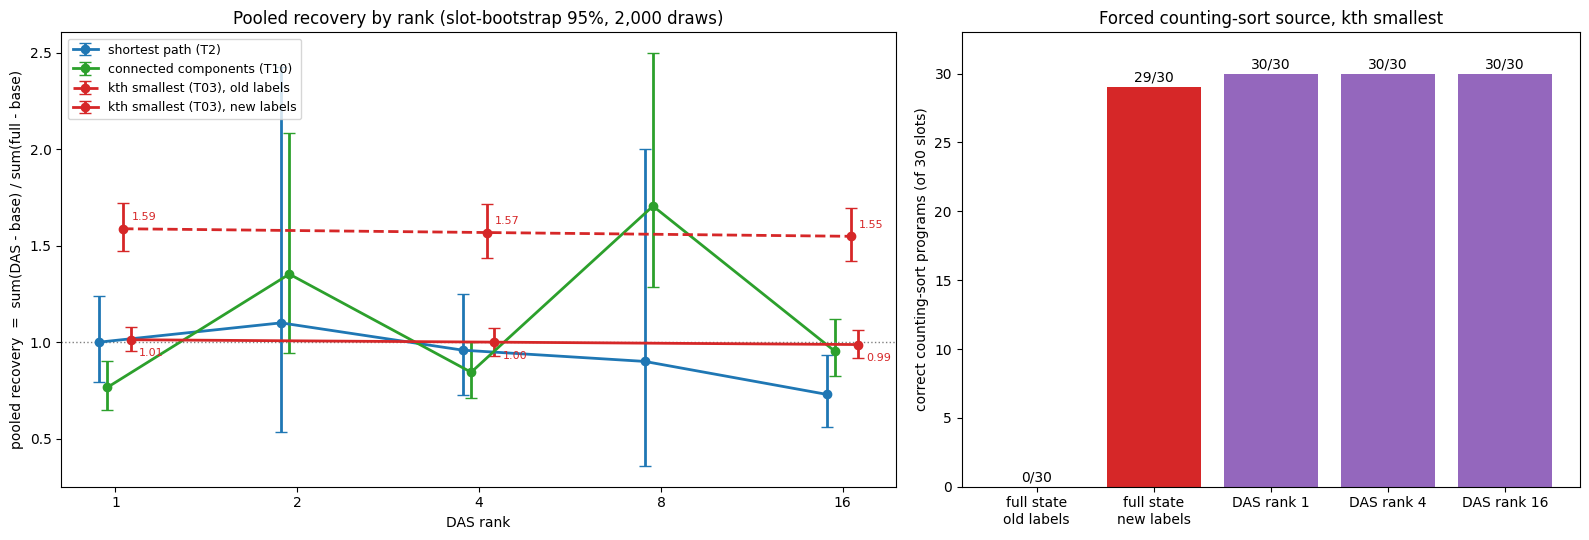

In [27]:
rc = _int_keys(read_json(RESULTS / "a5_recompute.json"))
ranks = [1, 2, 4, 8, 16]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.35, 1]})
series = [("shortest path (T2)", rc["old"]["T2"], "tab:blue", "-", 0.94), ("connected components (T10)", rc["old"]["T10"], "tab:green", "-", 0.97),
          ("kth smallest (T03), old labels", rc["old"]["T03"], "tab:red", "--", 1.03), ("kth smallest (T03), new labels", rc["new"]["T03"], "tab:red", "-", 1.06)]
for name, P, colr, ls, dx in series:
    ks = [k for k in ranks if P["per_k"][k]["recovery"] is not None]
    y = np.array([P["per_k"][k]["recovery"] for k in ks])
    lo = np.array([P["per_k"][k]["recovery_ci"][0] for k in ks])
    hi = np.array([P["per_k"][k]["recovery_ci"][1] for k in ks])
    ax1.errorbar(np.array(ks) * dx, y, yerr=[y - lo, hi - y], color=colr, ls=ls, marker="o", capsize=4, lw=2, label=name)
    for k, v in zip(ks, y):
        if "T03" in name:
            ax1.annotate(f"{v:.2f}", (k * dx, v), xytext=(6, -12 if "new" in name else 6), textcoords="offset points", fontsize=8, color=colr)
ax1.axhline(1.0, color="gray", ls=":", lw=1)
ax1.set_xscale("log", base=2)
ax1.set_xticks(ranks, [str(k) for k in ranks])
ax1.set_xlabel("DAS rank")
ax1.set_ylabel("pooled recovery  =  sum(DAS - base) / sum(full - base)")
ax1.set_title("Pooled recovery by rank (slot-bootstrap 95%, 2,000 draws)")
ax1.legend(fontsize=9, loc="upper left")

ro, rn, rd = rc["routing"]["old_full_counting"], rc["routing"]["new_full_counting"], rc["routing"]["new_das_counting"]
bars = [("full state\nold labels", ro["correct_Y"], "#bbbbbb"), ("full state\nnew labels", rn["correct_Y"], "tab:red"),
        ("DAS rank 1", rd["k1"]["correct_Y"], "tab:purple"), ("DAS rank 4", rd["k4"]["correct_Y"], "tab:purple"),
        ("DAS rank 16", rd["k16"]["correct_Y"], "tab:purple")]
b = ax2.bar([x[0] for x in bars], [x[1] for x in bars], color=[x[2] for x in bars])
for bb, (_, n, _) in zip(b, bars):
    ax2.text(bb.get_x() + bb.get_width() / 2, n + 0.4, f"{n}/30", ha="center")
ax2.set_ylim(0, 33)
ax2.set_ylabel("correct counting-sort programs (of 30 slots)")
ax2.set_title("Forced counting-sort source, kth smallest")
plt.tight_layout()
plt.show()

Below are two of the 30 programs of that full-state cell, with their labels before and after. The first is one of the 29 counting sorts in dictionary form: it counts values in a dictionary and walks the sorted keys until k is covered. The frozen rule called it `other`. The second is the one program that stays off counting sort, a binary search on the value range. The table then shows the implementation form item 0a found in every counting-sort cell, by regex on the code.

In [28]:
fl = read_json(RESULTS / "final_labels_T03.json")
cell = next(e for e in data["examples"] if e["task"] == "T03" and e["arm"] == "FULL_F_counting_sort")
print("FULL_F_counting_sort, (old label, new label) over its 30 slots:",
      dict(Counter((r["label"], fl[r["sample_id"]]) for r in cell["rows"])))
ex1 = next(r for r in cell["rows"] if r["label"] == "other" and fl[r["sample_id"]] == "counting_sort")
ex2 = next(r for r in cell["rows"] if fl[r["sample_id"]] != "counting_sort")
for r in (ex1, ex2):
    print(f"\n--- {r['sample_id']}: passed={r['passed']}, old label {r['label']!r} -> new label {fl[r['sample_id']]!r}")
    print(r["code"].rstrip())
if (RESULTS / "item_0a.json").exists():
    print("\nimplementation form of the counting sorts (item 0a, regex on the program text):")
    for arm, f in read_json(RESULTS / "item_0a.json")["summary"]["forms"].items():
        print(f"  {arm:28} {f}")

FULL_F_counting_sort, (old label, new label) over its 30 slots: {('other', 'counting_sort'): 29, ('quickselect', 'other'): 1}

--- T03|FULL_F_counting_sort|0: passed=True, old label 'other' -> new label 'counting_sort'
def solve(nums, k):
    count = {}
    for num in nums:
        count[num] = count.get(num, 0) + 1
    sorted_nums = sorted(count.keys())
    for num in sorted_nums:
        if k <= count[num]:
            return num
        k -= count[num]
    return -1

--- T03|FULL_F_counting_sort|11: passed=True, old label 'quickselect' -> new label 'other'
def solve(nums, k):
    def count_less_equal(x):
        return sum(1 for num in nums if num <= x)
    
    left, right = min(nums), max(nums)
    while left < right:
        mid = (left + right) // 2
        if count_less_equal(mid) < k:
            left = mid + 1
        else:
            right = mid
    return left

implementation form of the counting sorts (item 0a, regex on the program text):
  DASLY_F_counting_sort_k1     {'

### 3. Item 0b: recovery by source and rank (the new Table 297b)

Each cell gives the count of correct target-algorithm programs out of 30 and, in parentheses, the recovery against that source's own full-state exchange.
- Grey cells were never generated: forced sources ran at ranks 1, 4 and 16 only.
- Pooled recovery hides the spread. DAS matches or exceeds the full state for the ban sources and most forced sources. But it recovers only 0.17-0.43 of forced Bellman-Ford/SPFA and 0.06-0.53 of forced BFS.

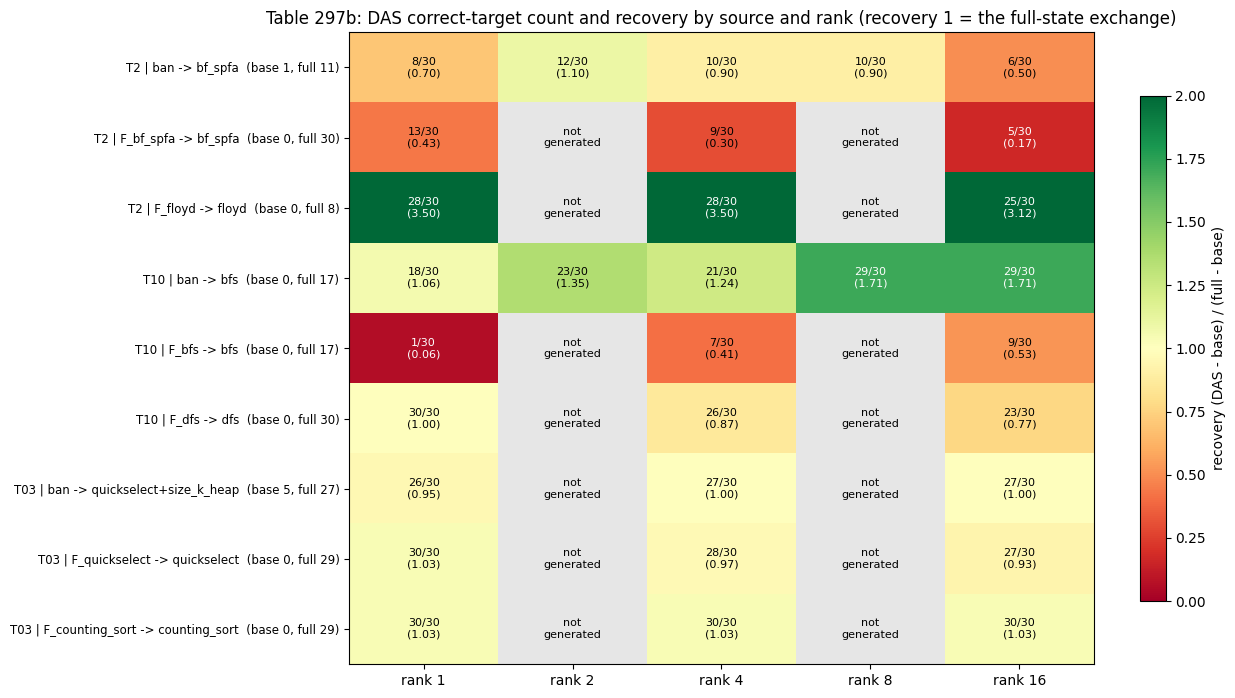

In [29]:
p = ROOT / "tables" / "recovery_by_source.csv"
if not p.exists():
    print("tables/recovery_by_source.csv not written: add 'b' to STAGES")
else:
    rows_ = list(csv.DictReader(p.open()))
    keys = list(dict.fromkeys((r["task"], r["source"], r["Y"], r["base"], r["full"]) for r in rows_))
    M = np.full((len(keys), 5), np.nan)
    txt = [["not\ngenerated"] * 5 for _ in keys]
    for r in rows_:
        i, j = keys.index((r["task"], r["source"], r["Y"], r["base"], r["full"])), ranks.index(int(r["rank"]))
        if r["generated"] == "y":
            txt[i][j] = f"{r['das_count']}/30\n({r['recovery']})" if r["recovery"] == "undefined" else f"{r['das_count']}/30\n({float(r['recovery']):.2f})"
            if r["recovery"] != "undefined":
                M[i, j] = float(r["recovery"])
    fig, ax = plt.subplots(figsize=(13, 0.62 * len(keys) + 1.5))
    cmap = plt.get_cmap("RdYlGn").copy()
    cmap.set_bad("#e6e6e6")
    im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=0, vmax=2, aspect="auto")
    for i in range(len(keys)):
        for j in range(5):
            ax.text(j, i, txt[i][j], ha="center", va="center", fontsize=8,
                    color="white" if not np.isnan(M[i, j]) and (M[i, j] > 1.6 or M[i, j] < 0.2) else "black")
    ax.set_xticks(range(5), [f"rank {k}" for k in ranks])
    ax.set_yticks(range(len(keys)), [f"{t} | {s} -> {y}  (base {b}, full {f})" for t, s, y, b, f in keys], fontsize=8.5)
    ax.set_title("Table 297b: DAS correct-target count and recovery by source and rank (recovery 1 = the full-state exchange)")
    fig.colorbar(im, ax=ax, label="recovery (DAS - base) / (full - base)", shrink=0.8)
    plt.tight_layout()
    plt.show()

### 4. Item 0j: the manifold claim in the actual activation geometry

The exp33 manifold file holds the rank-16 DAS coordinates of 151 shortest-path prompt states: twins, padded twins, forced prompts, bans, sham bans, seeds and instructions.

**(a) and (b).** The states plotted on the first two DAS coordinates, and in a metric MDS of all 16. Arrows run from the twins' mean state to each probe.

**(c)** places each probe against the paraphrase null, as its distance D from the twins' mean. Item 0j corrects two points:
- **The ban templates.** W1, W2 and W3 are training templates of the map (`TRAIN_W` in exp33's `cfg7.py`; hatched bars). So the claim that bans leave the null rests on the held-out W5 (D 2.62) and on W4 (D 1.73).
- **The semantic seed** is at the 93.9th percentile of the null, D 1.127 against a 95th percentile of 1.130. It sits on the boundary, not clearly inside.

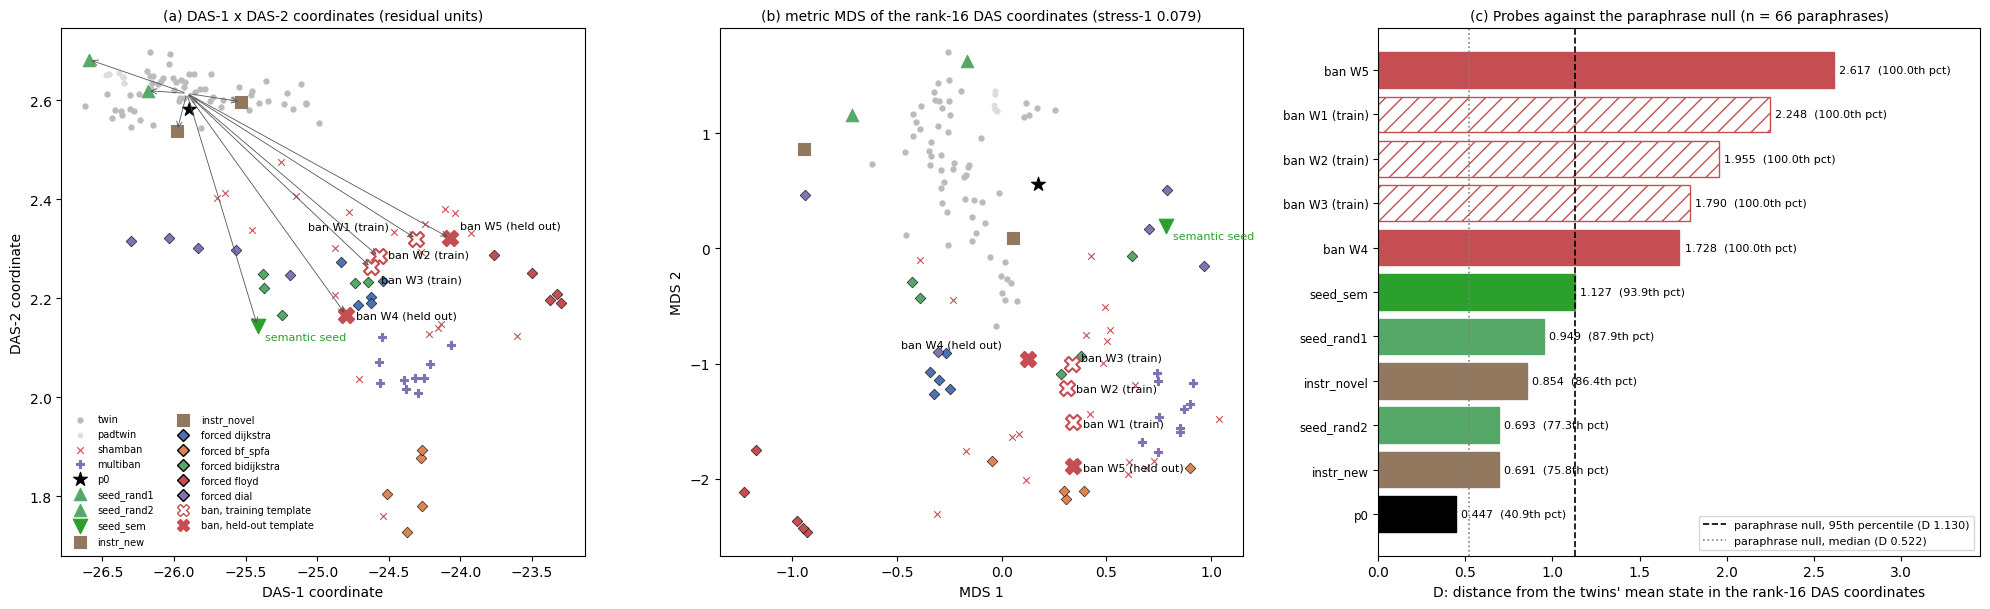

In [30]:
mm = json.loads((DEMO_REPO / "gen_art_experiment_33" / "results" / "m_manifold.json").read_text())
co = mm["coords"]
kinds, Ys, keys_ = np.array(co["kind"]), co["Y"], co["keys"]
COLY = {"dijkstra": "#4c72b0", "bf_spfa": "#dd8452", "bidijkstra": "#55a868", "floyd": "#c44e52", "dial": "#8172b3"}
style = {"twin": ("o", "#bbbbbb", 14), "padtwin": ("o", "#dddddd", 10), "shamban": ("x", "#c44e52", 22),
         "multiban": ("P", "#8172b3", 40), "p0": ("*", "k", 110), "seed_rand1": ("^", "#55a868", 80),
         "seed_rand2": ("^", "#55a868", 80), "seed_sem": ("v", "#2ca02c", 110), "instr_new": ("s", "#937860", 70),
         "instr_novel": ("s", "#937860", 70)}
fig, axes = plt.subplots(1, 3, figsize=(20, 6.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})
zb = np.array(co["zbar_das12"])
for ax, XY, title in ((axes[0], np.array(co["das12"]), "(a) DAS-1 x DAS-2 coordinates (residual units)"),
                      (axes[1], np.array(co["mds"]), f"(b) metric MDS of the rank-16 DAS coordinates (stress-1 {mm['mds_stress1']:.3f})")):
    for kd, (mk, colr, sz) in style.items():
        sel = kinds == kd
        if sel.any():
            ax.scatter(XY[sel, 0], XY[sel, 1], marker=mk, c=colr, s=sz, label=kd, lw=0.8)
    for i in np.where(kinds == "forced")[0]:
        ax.scatter(XY[i, 0], XY[i, 1], marker="D", s=30, c=COLY.get(Ys[i], "#333"), edgecolor="k", lw=0.4)
    off = ({"W1": (-78, 7), "W2": (7, -1), "W3": (7, -11), "W4": (7, -3), "W5": (7, 7)} if ax is axes[0] else
           {"W1": (7, -3), "W2": (7, -3), "W3": (7, 3), "W4": (-92, 8), "W5": (7, -3)})   # label offsets, chosen so labels do not overlap
    for i in np.where(kinds == "ban")[0]:
        w = keys_[i].split("|")[2]
        train = w in ("W1", "W2", "W3")
        ax.scatter(XY[i, 0], XY[i, 1], marker="X", s=120, c="white" if train else "#c44e52", edgecolor="#c44e52", lw=1.5)
        ax.annotate(f"ban {w}" + (" (train)" if train else " (held out)"), XY[i], xytext=off[w], textcoords="offset points", fontsize=8)
    for i in np.where(kinds == "seed_sem")[0]:
        ax.annotate("semantic seed", XY[i], xytext=(5, -10), textcoords="offset points", fontsize=8, color="#2ca02c")
    if ax is axes[0]:
        for i, kd in enumerate(kinds):
            if kd in ("ban", "seed_rand1", "seed_rand2", "seed_sem", "instr_new", "instr_novel"):
                ax.annotate("", xy=XY[i], xytext=zb, arrowprops=dict(arrowstyle="->", lw=0.6, color="#555"))
        ax.set_xlabel("DAS-1 coordinate"); ax.set_ylabel("DAS-2 coordinate")
    else:
        ax.set_xlabel("MDS 1"); ax.set_ylabel("MDS 2")
    ax.set_title(title, fontsize=10)
from matplotlib.lines import Line2D
hs, ls_ = axes[0].get_legend_handles_labels()
hs += [Line2D([], [], marker="D", ls="", color=c, markeredgecolor="k", ms=6) for c in COLY.values()]
ls_ += [f"forced {y}" for y in COLY]
hs += [Line2D([], [], marker="X", ls="", markerfacecolor="white", markeredgecolor="#c44e52", ms=9),
       Line2D([], [], marker="X", ls="", color="#c44e52", ms=9)]
ls_ += ["ban, training template", "ban, held-out template"]
axes[0].legend(hs, ls_, fontsize=7, ncol=2, loc="best", frameon=False)

pr = mm["probes"]
names = list(pr)
D = [pr[n]["D"] for n in names]
order = np.argsort(D)
colk = {"ban": "#c44e52", "p0": "k", "seed_rand1": "#55a868", "seed_rand2": "#55a868", "seed_sem": "#2ca02c",
        "instr_new": "#937860", "instr_novel": "#937860"}
ax = axes[2]
for j, i in enumerate(order):
    n = names[i]
    w = n.split("|")[2]
    train = pr[n]["kind"] == "ban" and w in ("W1", "W2", "W3")
    ax.barh(j, D[i], color="white" if train else colk[pr[n]["kind"]], edgecolor=colk[pr[n]["kind"]], hatch="//" if train else None)
    lbl = f"{pr[n]['kind']} {w}" if w != "-" else pr[n]["kind"]
    ax.text(D[i] + 0.03, j, f"{D[i]:.3f}  ({pr[n]['null_percentile']:.1f}th pct)", va="center", fontsize=8)
    names[i] = lbl + (" (train)" if train else "")
ax.set_yticks(range(len(order)), [names[i] for i in order], fontsize=8.5)
nul = mm["paraphrase_null"]
ax.axvline(nul["D_95"], color="k", ls="--", lw=1.2, label=f"paraphrase null, 95th percentile (D {nul['D_95']:.3f})")
ax.axvline(nul["D_median"], color="gray", ls=":", lw=1.2, label=f"paraphrase null, median (D {nul['D_median']:.3f})")
ax.set_xlim(0, max(D) * 1.32)
ax.set_xlabel("D: distance from the twins' mean state in the rank-16 DAS coordinates")
ax.set_title(f"(c) Probes against the paraphrase null (n = {nul['n']} paraphrases)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 5. Item 0d: the fork margin is a readout of the outcome, not a predictor of it

Connected components has 40 random push directions. For each, the plot sets the escape share (sampled programs that leave the default algorithm) against two quantities:
- **left:** the teacher-forced fork margin at the decision token;
- **right:** the 48-token opening log-likelihood ratio.

Both rank the pushes well (Spearman 0.80 and 0.87). But both are measured *where the outcome is already expressed*, so they read the outcome rather than predict it. Item 0d restates the claim accordingly. No property of the push direction itself predicted which pushes move the fork: the axis projection gives 0.17 and 0.01.

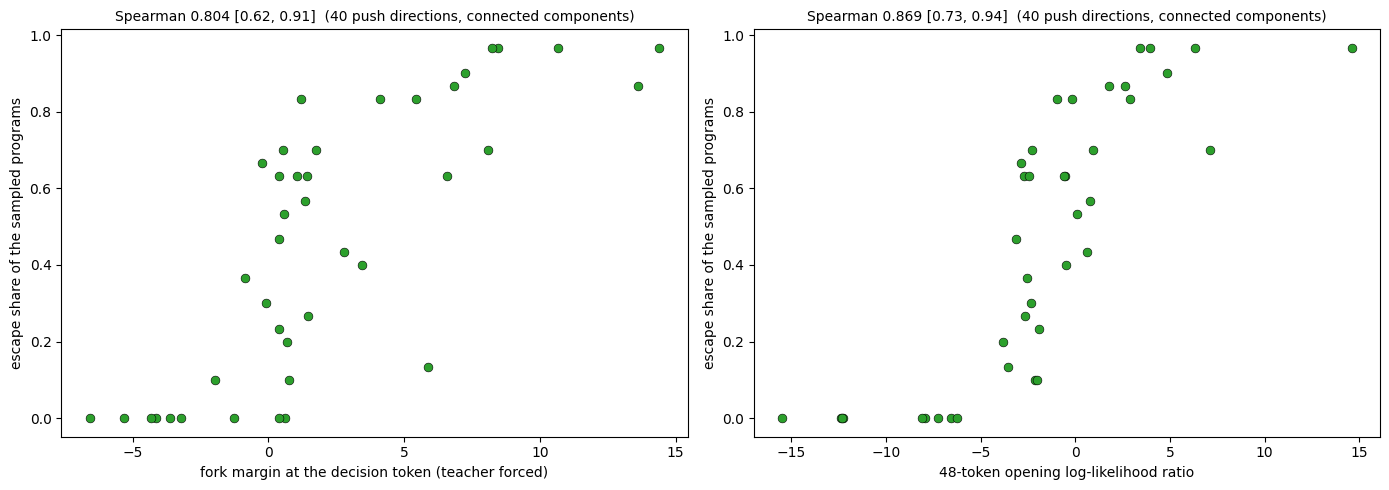

In [31]:
fa = json.loads((DEMO_REPO / "gen_art_experiment_34" / "results" / "f_analysis.json").read_text())["cells"]["T10"]
m_, y_, l_ = [c["m"] for c in fa], [c["y"] for c in fa], [c["llr48"] for c in fa]
sd = read_json(RESULTS / "item_0d.json")["summary"] if (RESULTS / "item_0d.json").exists() else None
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, nm, key in ((axes[0], m_, "fork margin at the decision token (teacher forced)", "rho_margin"),
                       (axes[1], l_, "48-token opening log-likelihood ratio", "rho_llr48")):
    ax.scatter(x, y_, s=40, c="tab:green", edgecolor="k", lw=0.4)
    rho = C.spearman(x, y_)
    ci = f" [{sd[key + '_ci'][0]:.2f}, {sd[key + '_ci'][1]:.2f}]" if sd else ""
    ax.set_title(f"Spearman {rho:.3f}{ci}  (40 push directions, connected components)", fontsize=10)
    ax.set_xlabel(nm)
    ax.set_ylabel("escape share of the sampled programs")
plt.tight_layout()
plt.show()

### 6. Items 0e and 0i: Gemma's natural variance, and search as rates

**Left (0e).** The share of the twin's natural variance across prompts that Gemma's DAS subspace holds at block 17, by rank, against random subspaces of the same rank. It lies **below** the random 95th percentile at ranks 1, 2 and 4, and above it only at rank 8. At block 22, rank 1 lies above it. The report had said "at the random 95th percentile".

**Right (0i).** Programs at search level b (known techniques outside the catalogue) per call, by arm, with Clopper-Pearson 95% intervals. Search finds 78 in 2,500 calls; the instruction alone finds 2 in 500. That is a rate ratio of 7.8, with a one-sided lower bound of 2.41, short of the committed 10x.

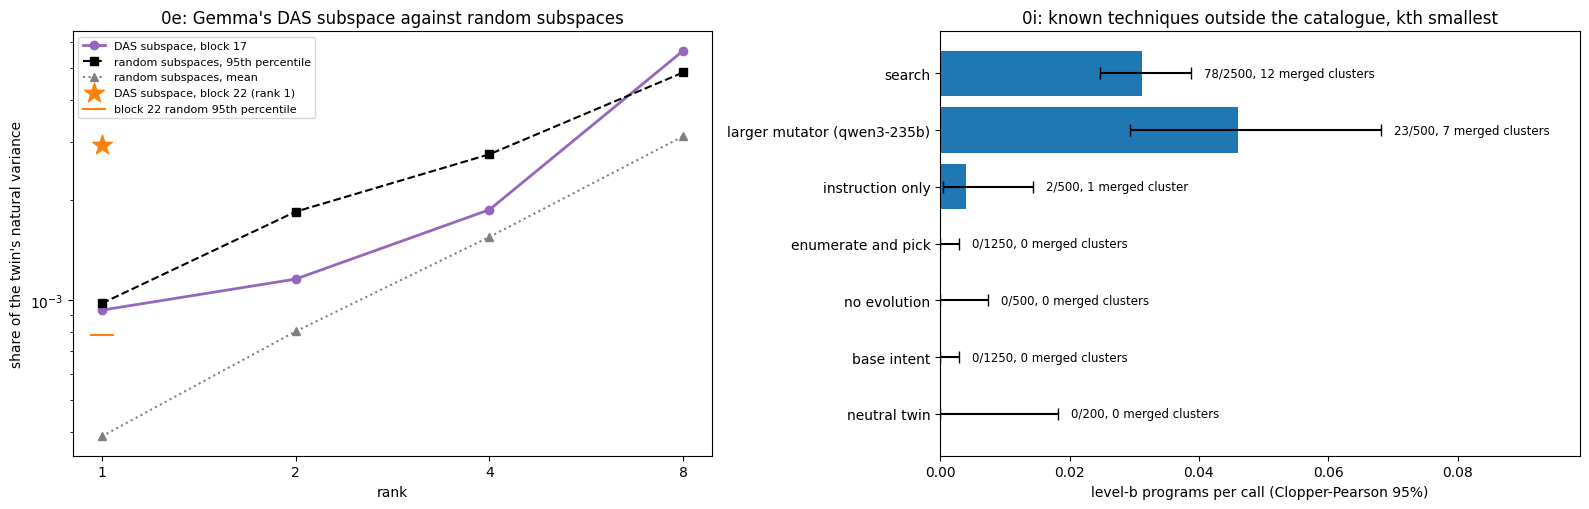

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2))
p = ROOT / "tables" / "gemma_natural_variance.csv"
if p.exists():
    g = list(csv.DictReader(p.open()))
    b17 = [r for r in g if r["block"] == "17"]
    rk = [int(r["rank"]) for r in b17]
    ax1.plot(rk, [float(r["share"]) for r in b17], "o-", color="tab:purple", lw=2, label="DAS subspace, block 17")
    ax1.plot(rk, [float(r["random_p95"]) for r in b17], "s--", color="k", label="random subspaces, 95th percentile")
    ax1.plot(rk, [float(r["random_mean"]) for r in b17], "^:", color="gray", label="random subspaces, mean")
    b22 = next(r for r in g if r["block"] == "22")
    ax1.scatter([1], [float(b22["share"])], marker="*", s=220, color="tab:orange", zorder=5, label="DAS subspace, block 22 (rank 1)")
    ax1.scatter([1], [float(b22["random_p95"])], marker="_", s=300, color="tab:orange", zorder=5, label="block 22 random 95th percentile")
    ax1.set_xscale("log", base=2); ax1.set_yscale("log")
    ax1.set_xticks(rk, [str(k) for k in rk])
    ax1.set_xlabel("rank"); ax1.set_ylabel("share of the twin's natural variance")
    ax1.set_title("0e: Gemma's DAS subspace against random subspaces")
    ax1.legend(fontsize=8)
else:
    ax1.text(0.5, 0.5, "add 'e' to STAGES", ha="center")
p = ROOT / "tables" / "search_by_arm.csv"
if p.exists():
    s_ = list(csv.DictReader(p.open()))[::-1]
    rate = np.array([float(r["rate"]) for r in s_])
    lo, hi = np.array([float(r["rate_cp95_lo"]) for r in s_]), np.array([float(r["rate_cp95_hi"]) for r in s_])
    ax2.barh(range(len(s_)), rate, xerr=[rate - lo, hi - rate], color="tab:blue", capsize=4)
    for i, r in enumerate(s_):
        nc = int(r["merged_clusters"])
        ax2.text(hi[i] + 0.002, i, f"{r['level_b_programs']}/{r['calls']}, {nc} merged cluster{'' if nc == 1 else 's'}", va="center", fontsize=8.5)
    ax2.set_yticks(range(len(s_)), [r["arm_name"] for r in s_])
    ax2.set_xlim(0, hi.max() * 1.45)
    ax2.set_xlabel("level-b programs per call (Clopper-Pearson 95%)")
    ax2.set_title("0i: known techniques outside the catalogue, kth smallest")
else:
    ax2.text(0.5, 0.5, "add 'i' to STAGES", ha="center")
plt.tight_layout()
plt.show()

### 7. The value ledger and the residual-claim lint

**Left.** The 141 traced values, by review item and status. **Right.** Each contradicted phrase, counted in the uncorrected report and in `report_corrected.md` after the 84 edits.

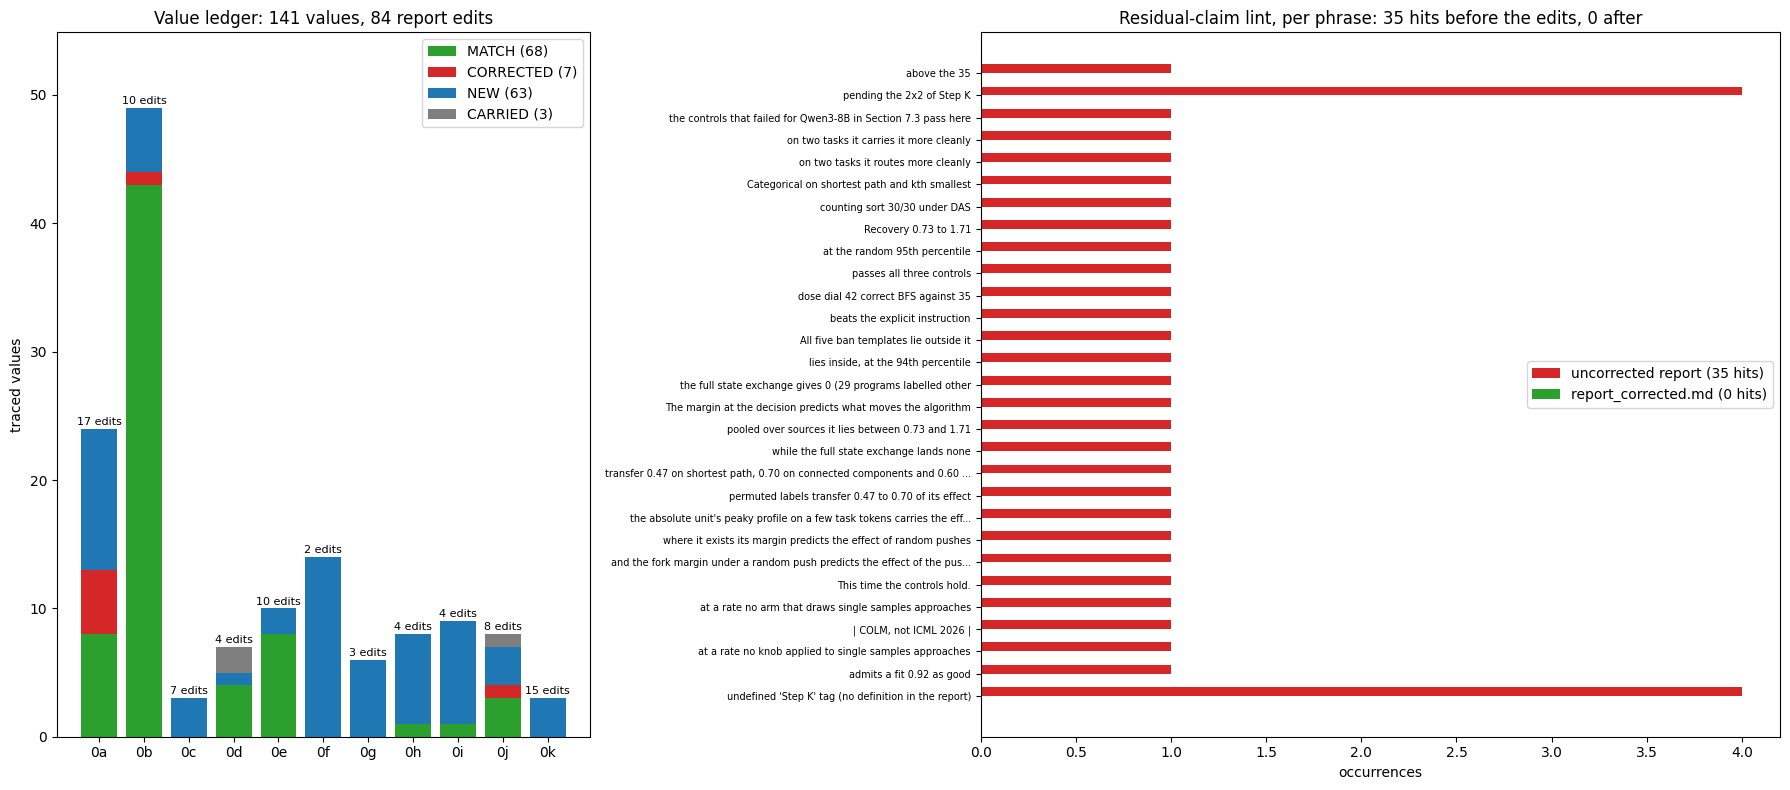

CORRECTED values:
  [0a] T03 forced counting sort: full state correct counting sort (of 30): recorded 0 -> recomputed 29
  [0a] T03 pooled recovery k1: recorded 1.59 -> recomputed 1.0125
  [0a] T03 pooled recovery k4: recorded 1.57 -> recomputed 1.0
  [0a] T03 pooled recovery k16: recorded 1.55 -> recomputed 0.9875
  [0a] Table 300 kth smallest | counting sort: full state routing: recorded 0.0 -> recomputed 0.9666666666666667
  [0b] T03 F_counting_sort full-state count: recorded 0 -> recomputed 29
  [0j] semantic seed null percentile: recorded 94.0 -> recomputed 93.93939393939394


In [33]:
cp_, lp = ROOT / "corrections.json", ROOT / "tables" / "lint.csv"
if not (cp_.exists() and lp.exists()):
    print("corrections.json / tables/lint.csv not written: run every item stage plus 'apply'")
else:
    corr_ = json.loads(cp_.read_text())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.5]})
    its = sorted({v["item"] for v in corr_["values"]})
    bottom = np.zeros(len(its))
    for st, colr in (("MATCH", "tab:green"), ("CORRECTED", "tab:red"), ("NEW", "tab:blue"), ("CARRIED", "tab:gray")):
        n = np.array([sum(v["item"] == it and v["status"] == st for v in corr_["values"]) for it in its])
        ax1.bar(its, n, bottom=bottom, color=colr, label=f"{st} ({n.sum()})")
        bottom += n
    for i, it in enumerate(its):
        ax1.text(i, bottom[i] + 0.3, f"{corr_['n_edits_by_item'][it]} edits", ha="center", fontsize=8)
    ax1.set_ylim(0, bottom.max() * 1.12)
    ax1.set_ylabel("traced values")
    ax1.set_title(f"Value ledger: {corr_['n_values']} values, {corr_['n_edits']} report edits")
    ax1.legend()
    L = list(csv.DictReader(lp.open()))
    y = np.arange(len(L))
    ax2.barh(y - 0.2, [int(r["before"]) for r in L], height=0.4, color="tab:red", label=f"uncorrected report ({sum(int(r['before']) for r in L)} hits)")
    ax2.barh(y + 0.2, [int(r["after"]) for r in L], height=0.4, color="tab:green", label=f"report_corrected.md ({sum(int(r['after']) for r in L)} hits)")
    lbl = lambda ph: "undefined 'Step K' tag (no definition in the report)" if ph == "__undefined_step_k__" else ph
    ax2.set_yticks(y, [(lbl(r["phrase"])[:70] + ("..." if len(lbl(r["phrase"])) > 70 else "")) for r in L], fontsize=7)
    ax2.invert_yaxis()
    ax2.set_xlabel("occurrences")
    ax2.set_title(f"Residual-claim lint, per phrase: {sum(int(r['before']) for r in L)} hits before the edits, "
                  f"{sum(int(r['after']) for r in L)} after")
    ax2.legend(loc="center right")
    plt.tight_layout()
    plt.show()
    print("CORRECTED values:")
    for v in corr_["values"]:
        if v["status"] == "CORRECTED":
            print(f"  [{v['item']}] {v['name']}: recorded {v['recorded']} -> recomputed {v['recomputed']}")

## Running the full evaluation

At `STAGES = "a,b,c,d,e,f,g,h,i,j,k,apply,audit,out"` the demo runs every stage of `eval.py` except `s0`, with the original parameters:
- the same slot bootstrap, Spearman bootstraps and placebo seeds;
- every item;
- all 84 edits;
- both audits.

The only things it does not recompute are the outputs of S0 and A1 to A4, which it reads from the full run.

The complete evaluation runs from the artifact folder, which holds `eval.py`, `sections/`, `labeller_v2/`, `audit/` and `inputs/`. It runs next to its six iteration-7 dependency folders:

```bash
uv sync                          # .venv from pyproject.toml / uv.lock (Python 3.12)
uv run eval.py --stages all      # about 25 s; judge calls are served from audit/judge_cache.jsonl, so no API key is needed
python3 -I audit/rederive.py     # either audit on its own
```

`--stages all` adds:
- **S0**: vendoring and hashing the 33 inputs;
- **A1 to A3**: the labeller validation and the relabel of all 960 kth-smallest programs, each traced in a sandboxed subprocess;
- **A4**: the gated two-judge adjudication. The judges are `deepseek/deepseek-chat-v3.1` and `mistralai/mistral-medium-3.1`. A fresh run without the cache needs `OPENROUTER_API_KEY` and cost USD 0.095.